# BCSE331P — Exploratory Data Analysis Lab

## Comprehensive Exploratory Data Analysis of the Hitters Dataset

| | |
|---|---|
| **Name** | N.Sai Shreyas |
| **Registration Number** | 23BDS0304 |
| **Course** | Exploratory Data Analysis Lab |
| **Course Code** | BCSE331P |
| **Faculty** | Dr. Balaji G N |
| **Class Number** | VL2026270102447 |
| **Dataset** | https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Hitters.csv |
| **Tools** | Python 3, Jupyter, pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn, statsmodels |


## 1. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, roc_auc_score, roc_curve, silhouette_score,
                             adjusted_rand_score, ConfusionMatrixDisplay)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 90
%matplotlib inline

## 2. Loading the Dataset

In [2]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Hitters.csv"
LOCAL = "Hitters.csv"

def load_data(url=URL, local=LOCAL):
    try:
        data = pd.read_csv(url)
        print("Loaded from URL")
    except Exception as e:
        print(f"URL failed ({e}); trying local file")
        data = pd.read_csv(local)
    return data

raw = load_data()
expected = {"AtBat","Hits","HmRun","Runs","RBI","Walks","Years","CAtBat","CHits","CHmRun","CRuns","CRBI","CWalks",
            "League","Division","PutOuts","Assists","Errors","Salary","NewLeague"}
missing_cols = expected - set(raw.columns)
if missing_cols:
    raise ValueError(f"Unexpected schema, missing: {missing_cols}")
df = raw.copy()
print(df.shape)

Loaded from URL
(322, 20)


In [3]:
df.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [4]:
df.tail()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
317,497,127,7,65,48,37,5,2703,806,32,379,311,138,N,E,325,9,3,700.0,N
318,492,136,5,76,50,94,12,5511,1511,39,897,451,875,A,E,313,381,20,875.0,A
319,475,126,3,61,43,52,6,1700,433,7,217,93,146,A,W,37,113,7,385.0,A
320,573,144,9,85,60,78,8,3198,857,97,470,420,332,A,E,1314,131,12,960.0,A
321,631,170,9,77,44,31,11,4908,1457,30,775,357,249,A,W,408,4,3,1000.0,A


In [5]:
df.sample(8, random_state=SEED)

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
173,161,43,4,17,26,22,3,707,179,21,77,99,76,A,W,300,12,2,NaN,A
132,278,70,7,22,37,18,18,7186,2081,190,935,1088,643,A,W,0,0,0,325.0,A
197,166,34,0,20,13,17,1,166,34,0,20,13,17,N,E,64,119,9,NaN,N
9,401,92,17,49,66,65,13,5206,1332,253,784,890,866,A,E,0,0,0,1100.0,A
104,397,114,23,67,67,53,13,5589,1632,241,906,926,716,A,E,244,2,4,NaN,A
119,327,85,3,30,44,20,8,2140,568,16,216,208,93,A,E,91,185,12,362.5,A
256,205,52,8,31,27,17,12,5134,1323,56,643,445,459,A,E,155,3,2,400.0,A
158,336,93,9,35,46,23,15,5779,1610,128,730,741,497,A,W,0,0,0,NaN,A


In [6]:
print("Shape:", df.shape)
print("Observations:", df.shape[0], "| Variables:", df.shape[1])
print("Columns:", list(df.columns))

Shape: (322, 20)
Observations: 322 | Variables: 20
Columns: ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'League', 'Division', 'PutOuts', 'Assists', 'Errors', 'Salary', 'NewLeague']


In [7]:
df.dtypes.to_frame('dtype').T

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str,str,int64,int64,int64,float64,str


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AtBat      322 non-null    int64  
 1   Hits       322 non-null    int64  
 2   HmRun      322 non-null    int64  
 3   Runs       322 non-null    int64  
 4   RBI        322 non-null    int64  
 5   Walks      322 non-null    int64  
 6   Years      322 non-null    int64  
 7   CAtBat     322 non-null    int64  
 8   CHits      322 non-null    int64  
 9   CHmRun     322 non-null    int64  
 10  CRuns      322 non-null    int64  
 11  CRBI       322 non-null    int64  
 12  CWalks     322 non-null    int64  
 13  League     322 non-null    str    
 14  Division   322 non-null    str    
 15  PutOuts    322 non-null    int64  
 16  Assists    322 non-null    int64  
 17  Errors     322 non-null    int64  
 18  Salary     263 non-null    float64
 19  NewLeague  322 non-null    str    
dtypes: float64(1), int64(

In [9]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numeric   :", num_cols)
print("Categorical:", cat_cols)
print(f"Memory usage: {df.memory_usage(deep=True).sum()/1024:.1f} KB")
print("Duplicate rows:", df.duplicated().sum())

Numeric   : ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'PutOuts', 'Assists', 'Errors', 'Salary']
Categorical: ['League', 'Division', 'NewLeague']
Memory usage: 90.1 KB
Duplicate rows: 0


In [10]:
pd.DataFrame({c: {"cardinality": df[c].nunique(), "levels": sorted(df[c].dropna().unique().tolist())} for c in cat_cols}).T

,cardinality,levels
League,2,"[A, N]"
Division,2,"[E, W]"
NewLeague,2,"[A, N]"


In [11]:
df.nunique().to_frame('unique_values').T

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
unique_values,247,144,36,96,103,89,22,314,288,146,261,262,248,2,2,232,161,29,150,2


## 3. Data Dictionary

In [12]:
desc = {
 "AtBat":"Times at bat in 1986", "Hits":"Hits in 1986", "HmRun":"Home runs in 1986", "Runs":"Runs in 1986",
 "RBI":"Runs batted in, 1986", "Walks":"Walks in 1986", "Years":"Years in the major leagues",
 "CAtBat":"Career times at bat", "CHits":"Career hits", "CHmRun":"Career home runs", "CRuns":"Career runs",
 "CRBI":"Career runs batted in", "CWalks":"Career walks", "League":"League at end of 1986 (A/N)",
 "Division":"Division at end of 1986 (E/W)", "PutOuts":"Put outs in 1986", "Assists":"Assists in 1986",
 "Errors":"Errors in 1986", "Salary":"1987 opening-day salary (thousands of USD)", "NewLeague":"League at start of 1987 (A/N)"}
role = {c: ("Target (continuous)" if c=="Salary" else "Predictor") for c in df.columns}
dd = pd.DataFrame({"dtype": df.dtypes.astype(str), "type": ["Numeric" if c in num_cols else "Categorical" for c in df.columns],
                   "role": pd.Series(role), "n_unique": df.nunique(), "n_missing": df.isna().sum(),
                   "description": pd.Series(desc)})
dd

,dtype,type,role,n_unique,n_missing,description
AtBat,int64,Numeric,Predictor,247,0,Times at bat in 1986
Hits,int64,Numeric,Predictor,144,0,Hits in 1986
HmRun,int64,Numeric,Predictor,36,0,Home runs in 1986
Runs,int64,Numeric,Predictor,96,0,Runs in 1986
RBI,int64,Numeric,Predictor,103,0,"Runs batted in, 1986"
Walks,int64,Numeric,Predictor,89,0,Walks in 1986
Years,int64,Numeric,Predictor,22,0,Years in the major leagues
CAtBat,int64,Numeric,Predictor,314,0,Career times at bat
CHits,int64,Numeric,Predictor,288,0,Career hits
CHmRun,int64,Numeric,Predictor,146,0,Career home runs


Definitions follow the ISLR `Hitters` documentation (Carnegie Mellon StatLib, 1988 ASA Graphics Section). No player-name/identifier column is present in this CSV. `Salary` is the natural outcome; there is no native class label, so classification later uses an engineered target.

## 4. Data Quality Assessment and Cleaning

In [13]:
def missing_report(d):
    m = d.isna().sum()
    return pd.DataFrame({"missing": m, "percent": (m / len(d) * 100).round(2)}).sort_values("missing", ascending=False)

mr = missing_report(df)
print("Total missing cells:", int(df.isna().sum().sum()), f"({df.isna().sum().sum()/df.size*100:.2f}% of all cells)")
mr.T

Total missing cells: 59 (0.92% of all cells)


,Salary,AtBat,Hits,Errors,Assists,PutOuts,Division,League,CWalks,CRBI,CRuns,CHmRun,CHits,CAtBat,Years,Walks,RBI,Runs,HmRun,NewLeague
missing,59.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
percent,18.32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


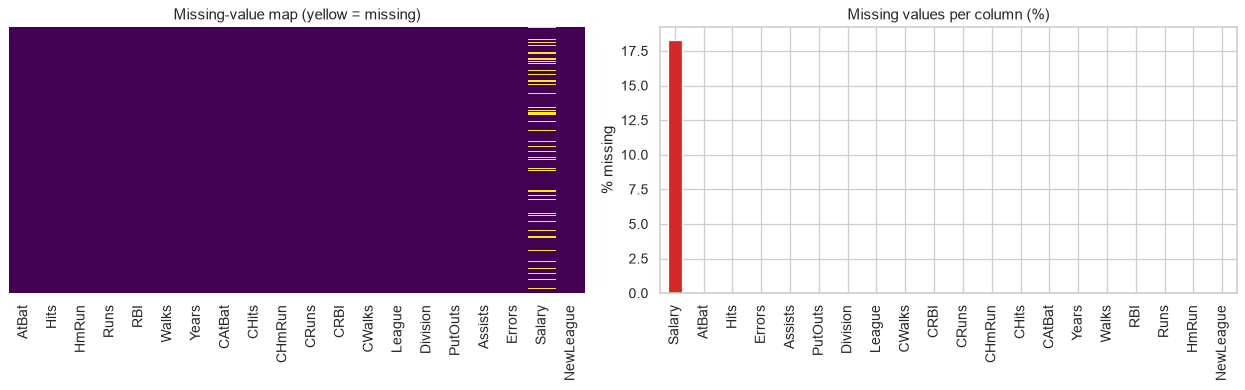

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", ax=axes[0], yticklabels=False)
axes[0].set_title("Missing-value map (yellow = missing)")
mr["percent"].plot.bar(ax=axes[1], color="tab:red")
axes[1].set_title("Missing values per column (%)"); axes[1].set_ylabel("% missing")
plt.tight_layout(); plt.show()

In [15]:
checks = {
 "negative values": (df[num_cols] < 0).sum().sum(),
 "Hits > AtBat": (df.Hits > df.AtBat).sum(),
 "CHits > CAtBat": (df.CHits > df.CAtBat).sum(),
 "season > career (AtBat)": (df.AtBat > df.CAtBat).sum(),
 "season > career (Hits)": (df.Hits > df.CHits).sum(),
 "season > career (HmRun)": (df.HmRun > df.CHmRun).sum(),
 "season > career (Runs)": (df.Runs > df.CRuns).sum(),
 "season > career (RBI)": (df.RBI > df.CRBI).sum(),
 "season > career (Walks)": (df.Walks > df.CWalks).sum(),
 "HmRun > Hits": (df.HmRun > df.Hits).sum(),
 "Years < 1": (df.Years < 1).sum(),
 "League != NewLeague": (df.League != df.NewLeague).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
negative values,0
Hits > AtBat,0
CHits > CAtBat,0
season > career (AtBat),0
season > career (Hits),0
season > career (HmRun),0
season > career (Runs),0
season > career (RBI),0
season > career (Walks),0
HmRun > Hits,0


In [16]:
qual = pd.DataFrame({
  "top_freq_ratio": [df[c].value_counts(normalize=True).iloc[0] for c in df.columns],
  "n_unique": df.nunique().values}, index=df.columns)
qual["near_constant"] = qual.top_freq_ratio > 0.95
skew = df[num_cols].skew().sort_values(ascending=False)
qual = qual.join(skew.rename("skewness"))
qual["highly_skewed(|s|>1)"] = qual.skewness.abs() > 1
qual

,top_freq_ratio,n_unique,near_constant,skewness,highly_skewed(|s|>1)
AtBat,0.012,247,False,-0.078,False
Hits,0.019,144,False,0.291,False
HmRun,0.068,36,False,0.905,False
Runs,0.037,96,False,0.416,False
RBI,0.040,103,False,0.608,False
Walks,0.040,89,False,0.620,False
Years,0.112,22,False,0.780,False
CAtBat,0.006,314,False,1.227,True
CHits,0.009,288,False,1.356,True
CHmRun,0.031,146,False,2.163,True


In [17]:
clean = df.copy()
for c in cat_cols:
    clean[c] = clean[c].astype("category")
clean["SalaryMissing"] = clean["Salary"].isna()
print("Cleaned copy:", clean.shape, "| original untouched:", df.shape)
clean.dtypes.value_counts()

Cleaned copy: (322, 21) | original untouched: (322, 20)


int64       16
category     2
category     1
float64      1
bool         1
Name: count, dtype: int64

Cleaning decisions: no duplicates or logically impossible values were found, so no rows are dropped; categorical codes are converted to `category`; `Salary` NAs are kept and flagged (handled in Section 7); the original `df` is preserved.

## 5. Basic Exploratory Data Analysis

In [18]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
AtBat,322.0,380.929,153.405,16.0,255.25,379.5,512.00,687.0
Hits,322.0,101.025,46.455,1.0,64.00,96.0,137.00,238.0
HmRun,322.0,10.770,8.709,0.0,4.00,8.0,16.00,40.0
Runs,322.0,50.910,26.024,0.0,30.25,48.0,69.00,130.0
RBI,322.0,48.028,26.167,0.0,28.00,44.0,64.75,121.0
Walks,322.0,38.742,21.639,0.0,22.00,35.0,53.00,105.0
Years,322.0,7.444,4.926,1.0,4.00,6.0,11.00,24.0
CAtBat,322.0,2648.683,2324.206,19.0,816.75,1928.0,3924.25,14053.0
CHits,322.0,717.571,654.473,4.0,209.00,508.0,1059.25,4256.0
CHmRun,322.0,69.491,86.266,0.0,14.00,37.5,90.00,548.0


In [19]:
df[num_cols].describe(percentiles=[.01,.05,.1,.25,.5,.75,.9,.95,.99]).T

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
AtBat,322.0,380.929,153.405,16.0,20.42,161.00,194.1,255.25,379.5,512.00,584.900,609.90,658.590,687.0
Hits,322.0,101.025,46.455,1.0,4.42,39.00,45.1,64.00,96.0,137.00,163.000,174.00,210.790,238.0
HmRun,322.0,10.770,8.709,0.0,0.00,0.00,1.0,4.00,8.0,16.00,24.000,28.95,33.000,40.0
Runs,322.0,50.910,26.024,0.0,1.21,17.00,20.1,30.25,48.0,69.00,89.000,94.00,107.790,130.0
RBI,322.0,48.028,26.167,0.0,2.00,14.00,19.0,28.00,44.0,64.75,86.000,96.00,112.370,121.0
Walks,322.0,38.742,21.639,0.0,1.00,11.05,15.0,22.00,35.0,53.00,69.900,78.00,93.580,105.0
Years,322.0,7.444,4.926,1.0,1.00,1.00,2.0,4.00,6.0,11.00,15.000,17.00,19.790,24.0
CAtBat,322.0,2648.683,2324.206,19.0,41.00,216.50,342.2,816.75,1928.0,3924.25,6123.400,7125.60,8749.970,14053.0
CHits,322.0,717.571,654.473,4.0,9.84,54.00,86.0,209.00,508.0,1059.25,1659.600,2017.15,2500.340,4256.0
CHmRun,322.0,69.491,86.266,0.0,0.00,2.00,4.0,14.00,37.5,90.00,194.900,265.65,373.120,548.0


In [20]:
df[cat_cols].describe().T

,count,unique,top,freq
League,322,2,A,175
Division,322,2,W,165
NewLeague,322,2,A,176


In [21]:
def summary_table(d):
    out = pd.DataFrame({
        "count": d.count(), "mean": d.mean(), "median": d.median(), "mode": d.mode().iloc[0],
        "min": d.min(), "max": d.max(), "range": d.max() - d.min(),
        "var": d.var(), "std": d.std(), "Q1": d.quantile(.25), "Q3": d.quantile(.75)})
    out["IQR"] = out.Q3 - out.Q1
    out["CV"] = out["std"] / out["mean"]
    return out
summary_table(df[num_cols])

,count,mean,median,mode,min,max,range,var,std,Q1,Q3,IQR,CV
AtBat,322,380.929,379.5,209.0,16.0,687.0,671.0,2.353e+04,153.405,255.25,512.00,256.75,0.403
Hits,322,101.025,96.0,53.0,1.0,238.0,237.0,2.158e+03,46.455,64.00,137.00,73.00,0.460
HmRun,322,10.770,8.0,4.0,0.0,40.0,40.0,7.585e+01,8.709,4.00,16.00,12.00,0.809
Runs,322,50.910,48.0,42.0,0.0,130.0,130.0,6.773e+02,26.024,30.25,69.00,38.75,0.511
RBI,322,48.028,44.0,29.0,0.0,121.0,121.0,6.847e+02,26.167,28.00,64.75,36.75,0.545
Walks,322,38.742,35.0,22.0,0.0,105.0,105.0,4.683e+02,21.639,22.00,53.00,31.00,0.559
Years,322,7.444,6.0,4.0,1.0,24.0,23.0,2.427e+01,4.926,4.00,11.00,7.00,0.662
CAtBat,322,2648.683,1928.0,41.0,19.0,14053.0,14034.0,5.402e+06,2324.206,816.75,3924.25,3107.50,0.877
CHits,322,717.571,508.0,160.0,4.0,4256.0,4252.0,4.283e+05,654.473,209.00,1059.25,850.25,0.912
CHmRun,322,69.491,37.5,32.0,0.0,548.0,548.0,7.442e+03,86.266,14.00,90.00,76.00,1.241


In [22]:
for c in cat_cols:
    vc = pd.concat([df[c].value_counts(), df[c].value_counts(normalize=True).mul(100).round(2)], axis=1, keys=["count","percent"])
    print(f"--- {c} ---"); print(vc, end="\n\n")

--- League ---
        count  percent
League                
A         175    54.35
N         147    45.65

--- Division ---
          count  percent
Division                
W           165    51.24
E           157    48.76

--- NewLeague ---
           count  percent
NewLeague                
A            176    54.66
N            146    45.34



In [23]:
df.groupby('League', observed=True)[num_cols].mean().T

League,A,N
AtBat,395.200,363.939
Hits,105.320,95.912
HmRun,12.183,9.088
Runs,54.491,46.646
RBI,51.514,43.878
Walks,39.640,37.673
Years,7.657,7.190
CAtBat,2709.806,2575.918
CHits,733.017,699.184
CHmRun,77.257,60.245


In [24]:
df.groupby('Division', observed=True)[num_cols].median().T

Division,E,W
AtBat,394.000,374.0
Hits,100.000,95.0
HmRun,9.000,8.0
Runs,49.000,46.0
RBI,46.000,42.0
Walks,36.000,34.0
Years,6.000,6.0
CAtBat,2131.000,1750.0
CHits,568.000,462.0
CHmRun,40.000,36.0


In [25]:
df.groupby(['League','Division'], observed=True)['Salary'].agg(['count','mean','median','std','min','max'])

count     mean  median      std   min       max
League Division                                                 
A      E            68  670.850   532.5  543.491  67.5  2460.000
       W            71  418.594   325.0  334.031  68.0  1500.000
N      E            61  572.348   450.0  509.663  70.0  2127.333
       W            63  487.259   450.0  352.120  75.0  1900.000

In [26]:
df.groupby(pd.cut(df.Years, [0,3,6,10,15,25]), observed=True)[['Salary','Hits','HmRun','CHits','CRuns']].agg(['mean','median']).round(1)

Salary          Hits        HmRun          CHits           CRuns       
           mean median   mean median  mean median    mean  median    mean median
Years                                                                           
(0, 3]    181.4  120.0   85.0   81.5   9.6    6.5   135.2   111.0    69.4   58.0
(3, 6]    504.3  392.5  110.9  102.0  10.8    8.0   405.0   365.0   203.3  195.5
(6, 10]   727.2  704.2  105.2  108.0  10.1    8.0   754.5   760.5   375.6  350.5
(10, 15]  813.2  737.5  107.4  105.0  12.3    9.0  1363.9  1375.5   682.8  702.5
(15, 25]  603.5  517.5   86.6   77.0  12.2   12.0  2038.8  1950.5  1013.4  986.5

In [27]:
pd.crosstab(df.League, df.Division, margins=True)

Division,E,W,All
League,,,
A,85,90,175
N,72,75,147
All,157,165,322


In [28]:
pd.crosstab(df.League, df.NewLeague, margins=True)

NewLeague,A,N,All
League,,,
A,166,9,175
N,10,137,147
All,176,146,322


In [29]:
pd.crosstab(df.Division, df.Salary.isna().rename('SalaryMissing'), normalize='index').round(3)

SalaryMissing,False,True
Division,,
E,0.822,0.178
W,0.812,0.188


## 6. Data Transformation and Pre-processing (Experiment 1)

| Method | Formula | Target range |
|---|---|---|
| Min-max | $x' = (x-x_{min})/(x_{max}-x_{min})$ | [0, 1] |
| Symmetric min-max | $x' = 2(x-x_{min})/(x_{max}-x_{min}) - 1$ | [-1, +1] |
| Z-score | $z = (x-\mu)/\sigma$ | ~[-3, +3] (not guaranteed) |
| Robust | $(x-\text{median})/\text{IQR}$ | centred on 0 |
| Log | $\log(1+x)$ | compresses right skew |

### 6.1 Reading data from the keyboard (optional)
Set `INTERACTIVE = True` to type numbers; otherwise a default vector is used so the notebook runs non-interactively.

In [30]:
INTERACTIVE = False

def read_numbers(prompt, default):
    if not INTERACTIVE:
        return np.array(default, dtype=float)
    txt = input(prompt)
    try:
        vals = np.array([float(t) for t in txt.replace(",", " ").split()])
        return vals if vals.size else np.array(default, dtype=float)
    except ValueError:
        print("Invalid input, using default"); return np.array(default, dtype=float)

x = read_numbers("Enter numbers separated by spaces: ", [12, 7, 3, 25, 18, 9, 30, 4, 15, 21])

def to_range(v, a, b):
    rng = v.max() - v.min()
    if rng == 0:
        return np.full_like(v, (a + b) / 2, dtype=float)
    return a + (v - v.min()) * (b - a) / rng

def zscore(v):
    s = v.std(ddof=0)
    return np.zeros_like(v, dtype=float) if s == 0 else (v - v.mean()) / s

kb = pd.DataFrame({"x": x, "[0,1]": to_range(x, 0, 1), "[-1,+1]": to_range(x, -1, 1),
                   "[-3,+3] (min-max)": to_range(x, -3, 3), "z-score": zscore(x)})
kb

,x,"[0,1]","[-1,+1]","[-3,+3] (min-max)",z-score
0,12.0,0.333,-0.333,-1.000,-0.279
1,7.0,0.148,-0.704,-2.111,-0.860
2,3.0,0.000,-1.000,-3.000,-1.325
3,25.0,0.815,0.630,1.889,1.232
4,18.0,0.556,0.111,0.333,0.418
5,9.0,0.222,-0.556,-1.667,-0.628
6,30.0,1.000,1.000,3.000,1.813
7,4.0,0.037,-0.926,-2.778,-1.209
8,15.0,0.444,-0.111,-0.333,0.070
9,21.0,0.667,0.333,1.000,0.767


In [31]:
kb.describe().loc[['mean','std','min','max']]

,x,"[0,1]","[-1,+1]","[-3,+3] (min-max)",z-score
mean,14.40,0.422,-0.156,-0.467,-5.551e-17
std,9.07,0.336,0.672,2.016,1.054e+00
min,3.00,0.000,-1.000,-3.000,-1.325e+00
max,30.00,1.000,1.000,3.000,1.813e+00


### 6.2 Transformations on the Hitters numeric variables

In [32]:
X_num = df[num_cols].drop(columns="Salary")
const_cols = [c for c in X_num if X_num[c].nunique() <= 1]
print("Constant columns:", const_cols, "| missing in predictors:", int(X_num.isna().sum().sum()), "| negatives:", int((X_num < 0).sum().sum()))

scalers = {
  "MinMax [0,1]": MinMaxScaler((0, 1)),
  "MinMax [-1,1]": MinMaxScaler((-1, 1)),
  "MinMax [-3,3]": MinMaxScaler((-3, 3)),
  "Standard (z)": StandardScaler(),
  "Robust": RobustScaler(),
}
transformed = {name: pd.DataFrame(s.fit_transform(X_num), columns=X_num.columns) for name, s in scalers.items()}
transformed["Log1p"] = np.log1p(X_num)
transformed["Sqrt"] = np.sqrt(X_num)

pd.DataFrame({n: {"min": t.values.min(), "max": t.values.max(), "mean": t.values.mean(), "std": t.values.std()} for n, t in transformed.items()}).T

Constant columns: [] | missing in predictors: 0 | negatives: 0


,min,max,mean,std
"MinMax [0,1]",0.000,1.000,2.727e-01,0.230
"MinMax [-1,1]",-1.000,1.000,-4.545e-01,0.461
"MinMax [-3,3]",-3.000,3.000,-1.364e+00,1.382
Standard (z),-2.383,5.556,-3.008e-17,1.000
Robust,-1.416,6.717,2.293e-01,0.848
Log1p,0.000,9.551,4.281e+00,1.848
Sqrt,0.000,118.545,1.276e+01,13.280


In [33]:
for name in ["MinMax [0,1]", "MinMax [-1,1]", "Standard (z)", "Robust"]:
    print(f"=== {name} ===")
    display(transformed[name].head().round(3))

=== MinMax [0,1] ===


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors
0,0.413,0.274,0.025,0.231,0.240,0.133,0.000,0.020,0.015,0.002,0.013,0.017,0.009,0.324,0.067,0.625
1,0.446,0.338,0.175,0.185,0.314,0.371,0.565,0.244,0.195,0.126,0.148,0.250,0.239,0.459,0.087,0.312
2,0.690,0.544,0.450,0.508,0.595,0.724,0.087,0.114,0.107,0.115,0.103,0.160,0.168,0.639,0.167,0.438
3,0.715,0.591,0.500,0.500,0.645,0.352,0.435,0.400,0.369,0.411,0.382,0.505,0.226,0.145,0.022,0.094
4,0.455,0.363,0.250,0.300,0.347,0.286,0.043,0.027,0.023,0.022,0.022,0.028,0.021,0.584,0.081,0.125


=== MinMax [-1,1] ===


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors
0,-0.174,-0.451,-0.95,-0.538,-0.521,-0.733,-1.000,-0.961,-0.971,-0.996,-0.973,-0.965,-0.982,-0.353,-0.866,0.250
1,-0.109,-0.325,-0.65,-0.631,-0.372,-0.257,0.130,-0.511,-0.609,-0.748,-0.704,-0.501,-0.521,-0.083,-0.825,-0.375
2,0.380,0.089,-0.10,0.015,0.190,0.448,-0.826,-0.771,-0.787,-0.770,-0.794,-0.679,-0.664,0.277,-0.667,-0.125
3,0.431,0.181,0.00,0.000,0.289,-0.295,-0.130,-0.201,-0.261,-0.179,-0.236,0.010,-0.548,-0.710,-0.955,-0.812
4,-0.091,-0.274,-0.50,-0.400,-0.306,-0.429,-0.913,-0.946,-0.954,-0.956,-0.957,-0.945,-0.958,0.168,-0.837,-0.750


=== Standard (z) ===


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors
0,-0.574,-0.755,-1.124,-0.805,-0.728,-1.145,-1.310,-1.015,-0.997,-0.795,-0.986,-0.905,-0.923,0.560,-0.541,1.881
1,-0.430,-0.432,-0.434,-1.036,-0.384,0.012,1.333,0.345,0.180,-0.006,-0.113,0.252,0.430,1.224,-0.468,0.308
2,0.640,0.625,0.831,0.581,0.918,1.724,-0.904,-0.442,-0.399,-0.075,-0.404,-0.193,0.010,2.109,-0.182,0.937
3,0.751,0.862,1.061,0.542,1.147,-0.081,0.723,1.284,1.312,1.805,1.407,1.527,0.352,-0.317,-0.702,-0.793
4,-0.391,-0.302,-0.089,-0.458,-0.231,-0.405,-1.107,-0.971,-0.944,-0.667,-0.932,-0.854,-0.852,1.841,-0.490,-0.635


=== Robust ===


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors
0,-0.337,-0.411,-0.583,-0.465,-0.408,-0.677,-0.714,-0.526,-0.520,-0.480,-0.509,-0.567,-0.575,1.085,-0.041,1.750
1,-0.251,-0.205,-0.083,-0.619,-0.163,0.129,1.143,0.489,0.385,0.414,0.174,0.573,0.752,1.947,0.022,0.500
2,0.388,0.466,0.833,0.465,0.762,1.323,-0.429,-0.098,-0.060,0.336,-0.054,0.135,0.340,3.096,0.267,1.000
3,0.454,0.616,1.000,0.439,0.925,0.065,0.714,1.191,1.255,2.467,1.364,1.830,0.675,-0.056,-0.179,-0.375
4,-0.228,-0.123,0.167,-0.232,-0.054,-0.161,-0.571,-0.493,-0.479,-0.336,-0.467,-0.517,-0.506,2.749,0.003,-0.250


In [34]:
mm = MinMaxScaler().fit(X_num)
back = mm.inverse_transform(mm.transform(X_num))
print("Inverse of [0,1] scaling recovers original data:", np.allclose(back, X_num.values))
pd.DataFrame({"Hits original": X_num.Hits.head().values,
              "scaled [0,1]": mm.transform(X_num)[:5, X_num.columns.get_loc("Hits")], "inverse": back[:5, X_num.columns.get_loc("Hits")]})

Inverse of [0,1] scaling recovers original data: True


,Hits original,"scaled [0,1]",inverse
0,66,0.274,66.0
1,81,0.338,81.0
2,130,0.544,130.0
3,141,0.591,141.0
4,87,0.363,87.0


In [35]:
z = transformed["Standard (z)"]
out3 = (z.abs() > 3).sum()
print("Observations with |z| > 3 per column (z-scores are NOT bounded to [-3,3]):")
out3[out3 > 0].to_frame("count").T

Observations with |z| > 3 per column (z-scores are NOT bounded to [-3,3]):


,HmRun,Runs,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Errors
count,1,1,1,2,2,2,7,2,3,5,13,2


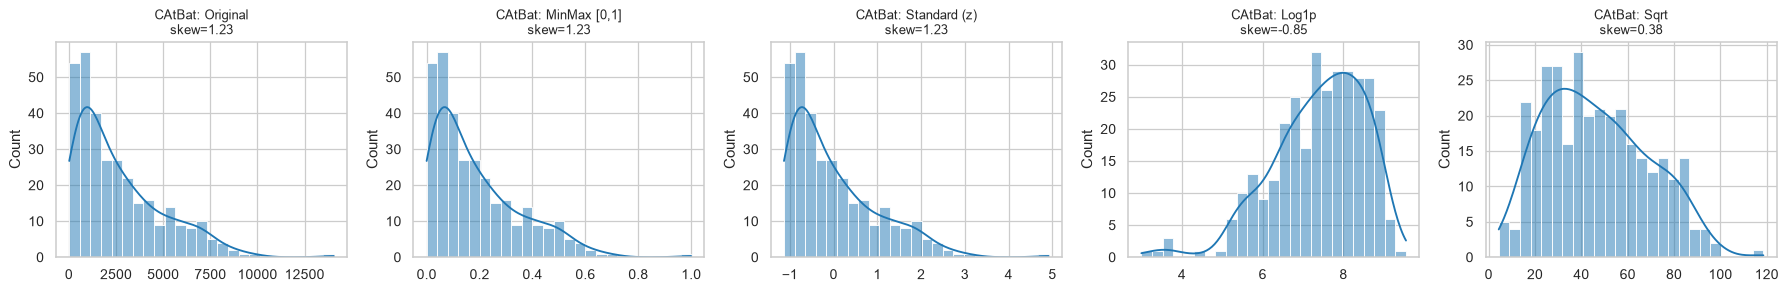

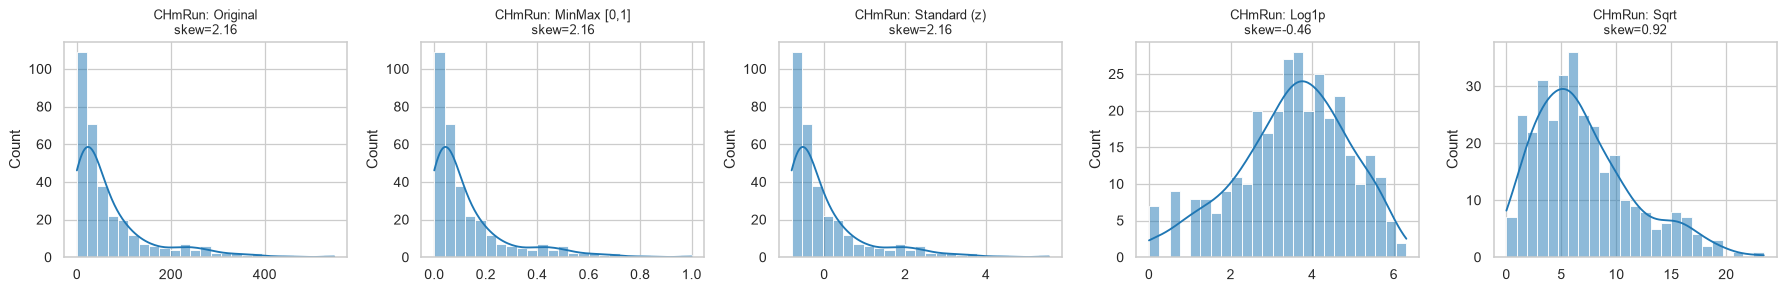

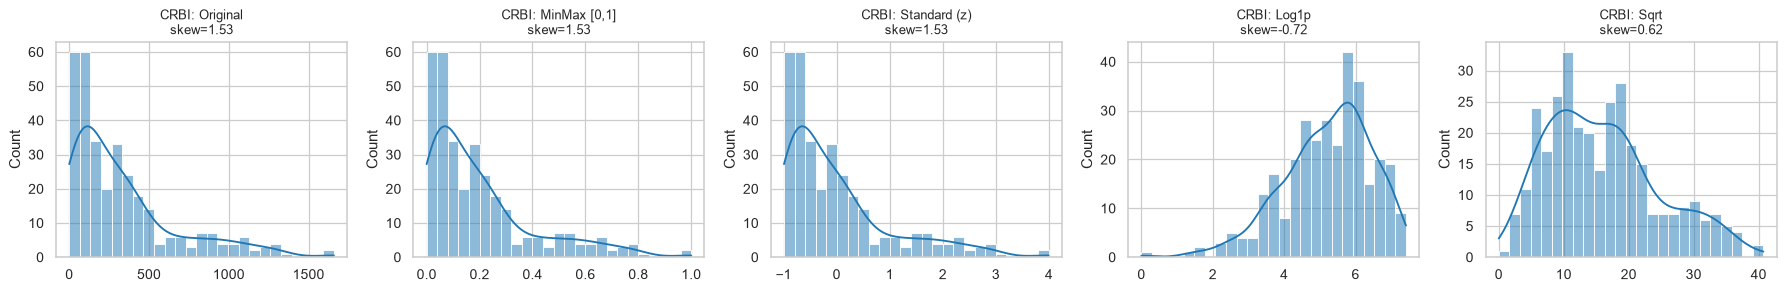

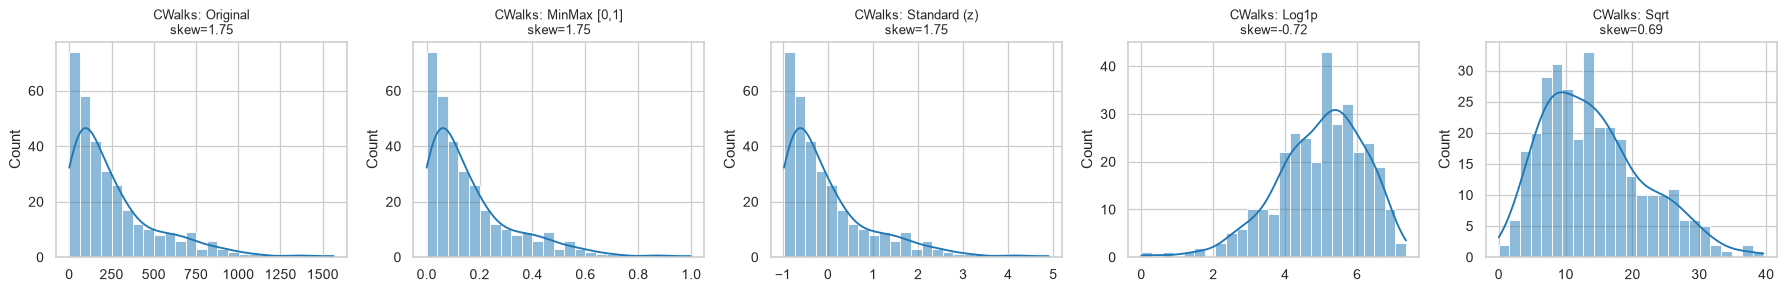

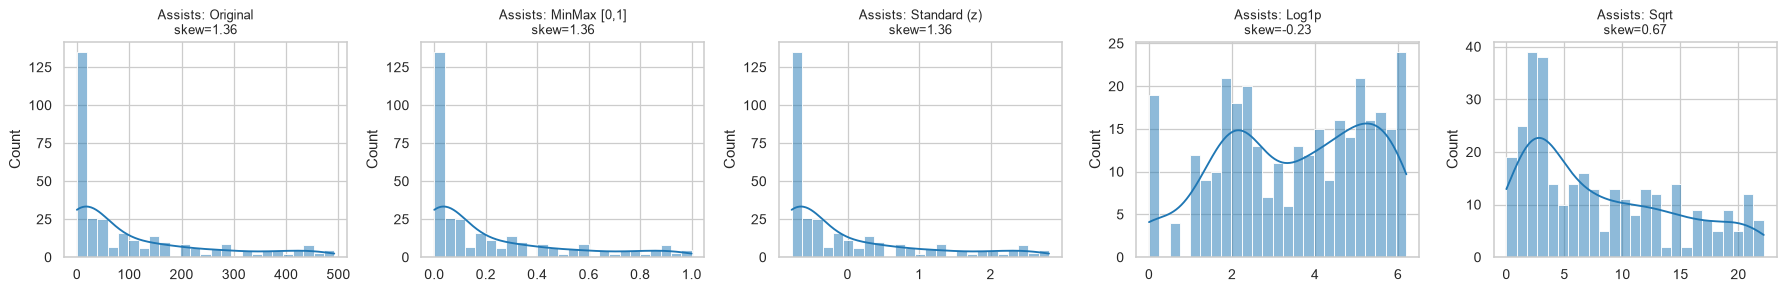

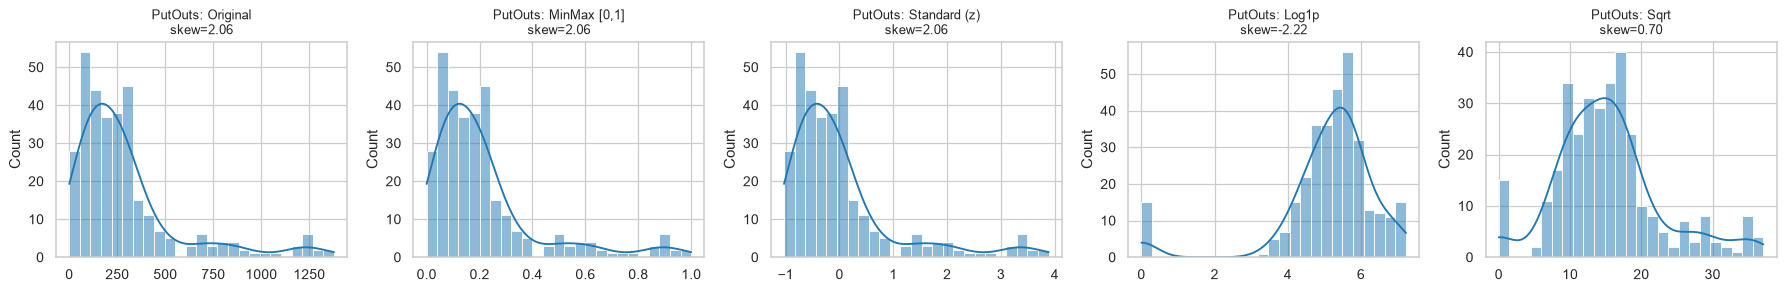

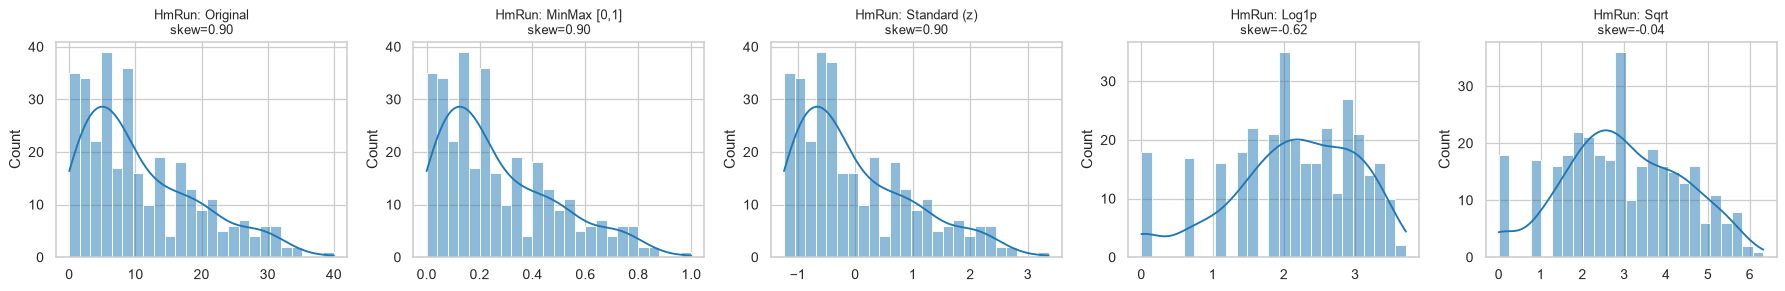

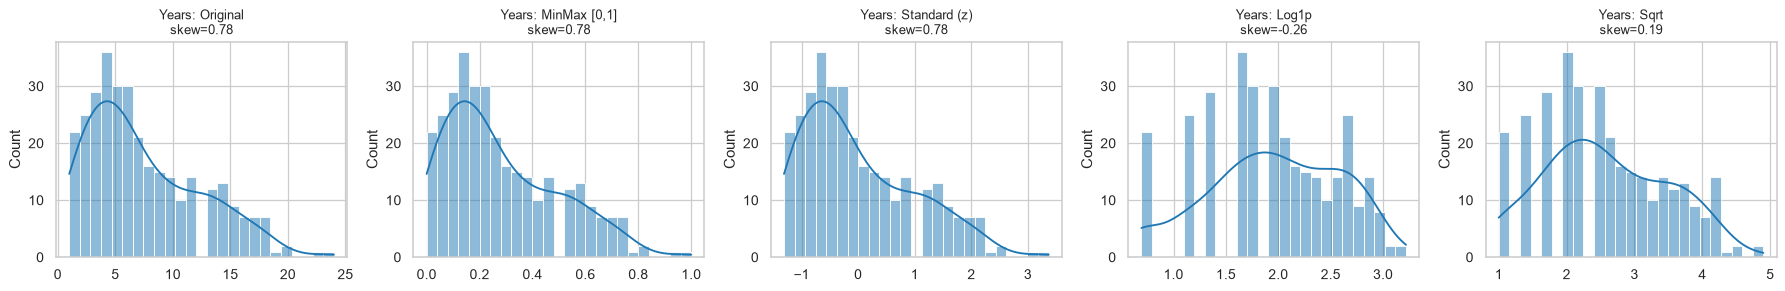

In [36]:
def compare_dist(col):
    fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
    for ax, (name, data) in zip(axes, [("Original", X_num[col]), ("MinMax [0,1]", transformed["MinMax [0,1]"][col]),
                                       ("Standard (z)", z[col]), ("Log1p", transformed["Log1p"][col]),
                                       ("Sqrt", transformed["Sqrt"][col])]):
        sns.histplot(data, kde=True, ax=ax, bins=25, color="tab:blue")
        ax.set_title(f"{col}: {name}\nskew={pd.Series(data).skew():.2f}", fontsize=10); ax.set_xlabel("")
    plt.tight_layout(); plt.show()

for c in ["CAtBat", "CHmRun", "CRBI", "CWalks", "Assists", "PutOuts", "HmRun", "Years"]:
    compare_dist(c)

In [37]:
sk = pd.DataFrame({n: t.skew() for n, t in transformed.items()})
sk.insert(0, "Original", X_num.skew())
sk.round(2)

,Original,"MinMax [0,1]","MinMax [-1,1]","MinMax [-3,3]",Standard (z),Robust,Log1p,Sqrt
AtBat,-0.08,-0.08,-0.08,-0.08,-0.08,-0.08,-2.36,-0.75
Hits,0.29,0.29,0.29,0.29,0.29,0.29,-2.27,-0.47
HmRun,0.90,0.90,0.90,0.90,0.90,0.90,-0.62,-0.04
Runs,0.42,0.42,0.42,0.42,0.42,0.42,-1.92,-0.36
RBI,0.61,0.61,0.61,0.61,0.61,0.61,-1.88,-0.24
Walks,0.62,0.62,0.62,0.62,0.62,0.62,-1.59,-0.18
Years,0.78,0.78,0.78,0.78,0.78,0.78,-0.26,0.19
CAtBat,1.23,1.23,1.23,1.23,1.23,1.23,-0.85,0.38
CHits,1.36,1.36,1.36,1.36,1.36,1.36,-0.83,0.42
CHmRun,2.16,2.16,2.16,2.16,2.16,2.16,-0.46,0.92


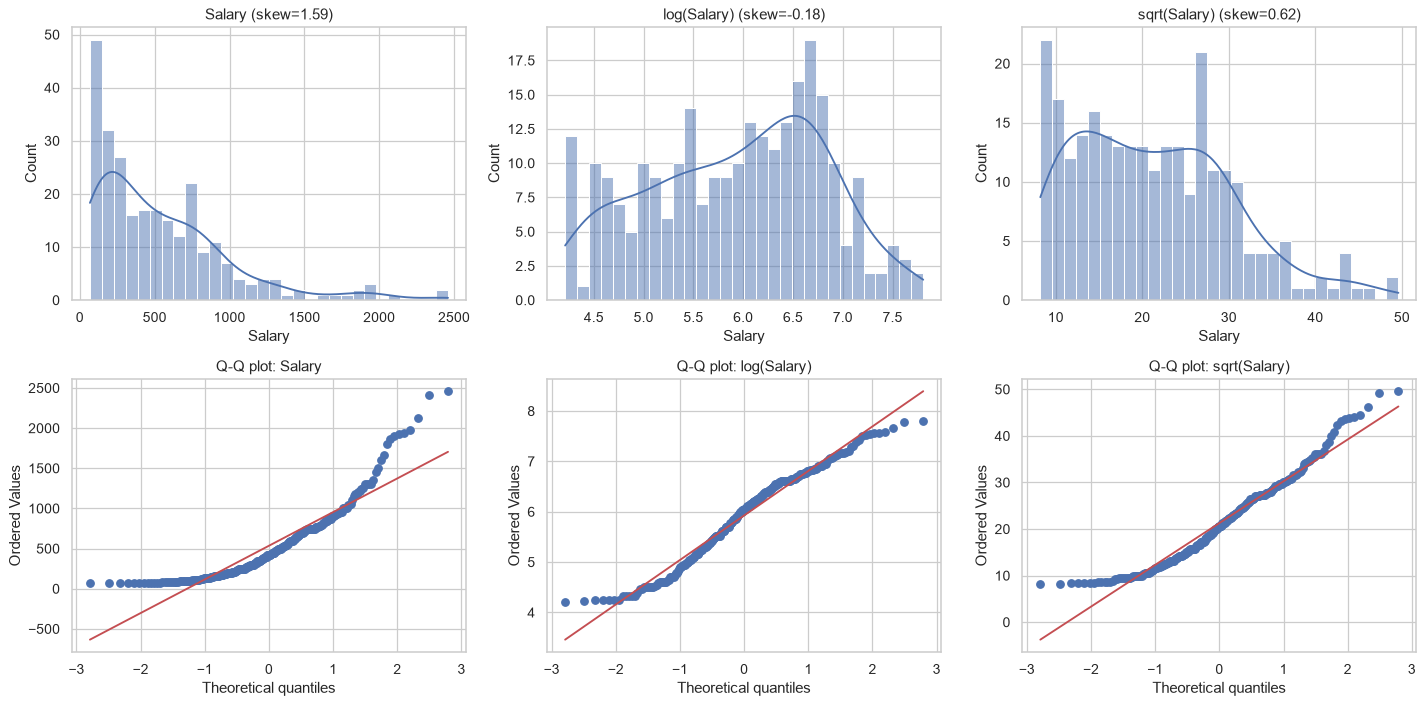

In [38]:
sal = df.Salary.dropna()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, (name, data) in enumerate([("Salary", sal), ("log(Salary)", np.log(sal)), ("sqrt(Salary)", np.sqrt(sal))]):
    sns.histplot(data, kde=True, ax=axes[0, i], bins=30); axes[0, i].set_title(f"{name} (skew={data.skew():.2f})")
    stats.probplot(data, dist="norm", plot=axes[1, i]); axes[1, i].set_title(f"Q-Q plot: {name}")
plt.tight_layout(); plt.show()

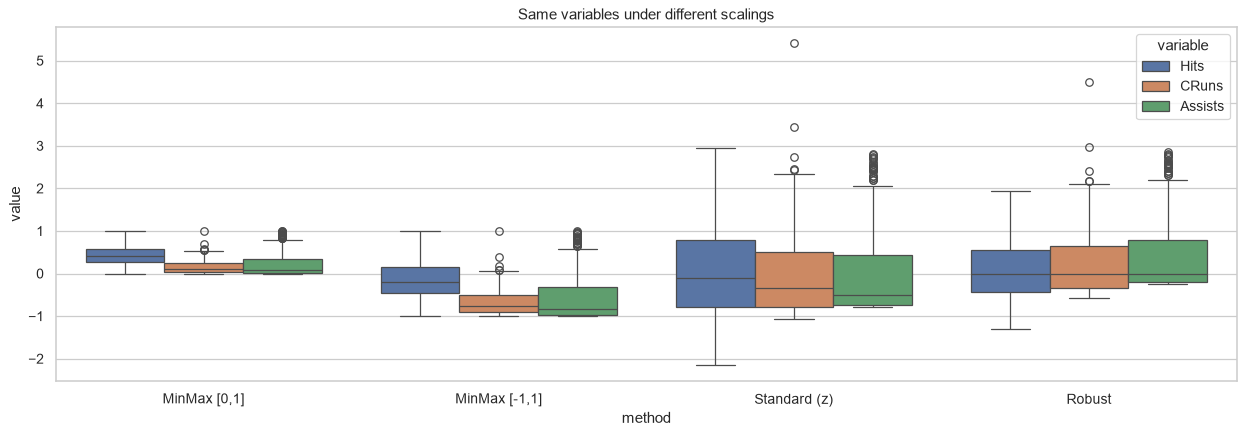

In [39]:
long = pd.concat([transformed[n][["Hits","CRuns","Assists"]].assign(method=n) for n in ["MinMax [0,1]","MinMax [-1,1]","Standard (z)","Robust"]])
long = long.melt(id_vars="method", var_name="variable")
plt.figure(figsize=(14, 5))
sns.boxplot(data=long, x="method", y="value", hue="variable")
plt.title("Same variables under different scalings"); plt.tight_layout(); plt.show()

## 7. Missing-Data Estimation and Imputation (Experiment 3)

In [40]:
miss = df.Salary.isna()
print(f"Salary missing: {miss.sum()} of {len(df)} ({miss.mean()*100:.1f}%) — no other column has NAs")
comp = df.groupby(miss.rename("SalaryMissing"))[num_cols[:-1]].mean().T
comp["diff_%"] = (comp[True] / comp[False] - 1) * 100
comp.round(2)

Salary missing: 59 of 322 (18.3%) — no other column has NAs


SalaryMissing,False,True,diff_%
AtBat,403.64,279.68,-30.71
Hits,107.83,70.69,-34.44
HmRun,11.62,6.98,-39.90
Runs,54.75,33.81,-38.23
RBI,51.49,32.61,-36.66
Walks,41.11,28.17,-31.48
Years,7.31,8.03,9.88
CAtBat,2657.54,2609.19,-1.82
CHits,722.19,697.00,-3.49
CHmRun,69.24,70.61,1.98


In [41]:
tests = []
for c in [c for c in num_cols if c != "Salary"]:
    u, p = stats.mannwhitneyu(df.loc[miss, c], df.loc[~miss, c])
    tests.append((c, p))
mt = pd.DataFrame(tests, columns=["variable", "MannWhitney_p"]).set_index("variable")
mt["differs_at_5%"] = mt.MannWhitney_p < 0.05
mt.T

variable,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors
MannWhitney_p,0.0,0.0,0.0,0.0,0.0,0.0,0.514,0.398,0.36,0.129,0.272,0.242,0.393,0.525,0.007,0.003
differs_at_5%,True,True,True,True,True,True,False,False,False,False,False,False,False,False,True,True


League: chi2=0.987, p=0.321
Division: chi2=0.006, p=0.939
NewLeague: chi2=0.424, p=0.515


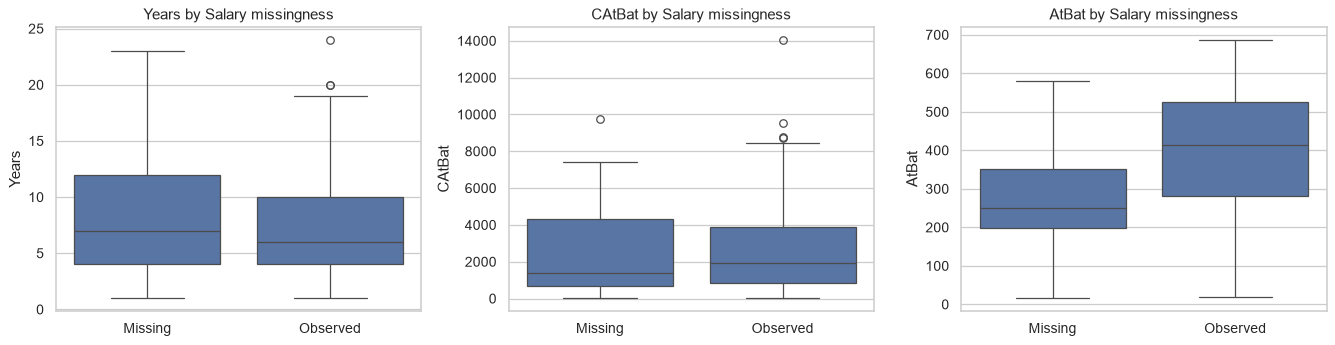

In [42]:
for c in cat_cols:
    ct = pd.crosstab(df[c], miss)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f"{c}: chi2={chi2:.3f}, p={p:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["Years", "CAtBat", "AtBat"]):
    sns.boxplot(x=miss.map({True: "Missing", False: "Observed"}), y=df[c], ax=ax)
    ax.set_title(f"{c} by Salary missingness"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

If predictors differ between rows with and without Salary, the data are not MCAR and complete-case analysis may be biased; MAR-based methods (KNN, iterative, MICE) use the observed predictors to reduce that bias.

### 7.1 Global and class-based imputation of Salary

In [43]:
feat = [c for c in num_cols if c != "Salary"]
imputed = {}
imputed["Complete-case"] = df.Salary.dropna()
imputed["Mean"] = df.Salary.fillna(df.Salary.mean())
imputed["Median"] = df.Salary.fillna(df.Salary.median())
imputed["Mode"] = df.Salary.fillna(df.Salary.mode().iloc[0])
imputed["Constant(0)"] = df.Salary.fillna(0)
imputed["Class: League×Division median"] = df.Salary.fillna(df.groupby(["League","Division"], observed=True).Salary.transform("median"))
years_bin = pd.cut(df.Years, [0,2,5,10,25])
imputed["Class: Years-band median"] = df.Salary.fillna(df.groupby(years_bin, observed=True).Salary.transform("median"))

knn_imp = KNNImputer(n_neighbors=5)
Zs = StandardScaler().fit_transform(df[feat])
knn_out = knn_imp.fit_transform(np.column_stack([Zs, df.Salary]))
imputed["KNN (k=5)"] = pd.Series(knn_out[:, -1], index=df.index)

it = IterativeImputer(random_state=SEED, max_iter=20)
imputed["Iterative (single)"] = pd.Series(it.fit_transform(df[feat + ["Salary"]])[:, -1], index=df.index)

imp_stats = pd.DataFrame({k: {"n": v.count(), "mean": v.mean(), "median": v.median(), "std": v.std(),
                              "min": v.min(), "max": v.max(), "skew": v.skew()} for k, v in imputed.items()}).T
imp_stats

,n,mean,median,std,min,max,skew
Complete-case,263.0,535.926,425.000,451.119,67.500,2460.0,1.589
Mean,322.0,535.926,535.926,407.558,67.500,2460.0,1.756
Median,322.0,515.601,425.000,409.817,67.500,2460.0,1.874
Mode,322.0,575.151,555.000,415.912,67.500,2460.0,1.392
Constant(0),322.0,437.728,298.750,457.407,0.000,2460.0,1.603
Class: League×Division median,322.0,517.162,450.000,410.990,67.500,2460.0,1.842
Class: Years-band median,322.0,523.179,430.750,421.811,67.500,2460.0,1.632
KNN (k=5),322.0,515.979,408.750,427.243,67.500,2460.0,1.676
Iterative (single),322.0,518.560,392.500,431.542,53.958,2460.0,1.621


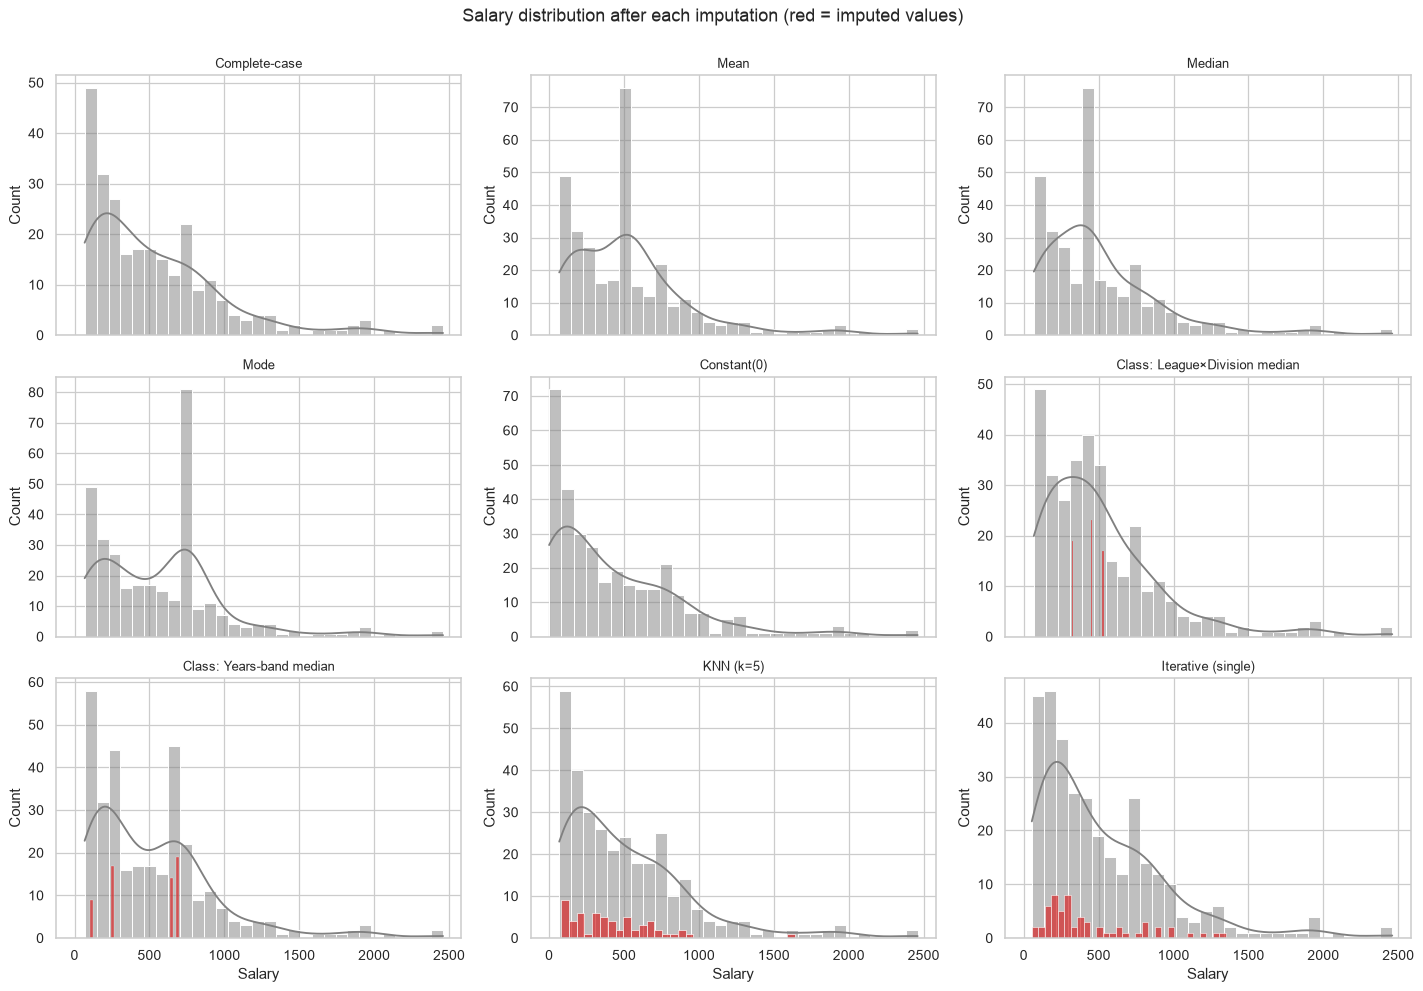

In [44]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
for ax, (k, v) in zip(axes.ravel(), imputed.items()):
    sns.histplot(v, bins=30, ax=ax, kde=True, color="grey")
    if len(v) == len(df):
        sns.histplot(v[miss], bins=30, ax=ax, color="tab:red", alpha=.7)
    ax.set_title(k, fontsize=10); ax.set_xlabel("Salary")
plt.suptitle("Salary distribution after each imputation (red = imputed values)", y=1.0)
plt.tight_layout(); plt.show()

Mean/median/mode/constant collapse all 59 imputed values onto one number, shrinking variance; class-based imputation preserves group differences; KNN and iterative imputation use the predictors and give player-specific estimates. The constant 0 is shown only as a counter-example — 0 is not a plausible salary.

### 7.2 Controlled evaluation: masking known values

In [45]:
rng = np.random.default_rng(SEED)
obs = df.dropna().reset_index(drop=True)
truth = obs.copy()
mask_cols = ["Hits", "Walks", "CRuns", "PutOuts", "Salary"]
mask = pd.DataFrame(False, index=obs.index, columns=obs.columns)
for c in mask_cols:
    mask.loc[rng.choice(len(obs), size=int(0.15 * len(obs)), replace=False), c] = True
masked = obs.copy()
for c in mask_cols:
    masked.loc[mask[c], c] = np.nan
print("Masked cells:", int(mask.values.sum()))

def impute(d, method):
    out = d.copy()
    if method == "Mean":
        out[num_cols] = out[num_cols].fillna(out[num_cols].mean())
    elif method == "Median":
        out[num_cols] = out[num_cols].fillna(out[num_cols].median())
    elif method == "Class (League, Division)":
        for c in mask_cols:
            out[c] = out[c].fillna(out.groupby(["League", "Division"], observed=True)[c].transform("median"))
    elif method == "KNN (k=5)":
        sc = StandardScaler().fit(out[num_cols])
        out[num_cols] = sc.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(sc.transform(out[num_cols])))
    elif method == "Iterative":
        out[num_cols] = IterativeImputer(random_state=SEED, max_iter=20).fit_transform(out[num_cols])
    return out

rmse = pd.DataFrame(index=["Mean", "Median", "Class (League, Division)", "KNN (k=5)", "Iterative"], columns=mask_cols, dtype=float)
for m in rmse.index:
    filled = impute(masked, m)
    for c in mask_cols:
        rmse.loc[m, c] = np.sqrt(np.mean((filled.loc[mask[c], c] - truth.loc[mask[c], c]) ** 2))
rmse.round(2)

Masked cells: 195


,Hits,Walks,CRuns,PutOuts,Salary
Mean,53.54,22.61,254.21,307.47,467.21
Median,53.70,24.15,277.90,311.40,464.88
"Class (League, Division)",53.11,23.96,266.12,313.21,450.36
KNN (k=5),20.63,16.31,91.88,318.05,297.52
Iterative,12.03,11.94,22.21,298.36,340.26


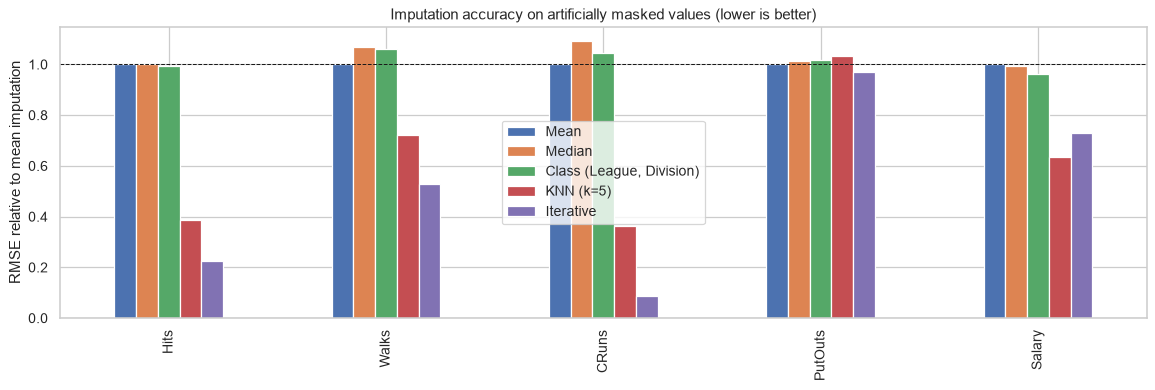

In [46]:
(rmse / rmse.loc["Mean"]).T.plot.bar(figsize=(13, 4.5))
plt.axhline(1, color="k", lw=.8, ls="--"); plt.ylabel("RMSE relative to mean imputation")
plt.title("Imputation accuracy on artificially masked values (lower is better)"); plt.tight_layout(); plt.show()

### 7.3 Multiple imputation (MICE with posterior sampling, Rubin's rules)

In [47]:
M = 10
mi_sets = []
for m in range(M):
    imp = IterativeImputer(estimator=BayesianRidge(), sample_posterior=True, random_state=SEED + m, max_iter=20)
    filled = pd.DataFrame(imp.fit_transform(df[feat + ["Salary"]]), columns=feat + ["Salary"])
    filled["Salary"] = filled["Salary"].clip(lower=df.Salary.min())
    mi_sets.append(filled)

est = np.array([d.Salary.mean() for d in mi_sets])
within = np.array([d.Salary.var(ddof=1) / len(d) for d in mi_sets])
Q, U, B = est.mean(), within.mean(), est.var(ddof=1)
T = U + (1 + 1 / M) * B
dfree = (M - 1) * (1 + U / ((1 + 1 / M) * B)) ** 2
ci = Q + np.array([-1, 1]) * stats.t.ppf(.975, dfree) * np.sqrt(T)
print(f"Per-imputation means: {np.round(est, 1)}")
print(f"Pooled mean salary = {Q:.2f}, within var = {U:.2f}, between var = {B:.2f}, total var = {T:.2f}")
print(f"95% CI (Rubin) = [{ci[0]:.1f}, {ci[1]:.1f}], fraction of missing info ≈ {(1 + 1/M) * B / T:.3f}")
cc = df.Salary.dropna(); se = cc.std() / np.sqrt(len(cc))
print(f"Complete-case mean = {cc.mean():.2f}, 95% CI = [{cc.mean()-1.96*se:.1f}, {cc.mean()+1.96*se:.1f}]")

Per-imputation means: [531.6 521.  525.4 517.9 515.6 531.  538.7 518.4 529.8 520. ]
Pooled mean salary = 524.94, within var = 603.86, between var = 56.91, total var = 666.46
95% CI (Rubin) = [474.3, 575.6], fraction of missing info ≈ 0.094
Complete-case mean = 535.93, 95% CI = [481.4, 590.4]


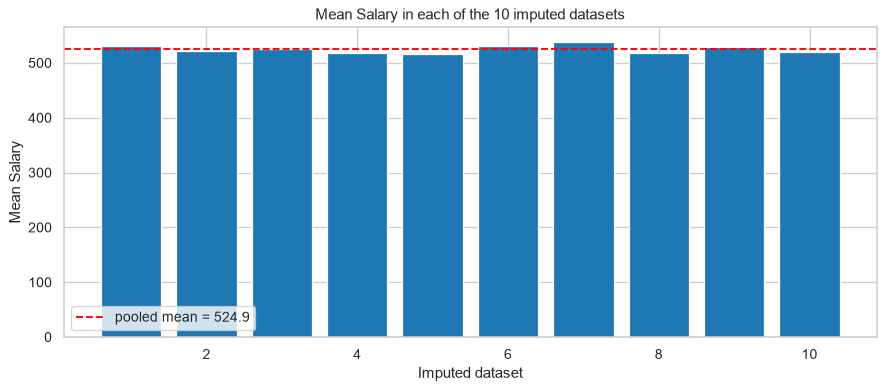

In [48]:
plt.figure(figsize=(10, 4.5))
plt.bar(range(1, M + 1), est, color="tab:blue")
plt.axhline(Q, color="red", ls="--", label=f"pooled mean = {Q:.1f}")
plt.xlabel("Imputed dataset"); plt.ylabel("Mean Salary"); plt.title(f"Mean Salary in each of the {M} imputed datasets"); plt.legend()
plt.tight_layout(); plt.show()

Single imputation (mean, KNN, iterative) treats estimated values as known; genuine multiple imputation creates M plausible datasets, analyses each, and pools the results so standard errors include imputation uncertainty. For the supervised models below, rows with missing Salary are excluded rather than imputed, since Salary is (or defines) the target.

## 8. Descriptive Statistics and Statistical Measures (Experiment 2)

### 8.1 Manual computation verified against NumPy/pandas

In [49]:
v = read_numbers("Enter values: ", df.Hits.sample(15, random_state=SEED).tolist())
n = len(v)
mean_m = sum(v) / n
s = sorted(v); median_m = (s[n//2] if n % 2 else (s[n//2 - 1] + s[n//2]) / 2)
counts = {}
for val in v: counts[val] = counts.get(val, 0) + 1
mx = max(counts.values()); modes_m = [k for k, c in counts.items() if c == mx] if mx > 1 else []
var_pop = sum((t - mean_m) ** 2 for t in v) / n
var_samp = sum((t - mean_m) ** 2 for t in v) / (n - 1)

manual = pd.DataFrame({
  "manual": [mean_m, median_m, var_pop, var_samp, var_pop ** .5, var_samp ** .5, max(v) - min(v)],
  "library": [np.mean(v), np.median(v), np.var(v), np.var(v, ddof=1), np.std(v), np.std(v, ddof=1), np.ptp(v)]},
  index=["mean", "median", "pop variance", "sample variance", "pop std", "sample std", "range"])
manual["match"] = np.isclose(manual.manual, manual.library)
print("Values:", v.astype(int).tolist())
print("Mode(s):", modes_m if modes_m else "no repeated value (no mode)", "| pandas:", pd.Series(v).mode().tolist() if modes_m else "-")
manual

Values: [43, 70, 34, 92, 114, 85, 52, 93, 137, 81, 128, 83, 122, 163, 136]
Mode(s): no repeated value (no mode) | pandas: -


,manual,library,match
mean,95.533,95.533,True
median,92.000,92.000,True
pop variance,1306.382,1306.382,True
sample variance,1399.695,1399.695,True
pop std,36.144,36.144,True
sample std,37.413,37.413,True
range,129.000,129.000,True


Population variance divides by $n$; the sample variance divides by $n-1$ (Bessel's correction) to give an unbiased estimate of the population variance. pandas uses `ddof=1` by default, NumPy `ddof=0`.

In [50]:
def multimode(series):
    m = series.mode()
    return m.tolist() if len(m) <= 5 else m.tolist()[:5] + ["..."]

full = pd.DataFrame({
  "mean": df[num_cols].mean(), "median": df[num_cols].median(),
  "mode(s)": [multimode(df[c]) for c in num_cols], "n_modes": [len(df[c].mode()) for c in num_cols],
  "var_sample": df[num_cols].var(), "var_pop": df[num_cols].var(ddof=0),
  "std_sample": df[num_cols].std(), "range": df[num_cols].max() - df[num_cols].min(),
  "Q1": df[num_cols].quantile(.25), "Q2": df[num_cols].quantile(.5), "Q3": df[num_cols].quantile(.75),
  "IQR": df[num_cols].quantile(.75) - df[num_cols].quantile(.25),
  "skewness": df[num_cols].skew(), "kurtosis(excess)": df[num_cols].kurt()})
full

,mean,median,mode(s),n_modes,var_sample,var_pop,std_sample,range,Q1,Q2,Q3,IQR,skewness,kurtosis(excess)
AtBat,380.929,379.5,"[209, 216, 315]",3,2.353e+04,2.346e+04,153.405,671.0,255.25,379.5,512.00,256.75,-0.078,-0.889
Hits,101.025,96.0,"[53, 70, 76]",3,2.158e+03,2.151e+03,46.455,237.0,64.00,96.0,137.00,73.00,0.291,-0.503
HmRun,10.770,8.0,[4],1,7.585e+01,7.561e+01,8.709,40.0,4.00,8.0,16.00,12.00,0.905,0.040
Runs,50.910,48.0,[42],1,6.773e+02,6.752e+02,26.024,130.0,30.25,48.0,69.00,38.75,0.416,-0.518
RBI,48.028,44.0,[29],1,6.847e+02,6.826e+02,26.167,121.0,28.00,44.0,64.75,36.75,0.608,-0.301
Walks,38.742,35.0,[22],1,4.683e+02,4.668e+02,21.639,105.0,22.00,35.0,53.00,31.00,0.620,-0.258
Years,7.444,6.0,[4],1,2.427e+01,2.419e+01,4.926,23.0,4.00,6.0,11.00,7.00,0.780,-0.147
CAtBat,2648.683,1928.0,"[41, 216, 312, 711, 1258, ...]",8,5.402e+06,5.385e+06,2324.206,14034.0,816.75,1928.0,3924.25,3107.50,1.227,1.502
CHits,717.571,508.0,"[160, 238, 408, 715]",4,4.283e+05,4.270e+05,654.473,4252.0,209.00,508.0,1059.25,850.25,1.356,2.354
CHmRun,69.491,37.5,[32],1,7.442e+03,7.419e+03,86.266,548.0,14.00,37.5,90.00,76.00,2.163,5.324


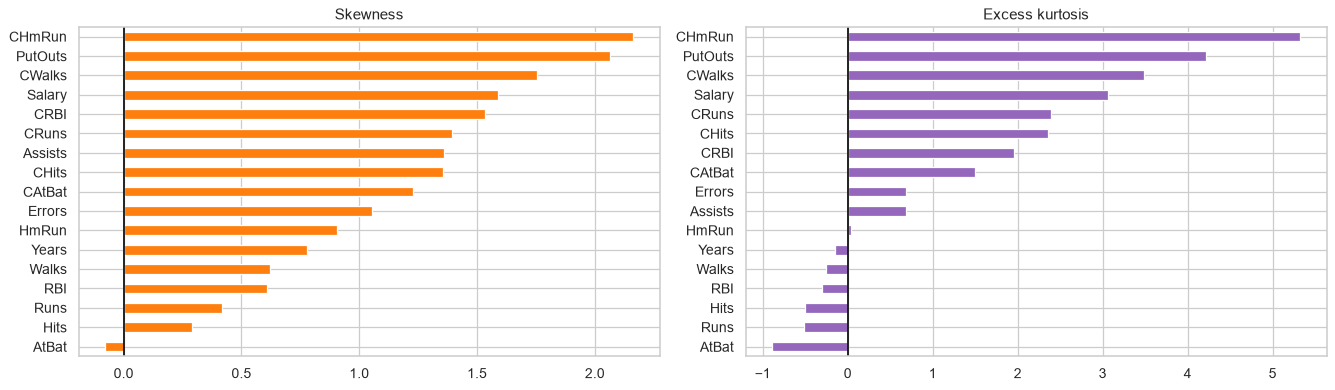

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
full["skewness"].sort_values().plot.barh(ax=ax[0], color="tab:orange"); ax[0].axvline(0, color="k"); ax[0].set_title("Skewness")
full["kurtosis(excess)"].sort_values().plot.barh(ax=ax[1], color="tab:purple"); ax[1].axvline(0, color="k"); ax[1].set_title("Excess kurtosis")
plt.tight_layout(); plt.show()

### 8.2 Covariance and correlation of (X, Y) pairs

In [52]:
X_in = read_numbers("Enter X values: ", df.AtBat.head(20).tolist())
Y_in = read_numbers("Enter Y values: ", df.Hits.head(20).tolist())
if len(X_in) != len(Y_in):
    raise ValueError("X and Y must have equal length")
mx_, my_ = X_in.mean(), Y_in.mean()
cov_m = ((X_in - mx_) * (Y_in - my_)).sum() / (len(X_in) - 1)
r_m = cov_m / (X_in.std(ddof=1) * Y_in.std(ddof=1))
print(f"Manual covariance = {cov_m:.3f} | np.cov = {np.cov(X_in, Y_in)[0, 1]:.3f}")
print(f"Manual Pearson r  = {r_m:.4f} | np.corrcoef = {np.corrcoef(X_in, Y_in)[0, 1]:.4f}")

Manual covariance = 6339.958 | np.cov = 6339.958
Manual Pearson r  = 0.9928 | np.corrcoef = 0.9928


In [53]:
pairs = [("AtBat","Hits"), ("Hits","Runs"), ("HmRun","RBI"), ("Years","CAtBat"), ("CRuns","Salary"),
         ("CRBI","Salary"), ("Hits","Salary"), ("Years","Salary"), ("Assists","Errors"), ("PutOuts","Assists")]
res = []
for a, b in pairs:
    d = df[[a, b]].dropna()
    pr, pp = stats.pearsonr(d[a], d[b]); sr, sp = stats.spearmanr(d[a], d[b]); kt, kp = stats.kendalltau(d[a], d[b])
    res.append({"X": a, "Y": b, "n": len(d), "covariance": d[a].cov(d[b]), "pearson_r": pr, "pearson_p": pp,
                "spearman_rho": sr, "kendall_tau": kt})
pd.DataFrame(res)

,X,Y,n,covariance,pearson_r,pearson_p,spearman_rho,kendall_tau
0,AtBat,Hits,322,6897.908,0.968,4.588e-194,0.975,0.865
1,Hits,Runs,322,1114.871,0.922,4.565e-134,0.932,0.778
2,HmRun,RBI,322,194.872,0.855,2.609e-93,0.817,0.642
3,Years,CAtBat,322,10536.615,0.920,1.846e-132,0.909,0.766
4,CRuns,Salary,263,84069.599,0.563,2.312e-23,0.767,0.608
5,CRBI,Salary,263,82707.364,0.567,9.071e-24,0.760,0.598
6,Hits,Salary,263,8930.048,0.439,8.531e-14,0.479,0.342
7,Years,Salary,263,866.417,0.401,1.463e-11,0.626,0.462
8,Assists,Errors,322,615.623,0.706,6.026e-50,0.748,0.576
9,PutOuts,Assists,322,-961.317,-0.025,6.546e-01,0.155,0.178


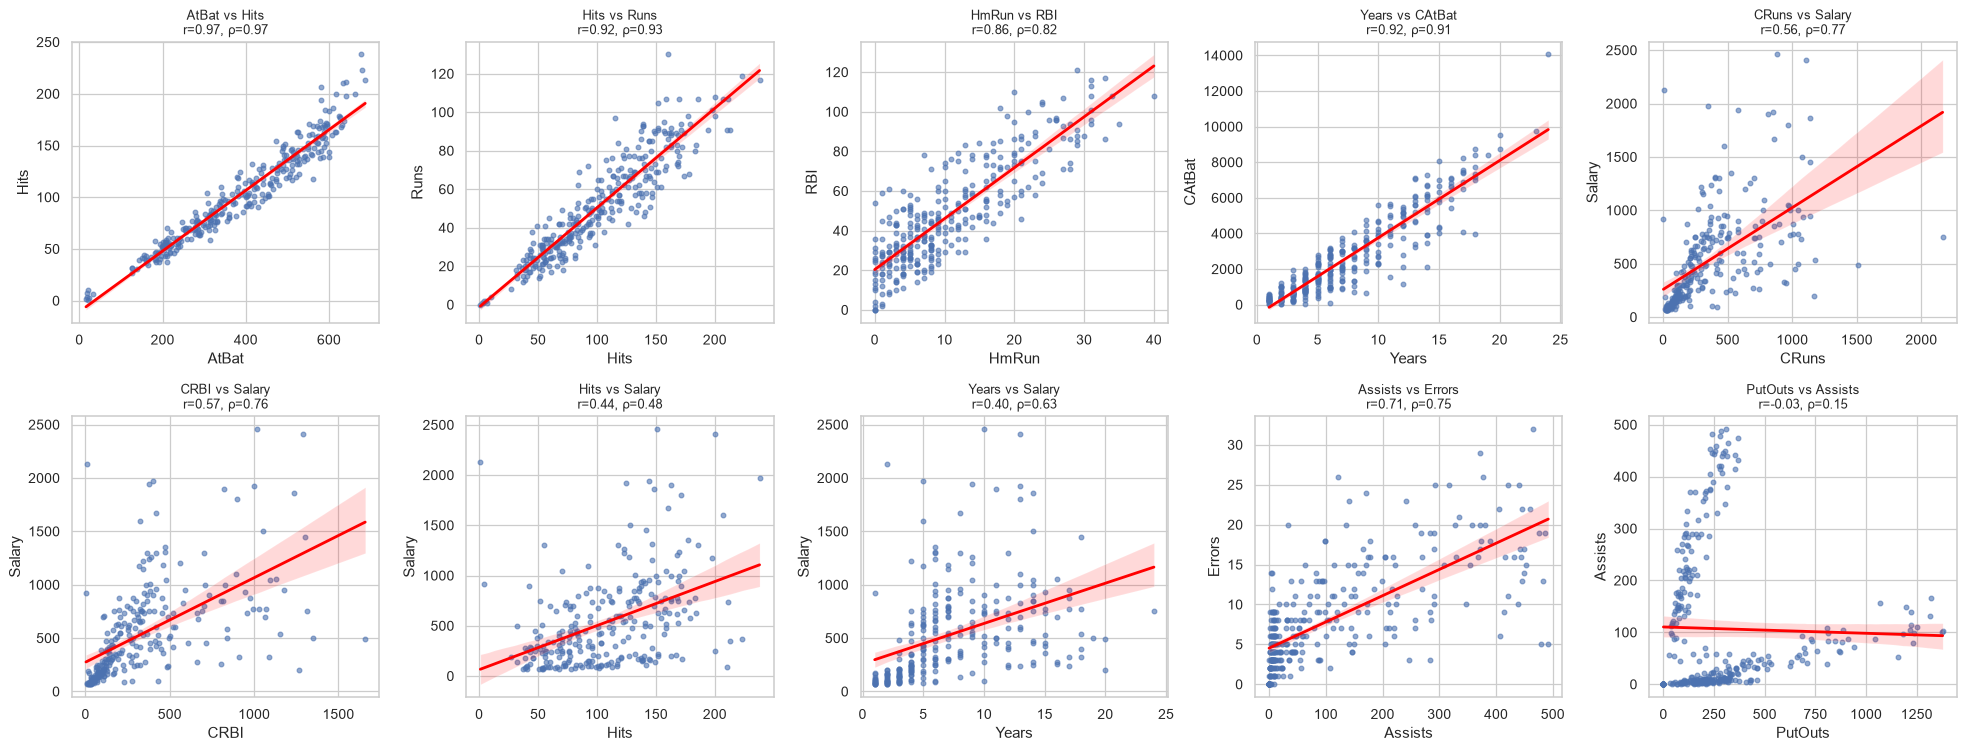

In [54]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))
for ax, (a, b) in zip(axes.ravel(), pairs):
    sns.regplot(data=df, x=a, y=b, ax=ax, scatter_kws={"s": 14, "alpha": .6}, line_kws={"color": "red"})
    d = df[[a, b]].dropna()
    ax.set_title(f"{a} vs {b}\nr={d[a].corr(d[b]):.2f}, ρ={d[a].corr(d[b], method='spearman'):.2f}", fontsize=10)
plt.tight_layout(); plt.show()

In [55]:
df[num_cols].cov().round(1)

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors,Salary
AtBat,23533.1,6897.9,791.2,3645.1,3293.8,2223.6,35.8,8.398e+04,2.537e+04,3131.9,13660.8,12475.4,6805.7,13674.2,7428.3,344.0,26233.7
Hits,6897.9,2158.0,227.4,1114.9,985.9,644.6,10.2,2.457e+04,7.778e+03,812.4,4063.1,3591.4,1883.5,4051.2,2037.3,91.7,8930.0
HmRun,791.2,227.4,75.8,147.5,194.9,90.7,5.0,4.491e+03,1.258e+03,370.6,763.4,1021.5,542.3,691.7,-126.7,2.2,1355.1
Runs,3645.1,1114.9,147.5,677.3,543.6,412.3,0.6,1.128e+04,3.489e+03,511.7,2178.5,1786.2,1266.1,2040.7,785.6,39.9,4837.4
RBI,3293.8,985.9,194.9,543.6,684.7,348.8,18.8,1.792e+04,5.278e+03,997.2,2826.3,3428.3,1753.4,2520.8,381.7,32.2,5247.9
Walks,2223.6,644.6,90.7,412.3,348.8,468.3,14.5,1.394e+04,3.975e+03,620.6,2447.1,2225.4,2453.2,1819.3,443.2,17.8,4348.8
Years,35.8,10.2,5.0,0.6,18.8,14.5,24.3,1.054e+04,2.913e+03,308.9,1453.1,1426.1,1103.1,-6.5,-54.4,-5.1,866.4
CAtBat,83975.7,24570.3,4491.2,11280.4,17922.1,13940.3,10536.6,5.402e+06,1.514e+06,160166.8,763598.0,735142.4,562663.1,40634.3,648.2,-990.5,542719.2
CHits,25372.6,7777.6,1257.5,3488.7,5278.1,3975.0,2913.3,1.514e+06,4.283e+05,44224.5,215297.7,206119.3,155722.9,14062.7,-226.0,-261.6,160509.4
CHmRun,3131.9,812.4,370.6,511.7,997.2,620.6,308.9,1.602e+05,4.422e+04,7441.8,23641.0,26718.5,18430.0,2729.7,-1871.4,-75.9,19464.9


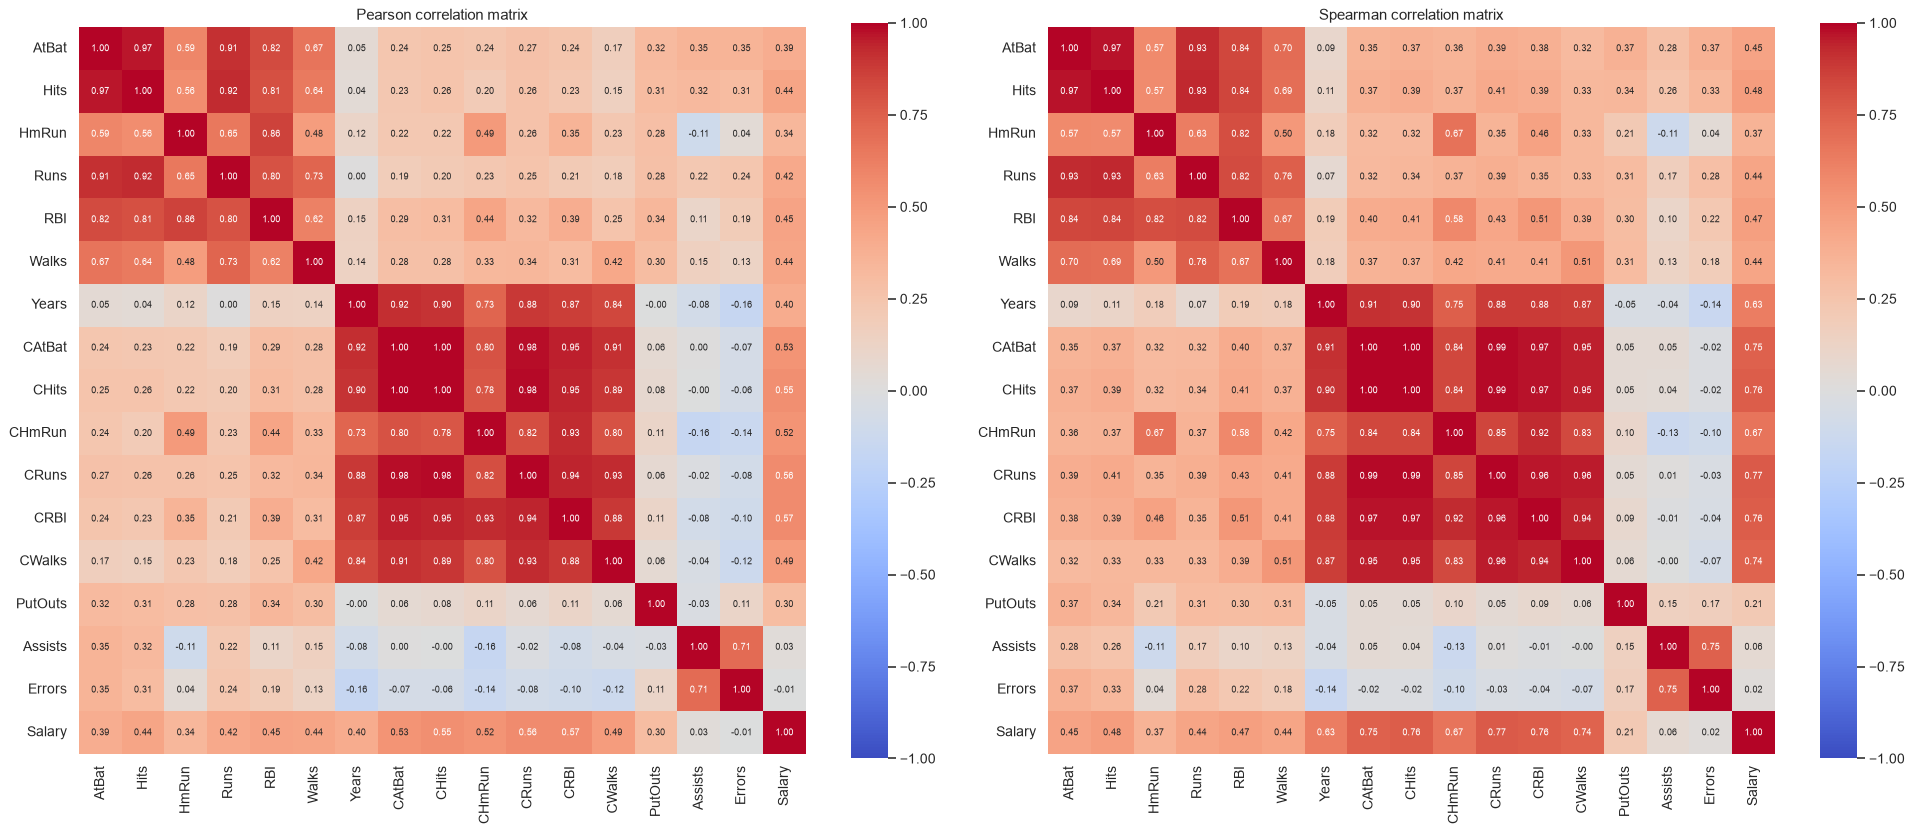

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, m in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[num_cols].corr(method=m), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7}, square=True)
    ax.set_title(f"{m.title()} correlation matrix")
plt.tight_layout(); plt.show()

In [57]:
pdiff = (df[num_cols].corr("spearman") - df[num_cols].corr("pearson"))
pairs_diff = pdiff.where(np.triu(np.ones(pdiff.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False).head(10)
pairs_diff.to_frame("spearman - pearson")

,,spearman - pearson
CWalks,Salary,0.245
Years,Salary,0.225
CAtBat,Salary,0.223
CHits,Salary,0.210
CRuns,Salary,0.204
CRBI,Salary,0.193
Hits,CWalks,0.181
HmRun,CHmRun,0.180
PutOuts,Assists,0.180
Hits,CRBI,0.163


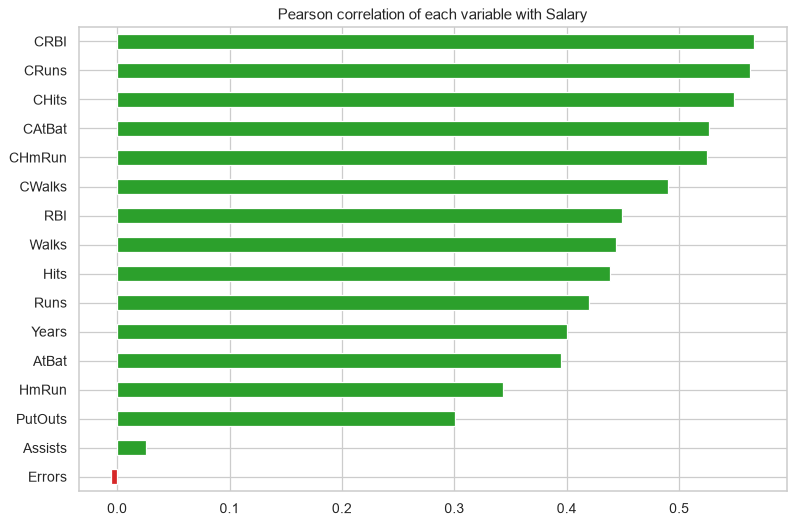

In [58]:
sal_corr = df[num_cols].corr()["Salary"].drop("Salary").sort_values()
sal_corr.plot.barh(figsize=(9, 6), color=np.where(sal_corr > 0, "tab:green", "tab:red"))
plt.title("Pearson correlation of each variable with Salary"); plt.tight_layout(); plt.show()

## 9. Outlier Detection

In [59]:
def iqr_flags(d, k=1.5):
    q1, q3 = d.quantile(.25), d.quantile(.75); i = q3 - q1
    return (d < q1 - k * i) | (d > q3 + k * i)

def z_flags(d, t=3):
    return ((d - d.mean()) / d.std()).abs() > t

def mad_flags(d, t=3.5):
    med = d.median(); mad = (d - med).abs().median()
    return pd.DataFrame(False, index=d.index, columns=d.columns) if (mad == 0).all() else (0.6745 * (d - med) / mad.replace(0, np.nan)).abs() > t

D = df[num_cols]
flags = {"IQR (1.5)": iqr_flags(D), "IQR (3.0, extreme)": iqr_flags(D, 3), "Z-score (|z|>3)": z_flags(D), "Modified Z (MAD, >3.5)": mad_flags(D)}
summ = pd.DataFrame({k: f.sum() for k, f in flags.items()})
summ_pct = (summ / D.count().values[:, None] * 100).round(1).add_suffix(" %")
summ.join(summ_pct)

,IQR (1.5),"IQR (3.0, extreme)",Z-score (|z|>3),"Modified Z (MAD, >3.5)",IQR (1.5) %,"IQR (3.0, extreme) %",Z-score (|z|>3) %,"Modified Z (MAD, >3.5) %"
AtBat,0,0,0,0,0.0,0.0,0.0,0.0
Hits,0,0,0,0,0.0,0.0,0.0,0.0
HmRun,2,0,1,3,0.6,0.0,0.3,0.9
Runs,1,0,1,0,0.3,0.0,0.3,0.0
RBI,1,0,0,0,0.3,0.0,0.0,0.0
Walks,1,0,1,0,0.3,0.0,0.3,0.0
Years,2,0,2,2,0.6,0.0,0.6,0.6
CAtBat,5,1,2,5,1.6,0.3,0.6,1.6
CHits,6,1,2,6,1.9,0.3,0.6,1.9
CHmRun,32,7,7,34,9.9,2.2,2.2,10.6


In [60]:
pd.DataFrame({k: {"rows flagged in any column": int(f.any(axis=1).sum()), "% rows": round(f.any(axis=1).mean() * 100, 1),
                  "total flags": int(f.values.sum())} for k, f in flags.items()}).T

,rows flagged in any column,% rows,total flags
IQR (1.5),106.0,32.9,180.0
"IQR (3.0, extreme)",23.0,7.1,31.0
Z-score (|z|>3),34.0,10.6,48.0
"Modified Z (MAD, >3.5)",122.0,37.9,199.0


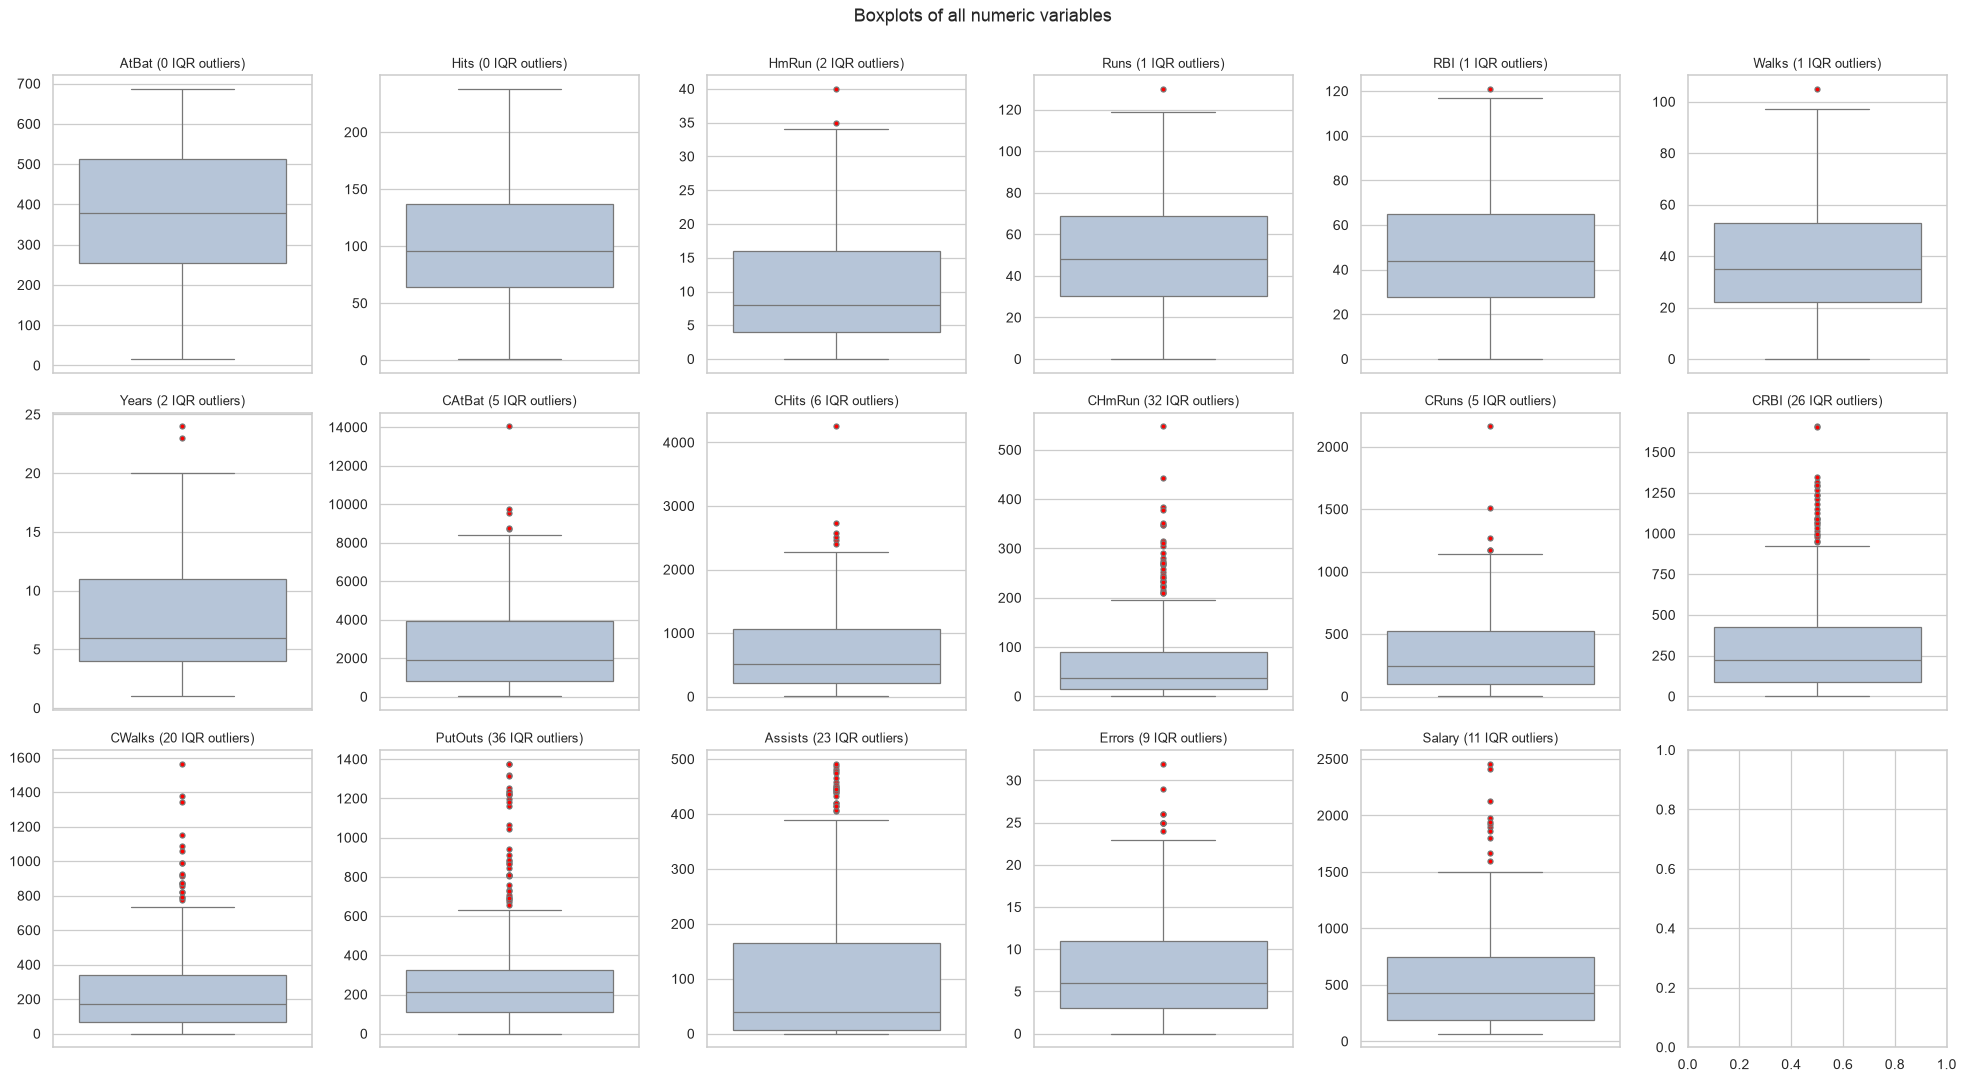

In [61]:
fig, axes = plt.subplots(3, 6, figsize=(22, 12))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="lightsteelblue", flierprops={"markerfacecolor": "red", "markersize": 4})
    ax.set_title(f"{c} ({int(flags['IQR (1.5)'][c].sum())} IQR outliers)", fontsize=10); ax.set_ylabel("")
plt.suptitle("Boxplots of all numeric variables", y=1.0); plt.tight_layout(); plt.show()

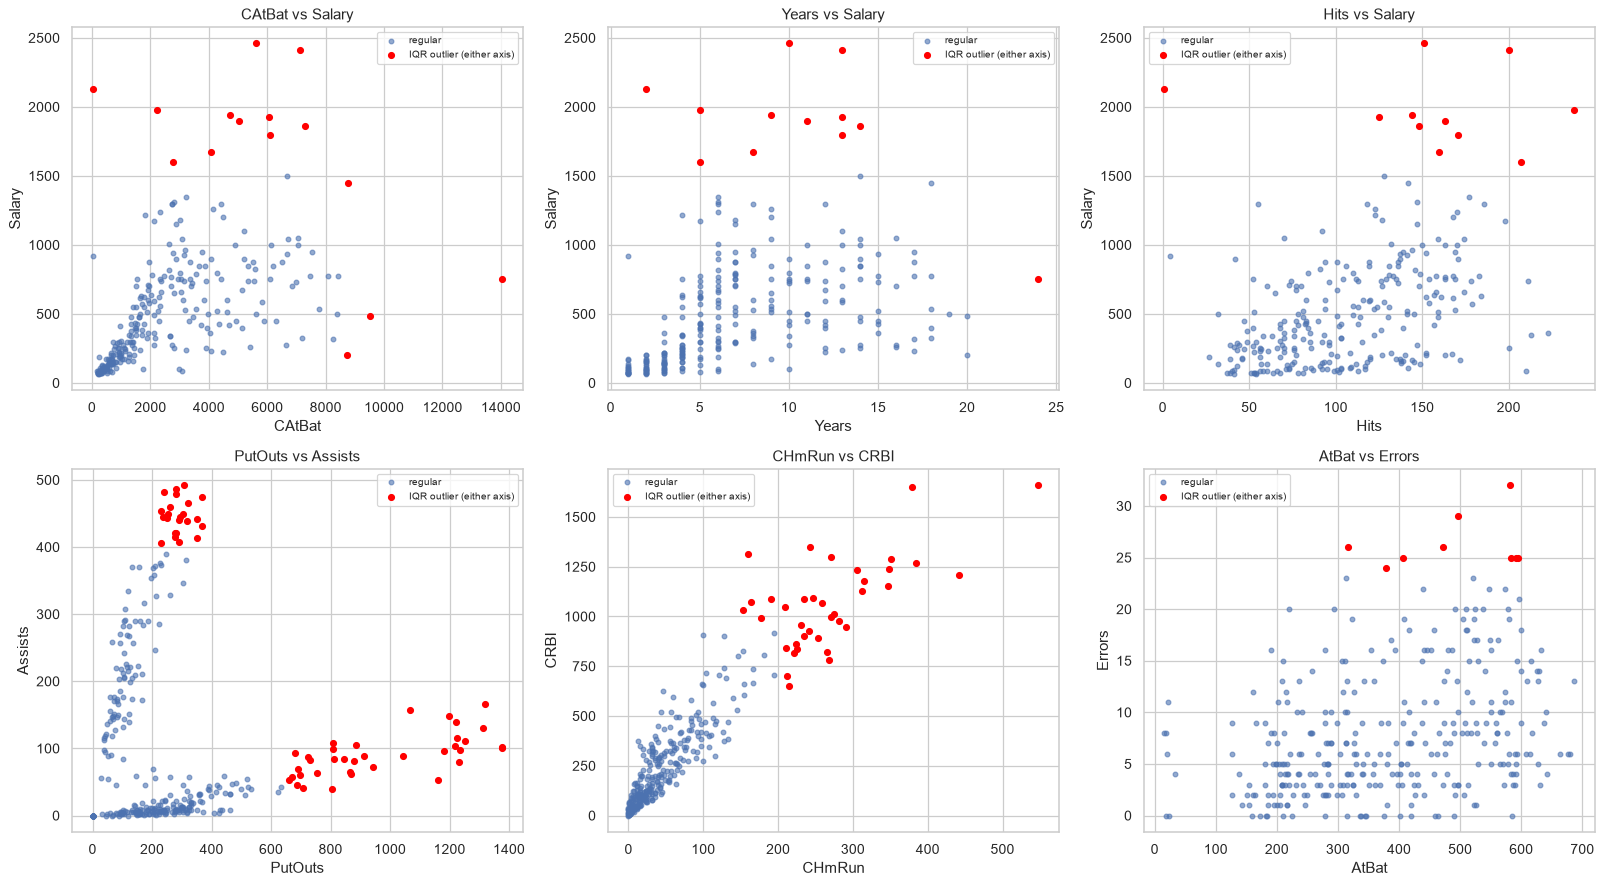

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (a, b) in zip(axes.ravel(), [("CAtBat","Salary"), ("Years","Salary"), ("Hits","Salary"), ("PutOuts","Assists"), ("CHmRun","CRBI"), ("AtBat","Errors")]):
    out = flags["IQR (1.5)"][[a, b]].any(axis=1)
    ax.scatter(df.loc[~out, a], df.loc[~out, b], s=14, alpha=.6, label="regular")
    ax.scatter(df.loc[out, a], df.loc[out, b], s=22, c="red", label="IQR outlier (either axis)")
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"{a} vs {b}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 9.1 Multivariate outliers (Mahalanobis distance)

Chi-square(0.975, 10) cutoff = 20.48; multivariate outliers = 21 (6.5%)


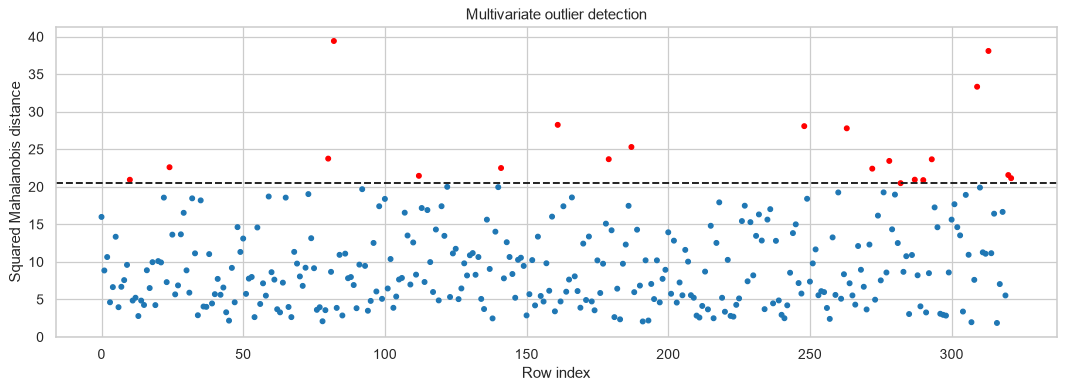

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,PutOuts,Assists,Errors,Salary
10,574,159,21,107,75,59,10,238,445,22,517.143
24,629,168,18,73,102,40,18,1067,157,14,776.667
80,561,118,35,70,94,33,16,463,32,8,NaN
82,677,238,31,117,113,53,5,1377,100,6,1975.000
112,490,125,24,81,105,62,13,869,62,8,1925.571
141,663,200,29,108,121,32,4,241,8,6,250.000
161,579,174,7,67,78,58,6,280,479,5,657.000
179,551,171,13,94,83,94,13,1199,149,5,1800.000
187,680,223,31,119,96,34,3,429,8,6,365.000
248,608,160,28,130,74,89,8,426,4,6,1670.000


In [63]:
mv_cols = ["AtBat","Hits","HmRun","Runs","RBI","Walks","Years","PutOuts","Assists","Errors"]
Xmv = df[mv_cols].values
diff = Xmv - Xmv.mean(axis=0)
inv_cov = np.linalg.inv(np.cov(Xmv, rowvar=False))
d2 = np.sum(diff @ inv_cov * diff, axis=1)
cut = stats.chi2.ppf(0.975, df=len(mv_cols))
mv_out = d2 > cut
print(f"Chi-square(0.975, {len(mv_cols)}) cutoff = {cut:.2f}; multivariate outliers = {mv_out.sum()} ({mv_out.mean()*100:.1f}%)")
plt.figure(figsize=(12, 4.5))
plt.scatter(range(len(d2)), d2, c=np.where(mv_out, "red", "tab:blue"), s=14)
plt.axhline(cut, color="k", ls="--"); plt.xlabel("Row index"); plt.ylabel("Squared Mahalanobis distance")
plt.title("Multivariate outlier detection"); plt.tight_layout(); plt.show()
df.loc[mv_out, mv_cols + ["Salary"]].head(10)

In [64]:
n_methods = pd.DataFrame({k: f.any(axis=1) for k, f in flags.items()}).sum(axis=1) + mv_out
print("Rows flagged by how many methods:")
n_methods.value_counts().sort_index().to_frame("rows").T

Rows flagged by how many methods:


,0,1,2,3,4,5
rows,184,42,55,16,19,6


### 9.2 Treating outliers: winsorizing, IQR capping and log

,count,mean,std,min,25%,50%,75%,max,skew
Original,322.0,106.913,136.855,0.0,7.000,39.500,166.000,492.000,1.358
Winsorized 1-99%,322.0,106.828,136.620,0.0,7.000,39.500,166.000,478.160,1.353
IQR capped,322.0,103.933,129.507,0.0,7.000,39.500,166.000,404.500,1.230
Log1p,322.0,3.518,1.791,0.0,2.079,3.701,5.118,6.201,-0.234


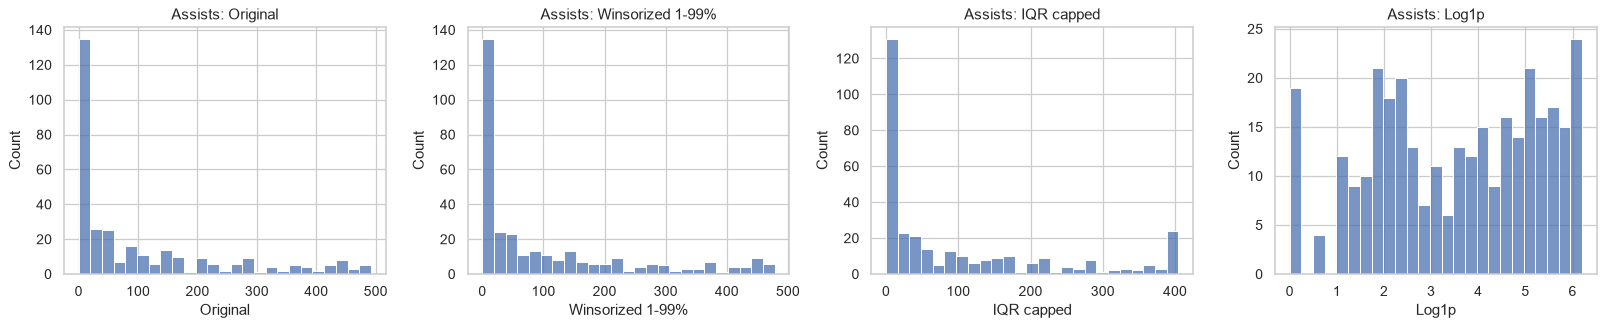

In [65]:
def iqr_cap(s, k=1.5):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    return s.clip(q1 - k * (q3 - q1), q3 + k * (q3 - q1))

treat = pd.DataFrame({
    "Original": df.Assists,
    "Winsorized 1-99%": df.Assists.clip(df.Assists.quantile(.01), df.Assists.quantile(.99)),
    "IQR capped": iqr_cap(df.Assists),
    "Log1p": np.log1p(df.Assists)})
display(treat.describe().T.join(treat.skew().rename("skew")))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, treat.columns):
    sns.histplot(treat[c], bins=25, ax=ax); ax.set_title(f"Assists: {c}")
plt.tight_layout(); plt.show()

In [66]:
impact = []
for c in ["Salary","CAtBat","CHmRun","Assists","Errors"]:
    keep = ~flags["IQR (1.5)"][c]
    impact.append({"variable": c, "mean_all": df[c].mean(), "mean_trimmed": df.loc[keep, c].mean(),
                   "median_all": df[c].median(), "median_trimmed": df.loc[keep, c].median(),
                   "std_all": df[c].std(), "std_trimmed": df.loc[keep, c].std()})
display(pd.DataFrame(impact).set_index("variable").round(1))
keep = ~flags["IQR (1.5)"][["Salary","CRuns"]].any(axis=1)
print(f"corr(CRuns, Salary): all = {df.CRuns.corr(df.Salary):.3f}, without IQR outliers = {df.loc[keep,'CRuns'].corr(df.loc[keep,'Salary']):.3f}")

,mean_all,mean_trimmed,median_all,median_trimmed,std_all,std_trimmed
variable,,,,,,
Salary,535.9,473.3,425.0,400.0,451.1,339.7
CAtBat,2648.7,2530.1,1928.0,1897.0,2324.2,2125.2
CHmRun,69.5,45.7,37.5,32.0,86.3,44.3
Assists,106.9,80.8,39.5,30.0,136.9,102.8
Errors,8.0,7.5,6.0,6.0,6.4,5.6


corr(CRuns, Salary): all = 0.563, without IQR outliers = 0.649


Outliers here are mostly long-career stars or specialised fielders (e.g., high PutOuts for first basemen, high Assists for infielders) — genuine extreme observations rather than errors, so they are retained. They inflate means and standard deviations far more than medians, which motivates robust scaling and log transforms.

## 10. Univariate Analysis

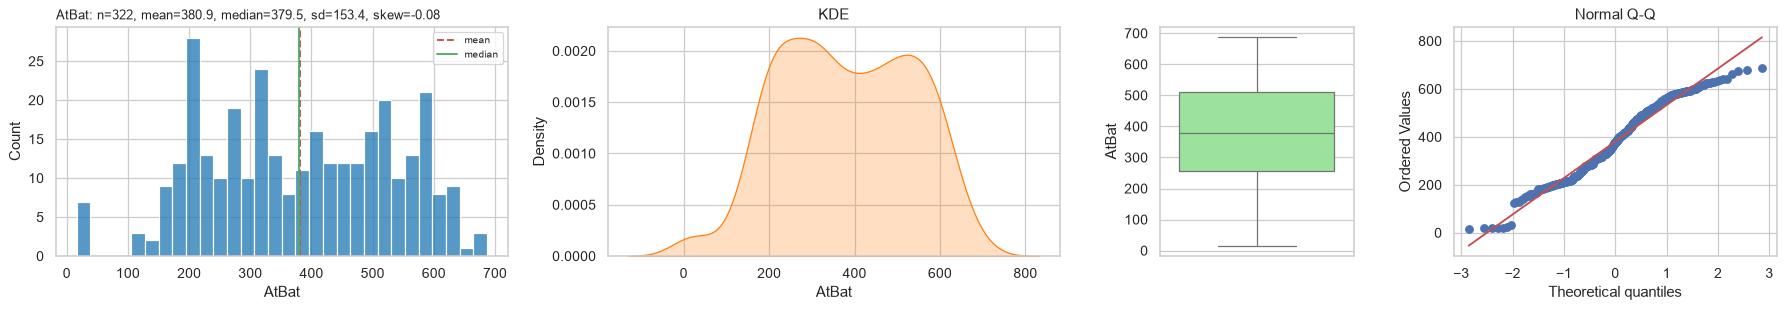

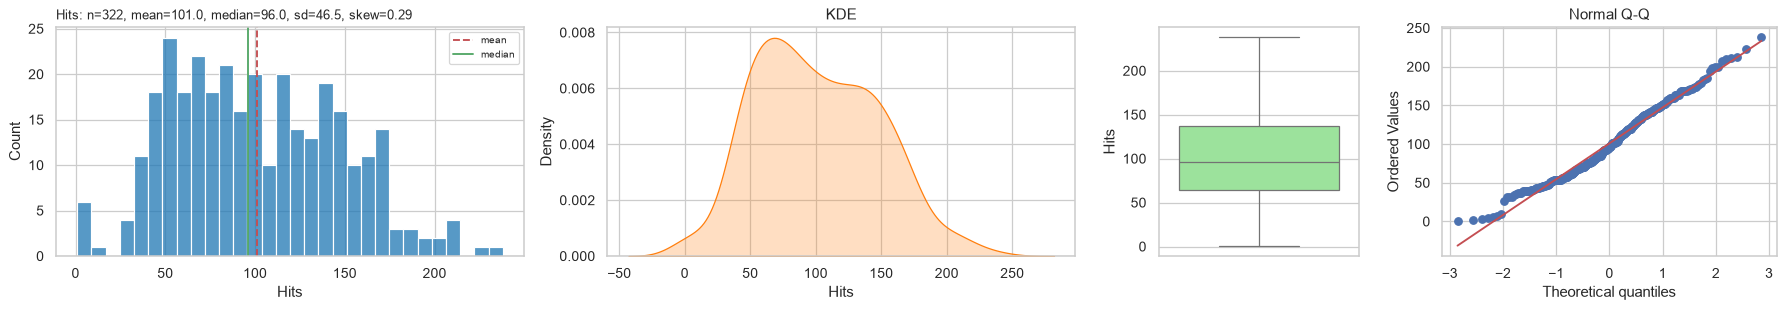

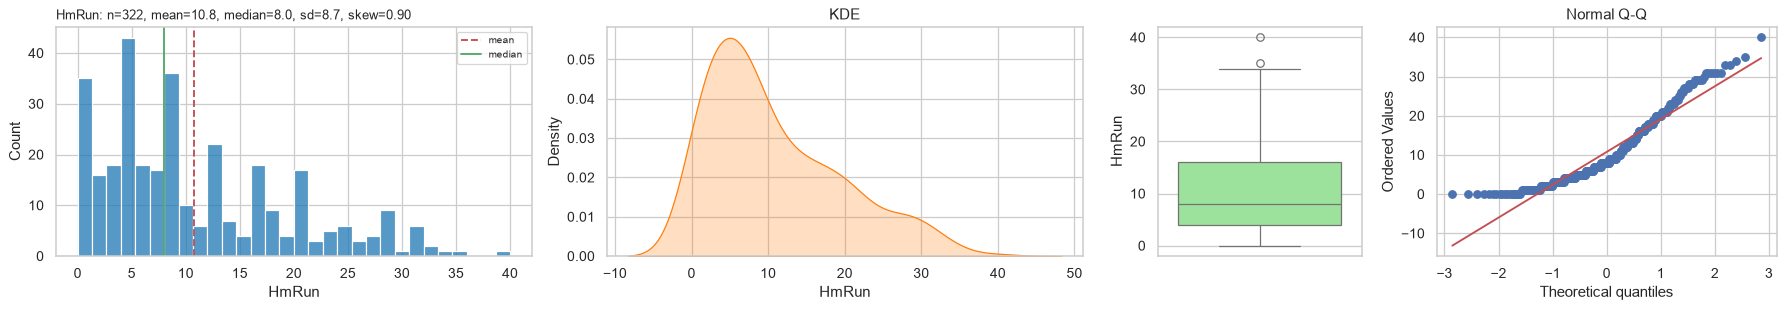

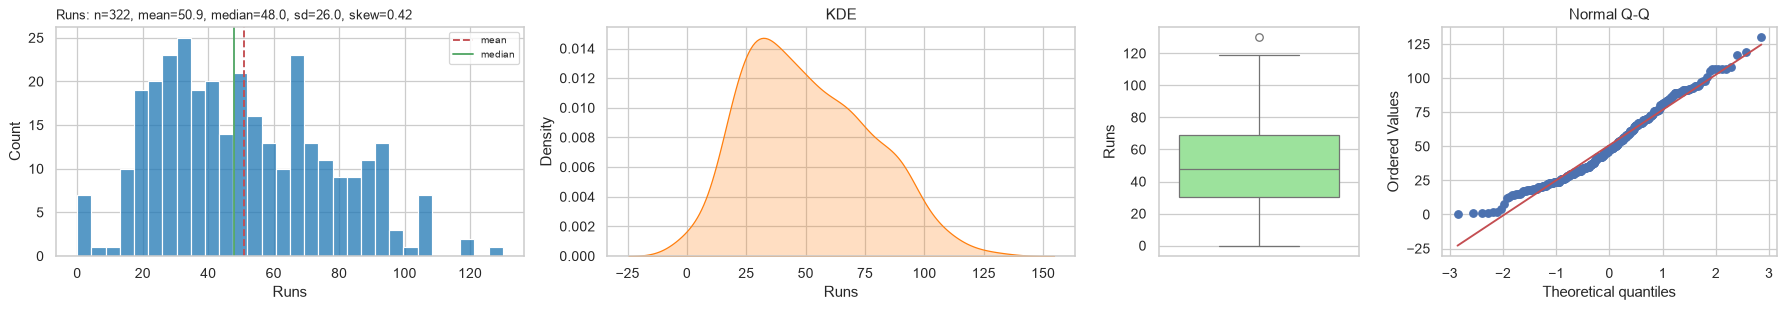

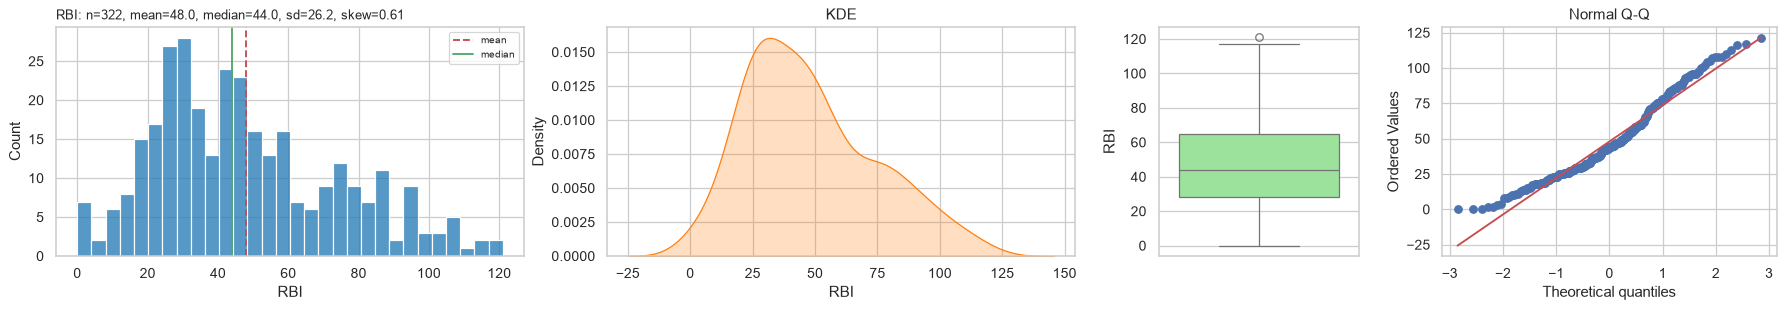

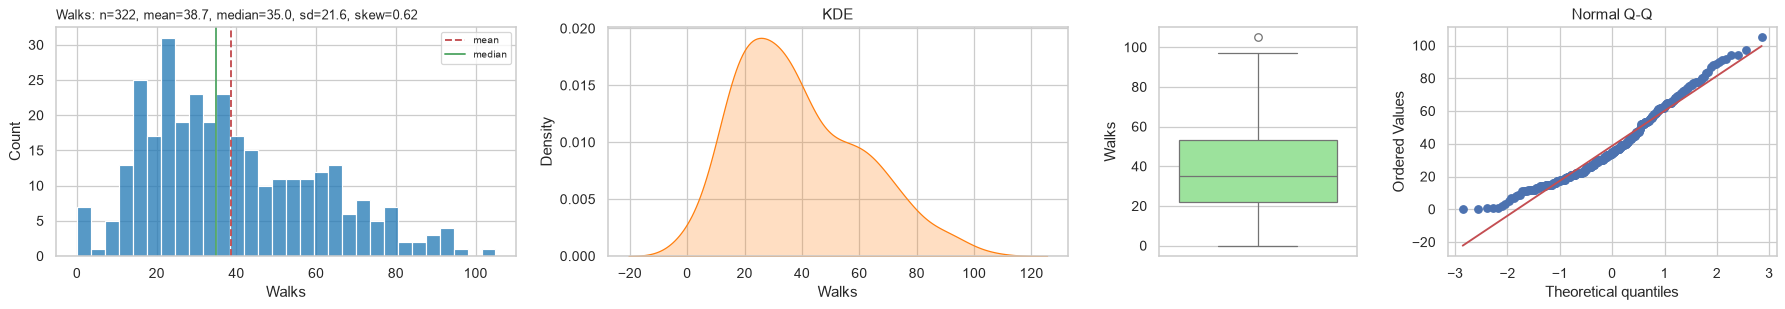

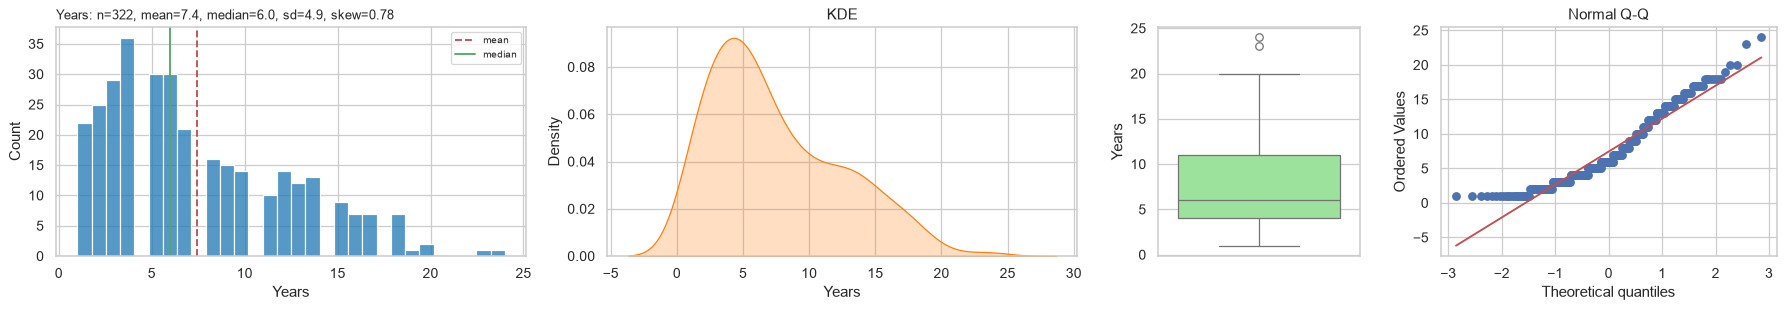

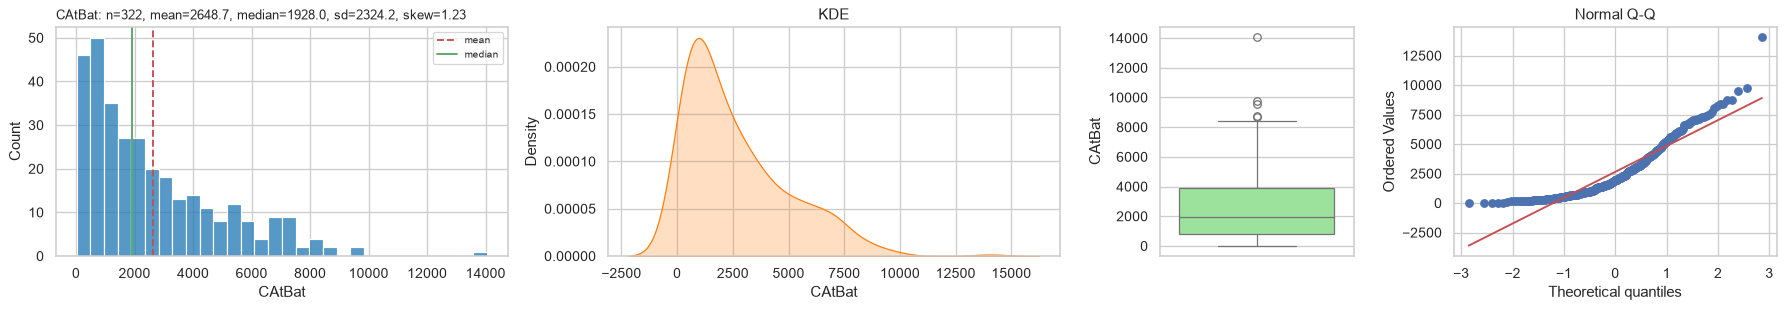

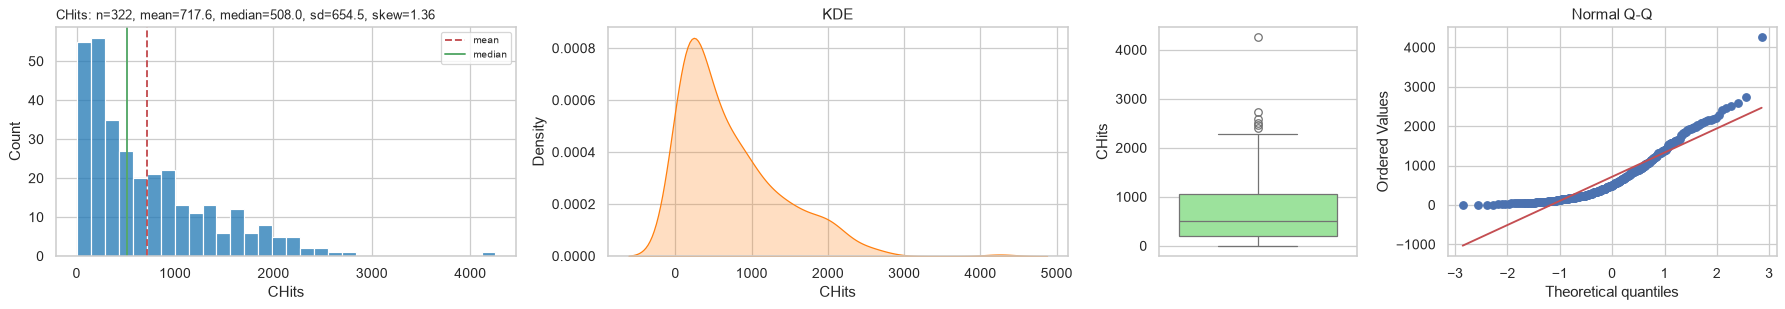

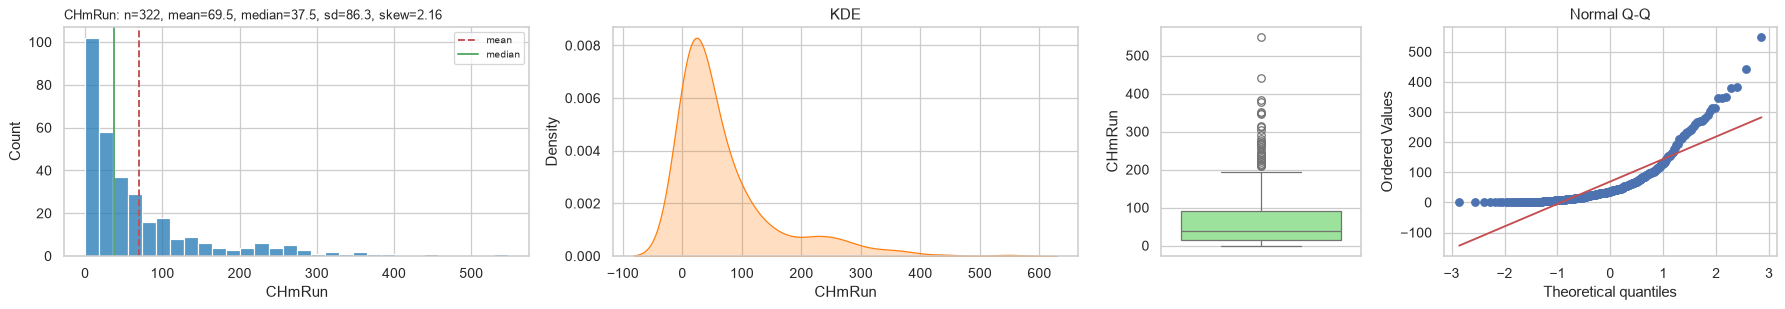

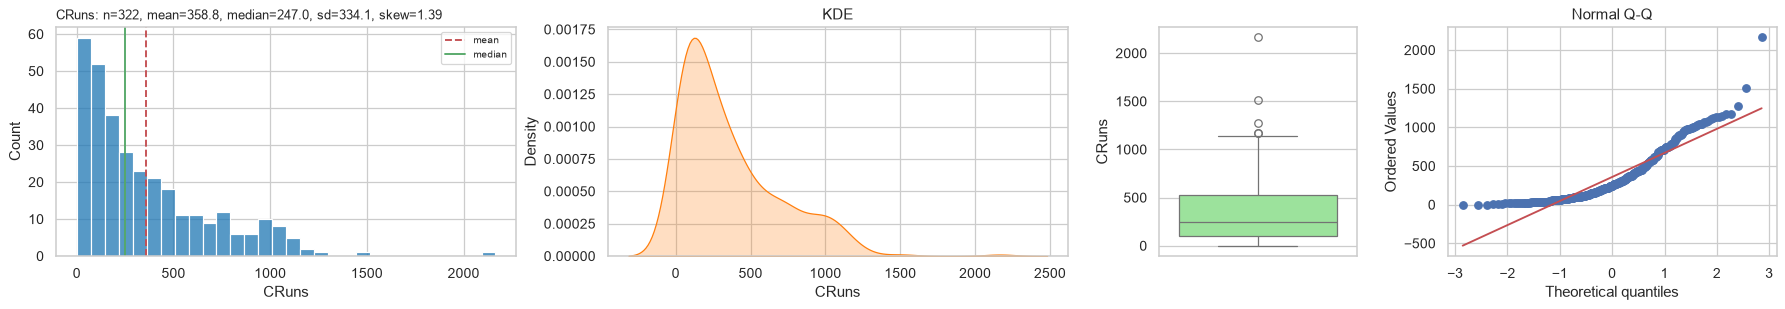

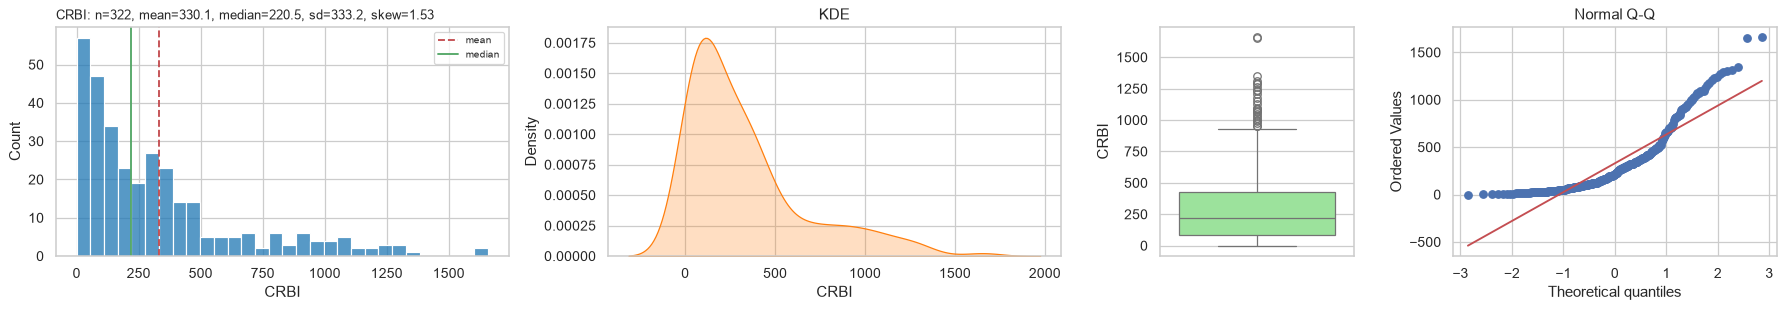

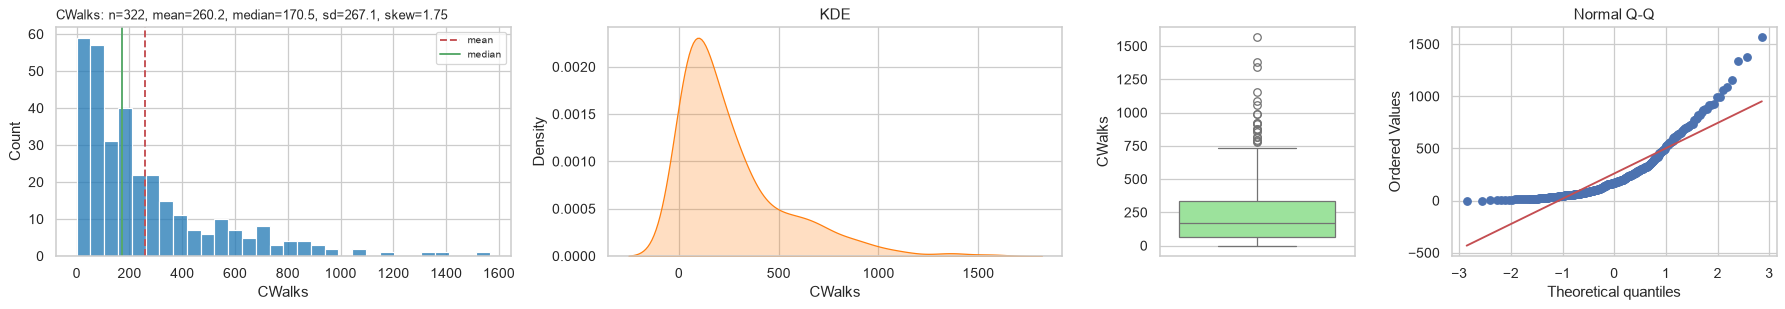

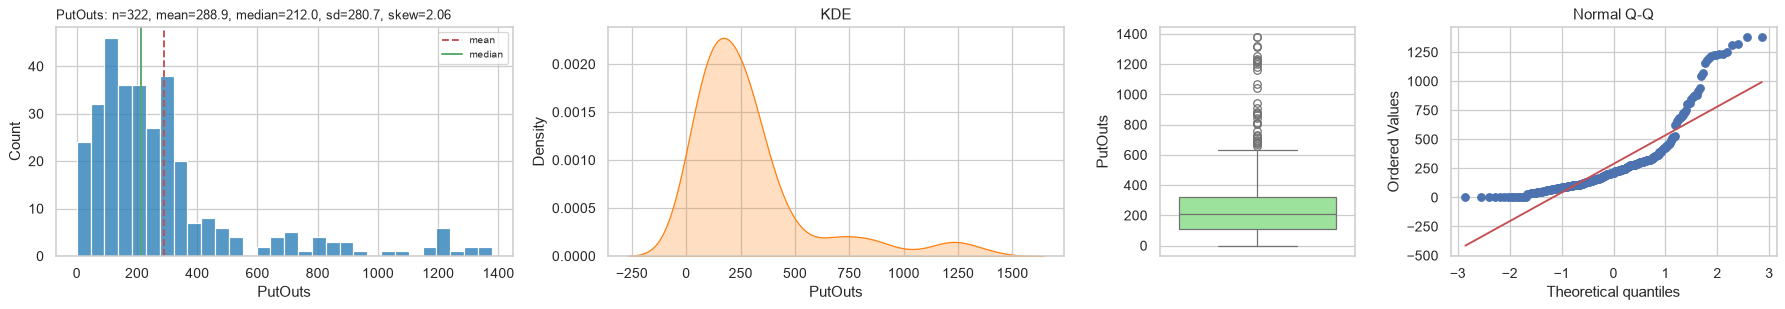

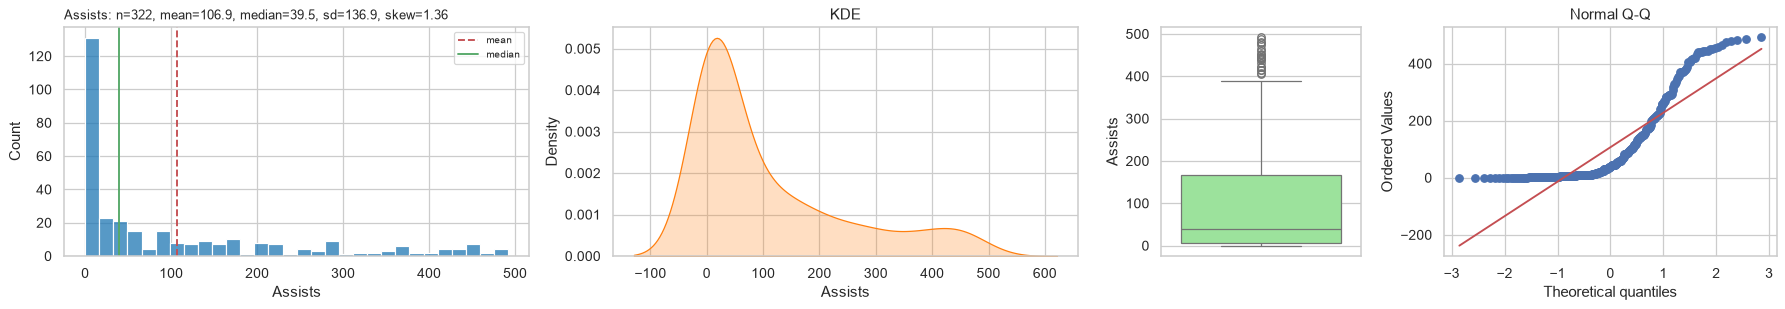

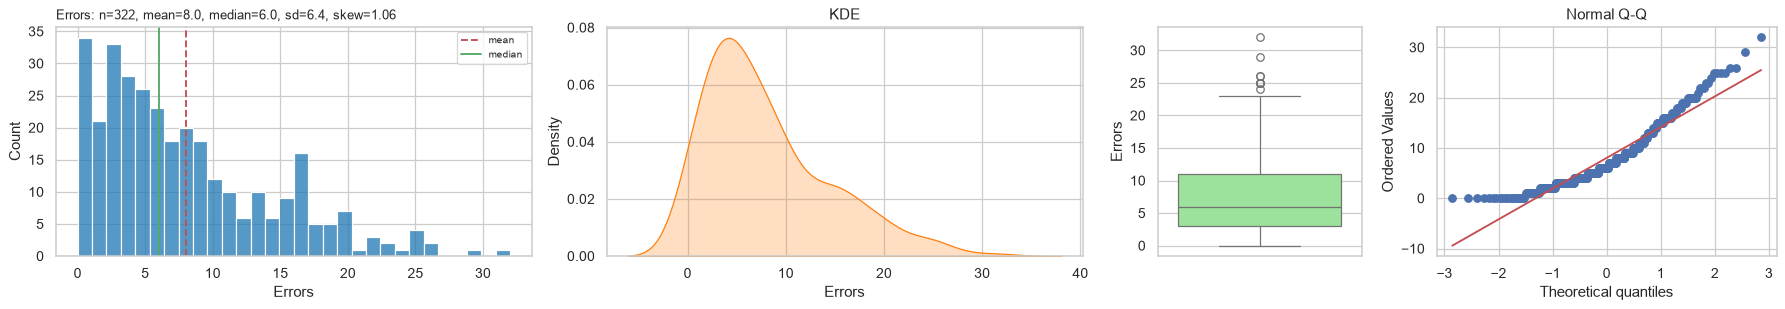

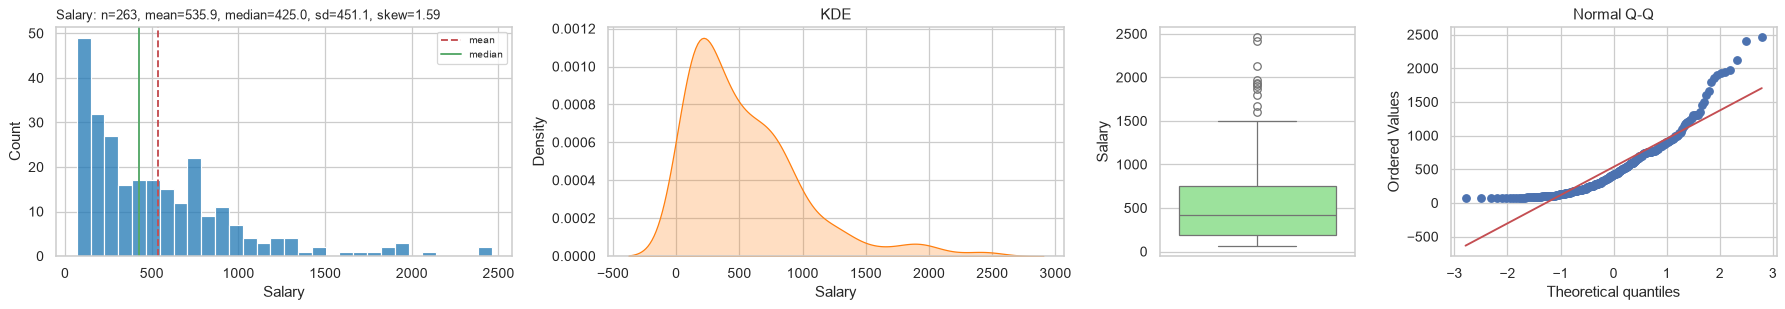

In [67]:
def univariate(col):
    d = df[col].dropna()
    fig, axes = plt.subplots(1, 4, figsize=(20, 3.6), gridspec_kw={"width_ratios": [1.4, 1.4, .6, 1]})
    sns.histplot(d, bins=30, ax=axes[0], color="tab:blue"); axes[0].axvline(d.mean(), c="r", ls="--", label="mean"); axes[0].axvline(d.median(), c="g", label="median"); axes[0].legend(fontsize=8)
    sns.kdeplot(d, ax=axes[1], fill=True, color="tab:orange"); axes[1].set_title("KDE")
    sns.boxplot(y=d, ax=axes[2], color="lightgreen")
    stats.probplot(d, dist="norm", plot=axes[3]); axes[3].set_title("Normal Q-Q")
    axes[0].set_title(f"{col}: n={len(d)}, mean={d.mean():.1f}, median={d.median():.1f}, sd={d.std():.1f}, skew={d.skew():.2f}", loc="left", fontsize=10)
    plt.tight_layout(); plt.show()

for c in num_cols:
    univariate(c)

In [68]:
shape = pd.DataFrame({"skew": df[num_cols].skew(), "kurtosis": df[num_cols].kurt(), "IQR_outliers": flags["IQR (1.5)"].sum()})
shape["shape"] = pd.cut(shape["skew"], [-np.inf, -1, -.5, .5, 1, np.inf], labels=["strong left", "moderate left", "approx. symmetric", "moderate right", "strong right"])
shape.sort_values("skew")

,skew,kurtosis,IQR_outliers,shape
AtBat,-0.078,-0.889,0,approx. symmetric
Hits,0.291,-0.503,0,approx. symmetric
Runs,0.416,-0.518,1,approx. symmetric
RBI,0.608,-0.301,1,moderate right
Walks,0.620,-0.258,1,moderate right
Years,0.780,-0.147,2,moderate right
HmRun,0.905,0.040,2,moderate right
Errors,1.055,0.688,9,strong right
CAtBat,1.227,1.502,5,strong right
CHits,1.356,2.354,6,strong right


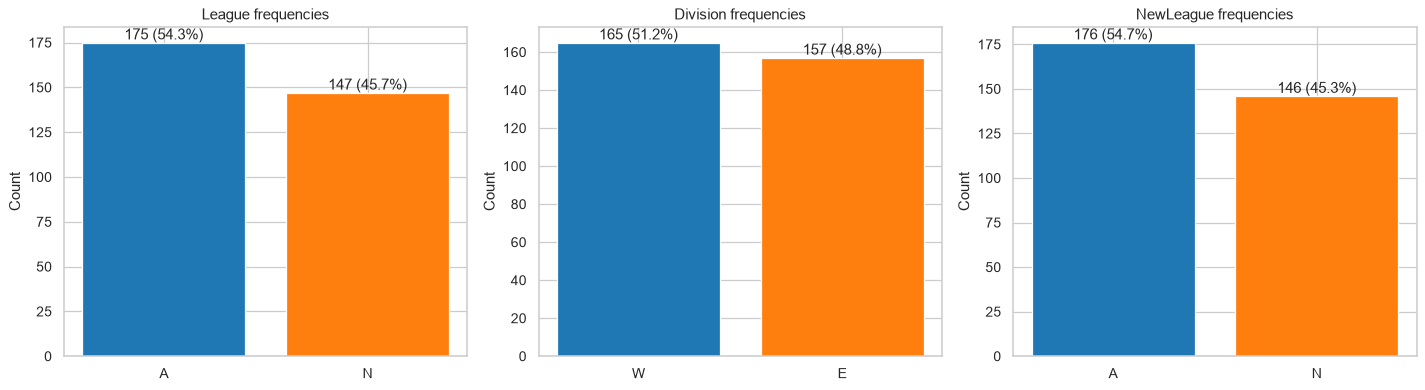

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, cat_cols):
    vc = df[c].value_counts()
    bars = ax.bar(vc.index.astype(str), vc.values, color=["tab:blue", "tab:orange"])
    ax.bar_label(bars, labels=[f"{n} ({p:.1%})" for n, p in zip(vc.values, vc.values / vc.sum())])
    ax.set_title(f"{c} frequencies"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

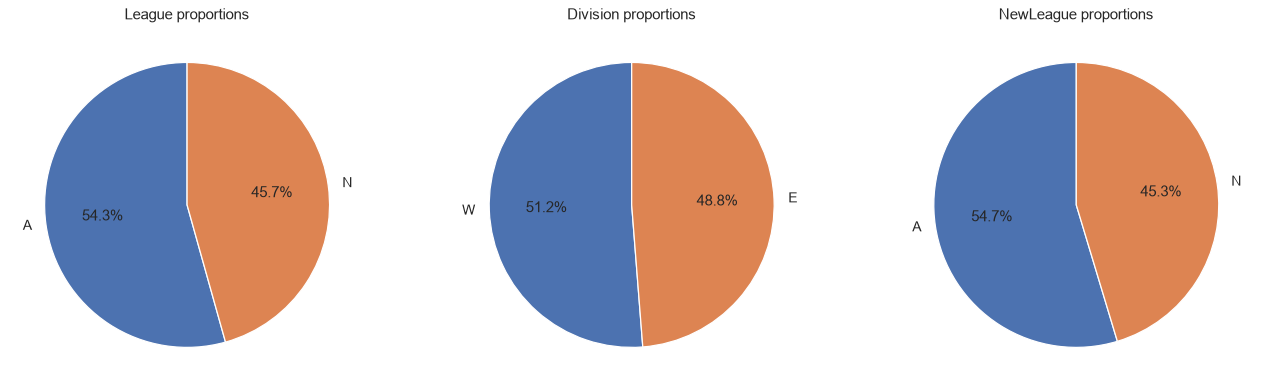

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, cat_cols):
    df[c].value_counts().plot.pie(ax=ax, autopct="%1.1f%%", startangle=90); ax.set_ylabel(""); ax.set_title(f"{c} proportions")
plt.tight_layout(); plt.show()

## 11. Bivariate and Multivariate Analysis

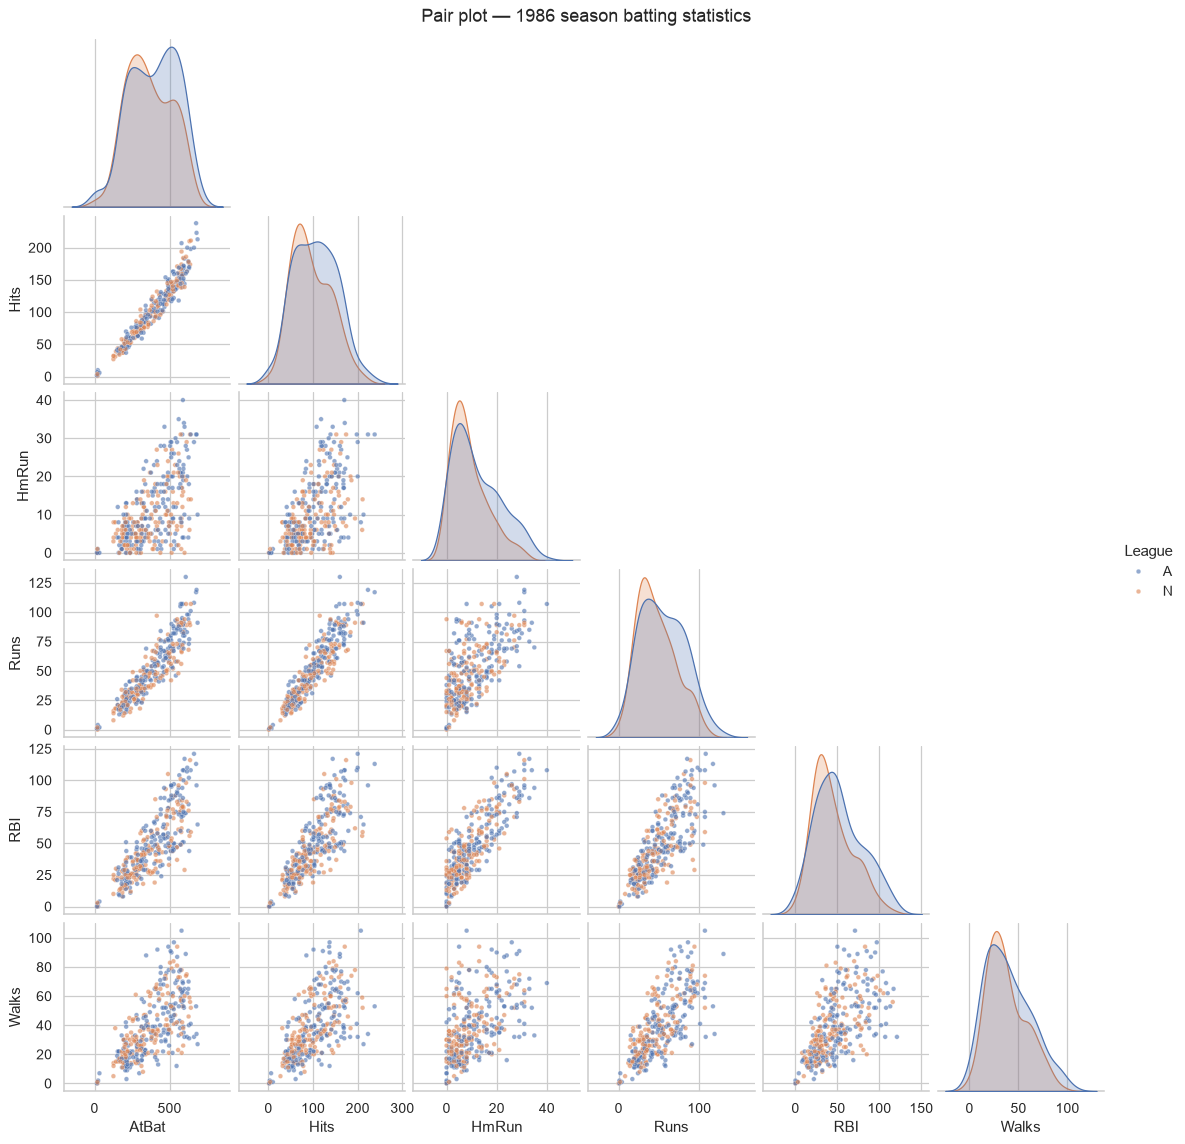

In [71]:
season = ["AtBat","Hits","HmRun","Runs","RBI","Walks"]
g = sns.pairplot(df[season + ["League"]], hue="League", corner=True, plot_kws={"s": 14, "alpha": .6}, height=2.1)
g.figure.suptitle("Pair plot — 1986 season batting statistics", y=1.01); plt.show()

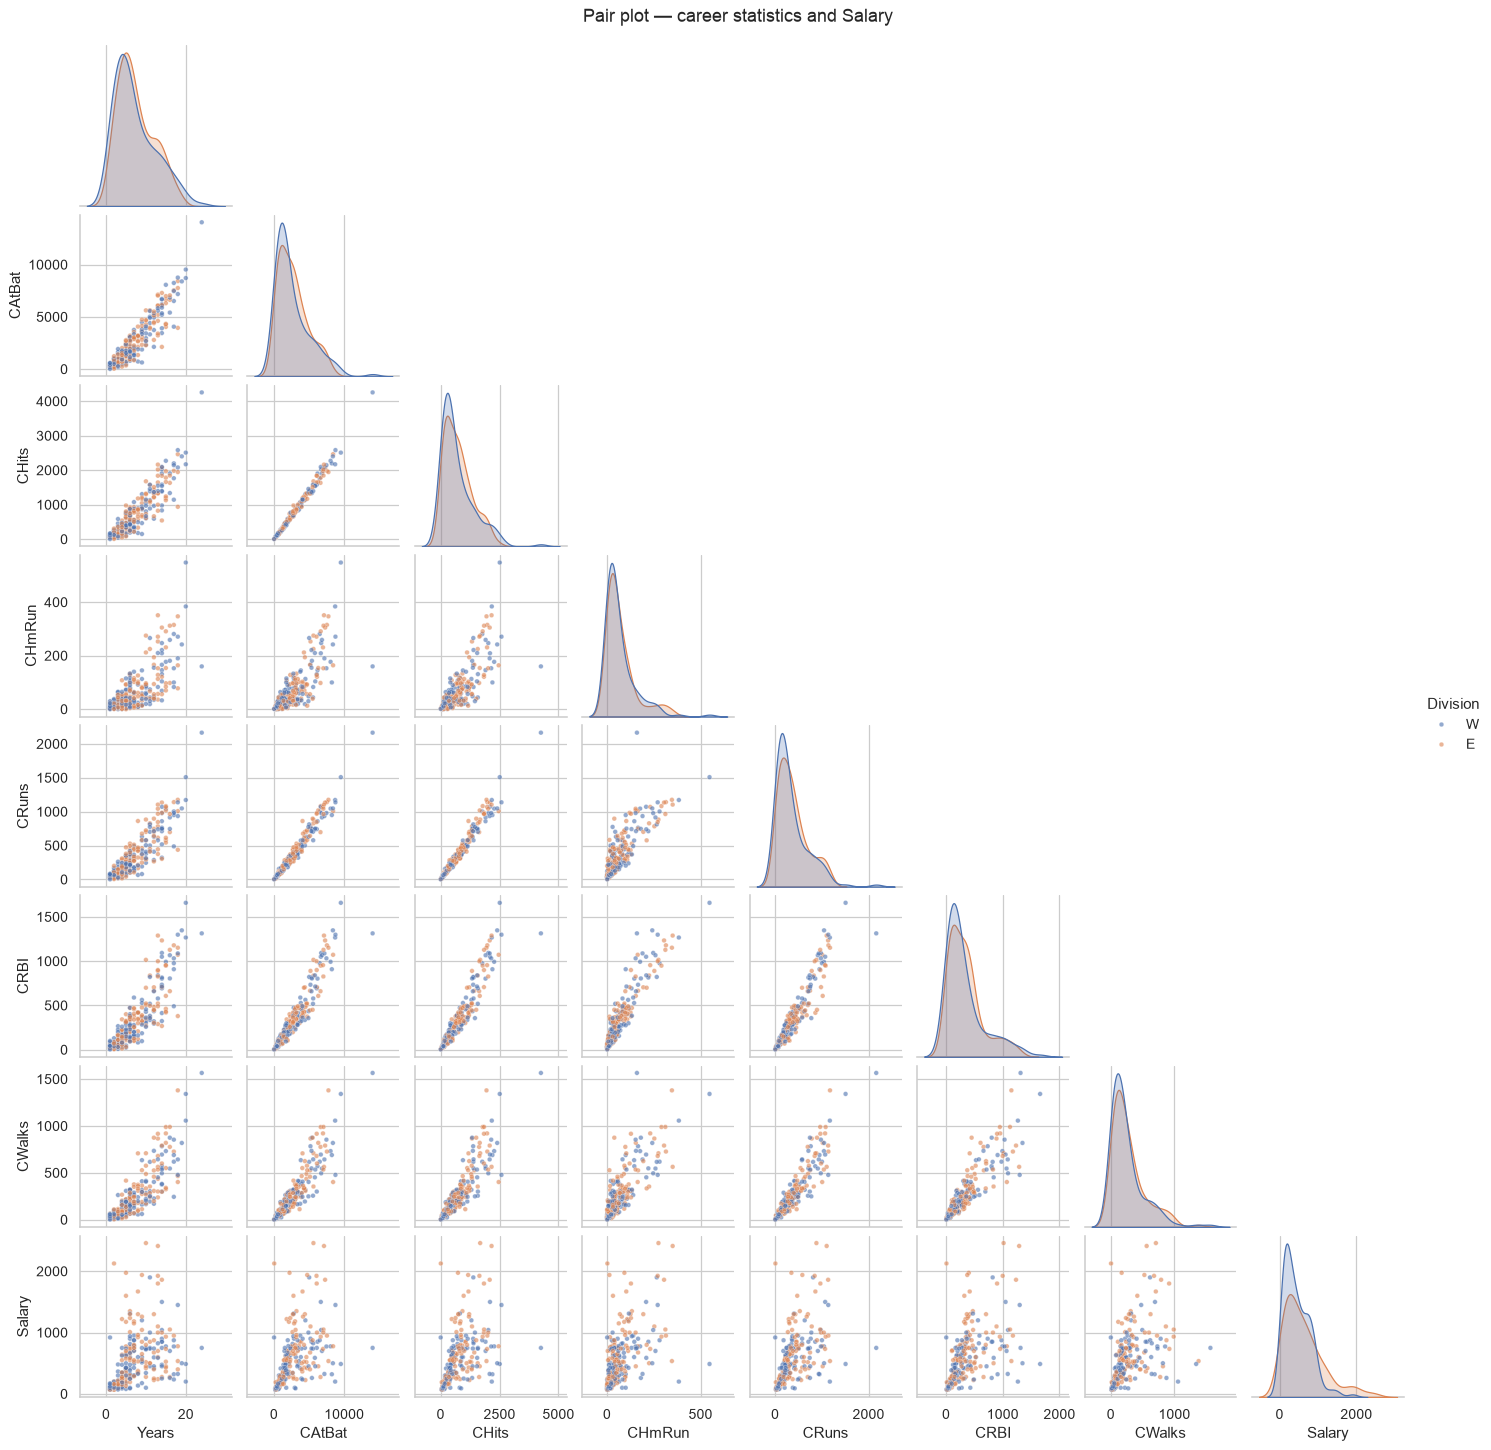

In [72]:
career = ["Years","CAtBat","CHits","CHmRun","CRuns","CRBI","CWalks","Salary"]
g = sns.pairplot(df[career + ["Division"]].dropna(), hue="Division", corner=True, plot_kws={"s": 14, "alpha": .6}, height=2.0)
g.figure.suptitle("Pair plot — career statistics and Salary", y=1.01); plt.show()

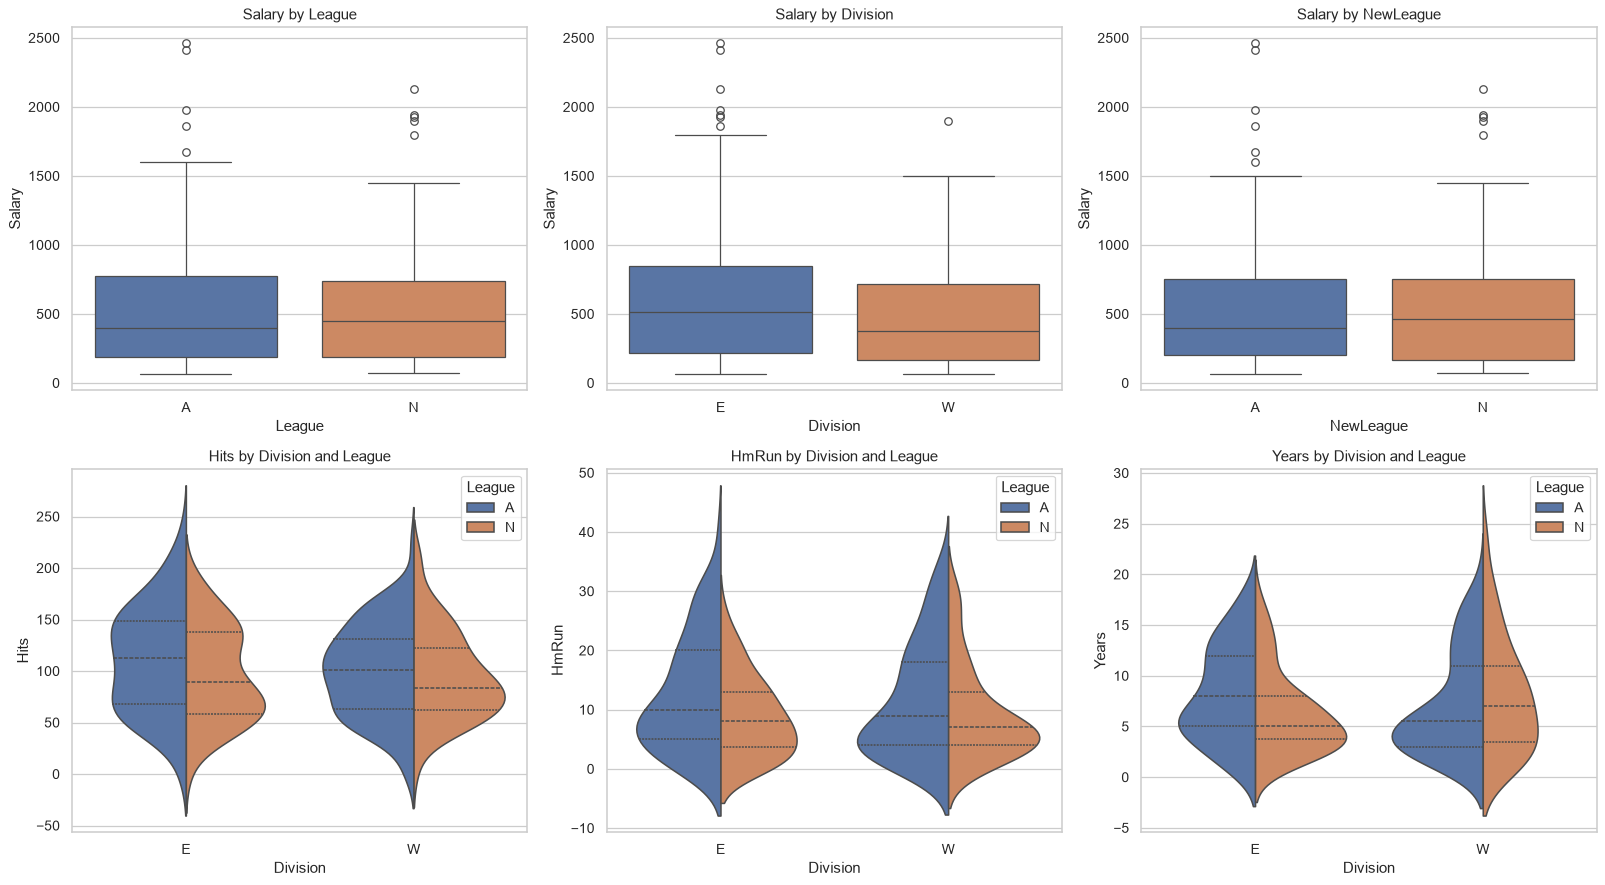

In [73]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes[0], cat_cols):
    sns.boxplot(data=df, x=c, y="Salary", ax=ax, hue=c, legend=False); ax.set_title(f"Salary by {c}")
for ax, c in zip(axes[1], ["Hits", "HmRun", "Years"]):
    sns.violinplot(data=df, x="Division", y=c, hue="League", split=True, ax=ax, inner="quart"); ax.set_title(f"{c} by Division and League")
plt.tight_layout(); plt.show()

In [74]:
cmp = []
for c in cat_cols:
    for v in ["Salary", "Hits", "HmRun", "Years", "PutOuts", "Assists"]:
        a, b = [df.loc[df[c] == lv, v].dropna() for lv in sorted(df[c].unique())]
        cmp.append({"group": c, "variable": v, "median_1": a.median(), "median_2": b.median(), "MannWhitney_p": stats.mannwhitneyu(a, b).pvalue})
pd.DataFrame(cmp)

,group,variable,median_1,median_2,MannWhitney_p
0,League,Salary,400.000,450.0,0.886
1,League,Hits,103.000,86.0,0.071
2,League,HmRun,9.000,7.0,0.008
3,League,Years,6.000,6.0,0.305
4,League,PutOuts,227.000,206.0,0.869
5,League,Assists,32.000,45.0,0.109
6,Division,Salary,517.143,375.0,0.017
7,Division,Hits,100.000,95.0,0.297
8,Division,HmRun,9.000,8.0,0.567
9,Division,Years,6.000,6.0,0.818


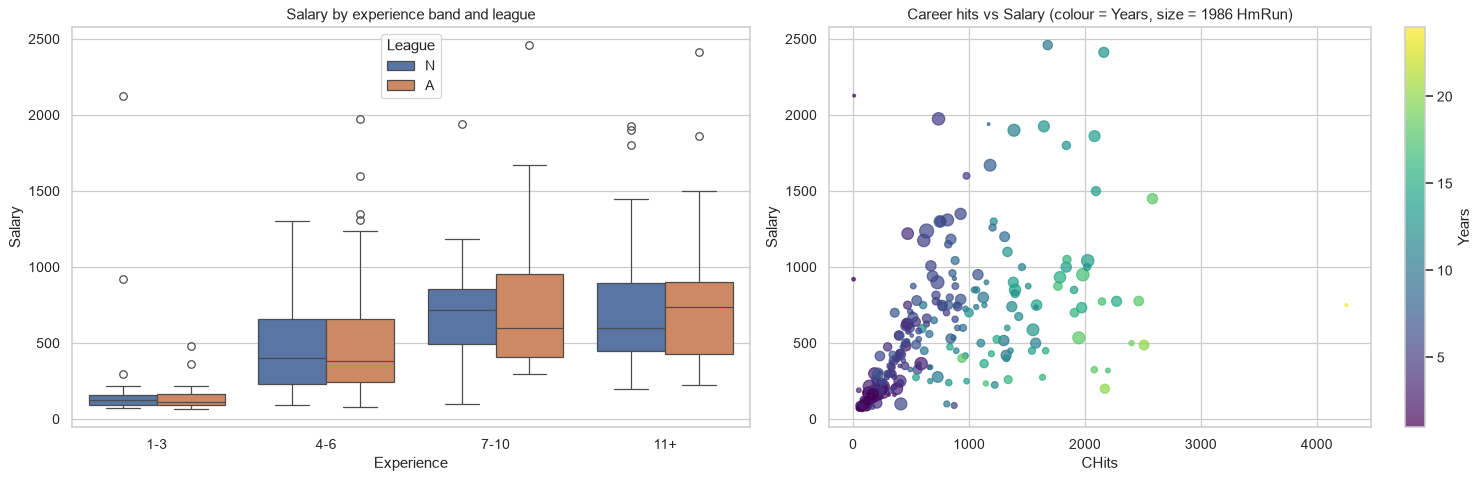

In [75]:
dfp = df.dropna().copy()
dfp["Experience"] = pd.cut(dfp.Years, [0, 3, 6, 10, 25], labels=["1-3", "4-6", "7-10", "11+"])
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
sns.boxplot(data=dfp, x="Experience", y="Salary", hue="League", ax=axes[0]); axes[0].set_title("Salary by experience band and league")
sc = axes[1].scatter(dfp.CHits, dfp.Salary, c=dfp.Years, s=dfp.HmRun * 3 + 5, cmap="viridis", alpha=.7)
plt.colorbar(sc, ax=axes[1], label="Years"); axes[1].set_xlabel("CHits"); axes[1].set_ylabel("Salary")
axes[1].set_title("Career hits vs Salary (colour = Years, size = 1986 HmRun)")
plt.tight_layout(); plt.show()

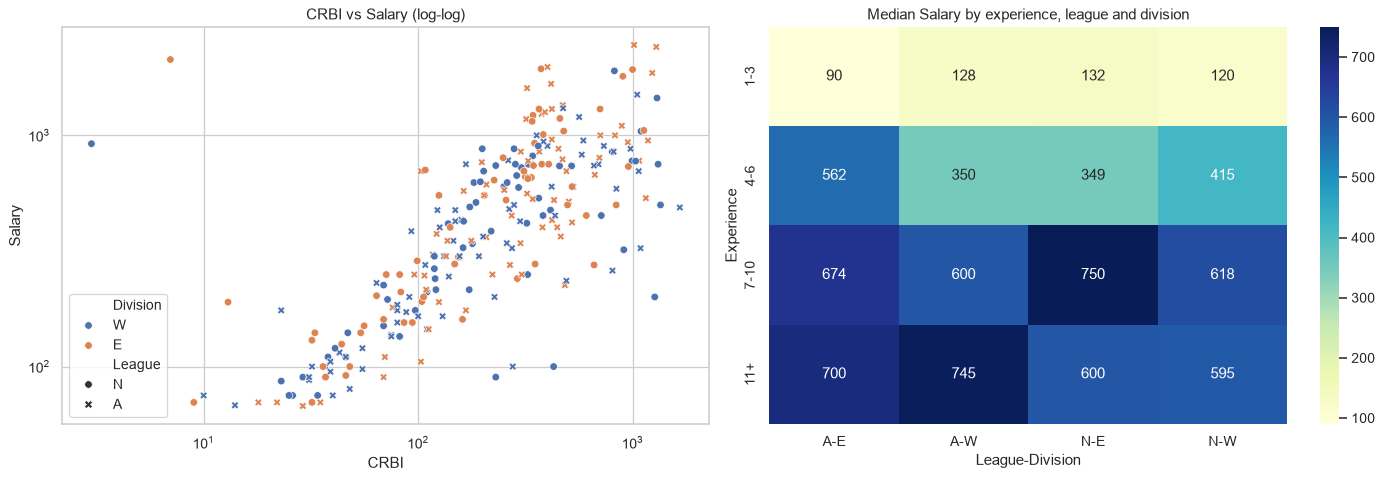

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=dfp, x="CRBI", y="Salary", hue="Division", style="League", ax=axes[0]); axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("CRBI vs Salary (log-log)")
sns.heatmap(dfp.pivot_table(index="Experience", columns=["League","Division"], values="Salary", aggfunc="median", observed=True), annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("Median Salary by experience, league and division")
plt.tight_layout(); plt.show()

Correlation measures association, not causation: career totals correlate with salary partly because both grow with years played (a confounder), not necessarily because one causes the other.

## 12. Exploratory Data Analysis for Structured Data (Experiment 4)

In [77]:
schema = pd.DataFrame({"dtype": df.dtypes.astype(str), "role": pd.Series(role), "non_null": df.count(), "missing": df.isna().sum(),
                       "unique": df.nunique(), "min": df.min(numeric_only=True), "max": df.max(numeric_only=True)})
schema["group"] = ["season-batting" if c in season else "career-batting" if c.startswith("C") and c not in cat_cols else
                   "fielding" if c in ["PutOuts","Assists","Errors"] else "categorical" if c in cat_cols else "other" for c in df.columns]
schema

,dtype,role,non_null,missing,unique,min,max,group
Assists,int64,Predictor,322,0,161,0.0,492.0,season-batting
AtBat,int64,Predictor,322,0,247,16.0,687.0,season-batting
CAtBat,int64,Predictor,322,0,314,19.0,14053.0,season-batting
CHits,int64,Predictor,322,0,288,4.0,4256.0,season-batting
CHmRun,int64,Predictor,322,0,146,0.0,548.0,season-batting
CRBI,int64,Predictor,322,0,262,0.0,1659.0,season-batting
CRuns,int64,Predictor,322,0,261,1.0,2165.0,other
CWalks,int64,Predictor,322,0,248,0.0,1566.0,career-batting
Division,str,Predictor,322,0,2,NaN,NaN,career-batting
Errors,int64,Predictor,322,0,29,0.0,32.0,career-batting


In [78]:
agg = df.groupby(["League", "Division"], observed=True).agg(
    players=("Salary", "size"), salary_known=("Salary", "count"), salary_mean=("Salary", "mean"), salary_median=("Salary", "median"),
    hits_mean=("Hits", "mean"), hr_mean=("HmRun", "mean"), years_mean=("Years", "mean"), errors_mean=("Errors", "mean"))
agg

players  salary_known  salary_mean  salary_median  hits_mean  hr_mean  years_mean  errors_mean
League Division                                                                                                
A      E              85            68      670.850          532.5    111.129   12.706       8.212        8.047
       W              90            71      418.594          325.0     99.833   11.689       7.133        7.144
N      E              72            61      572.348          450.0     96.472    8.819       6.306        8.361
       W              75            63      487.259          450.0     95.373    9.347       8.040        8.800

In [79]:
c = df[num_cols].corr().abs()
upper = c.where(np.triu(np.ones(c.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print("Most strongly related variable pairs:")
upper.head(15).to_frame("|r|")

Most strongly related variable pairs:


,,|r|
CAtBat,CHits,0.995
CHits,CRuns,0.985
CAtBat,CRuns,0.983
AtBat,Hits,0.968
CAtBat,CRBI,0.949
CHits,CRBI,0.945
CRuns,CRBI,0.944
CHmRun,CRBI,0.929
CRuns,CWalks,0.928
Hits,Runs,0.922


,pearson,spearman,pearson_p
CRBI,0.567,0.760,9.071e-24
CRuns,0.563,0.767,2.312e-23
CHits,0.549,0.759,4.263e-22
CAtBat,0.526,0.750,3.978e-20
CHmRun,0.525,0.671,5.010e-20
CWalks,0.490,0.735,2.817e-17
RBI,0.449,0.474,1.757e-14
Walks,0.444,0.440,4.014e-14
Hits,0.439,0.479,8.531e-14
Runs,0.420,0.441,1.180e-12


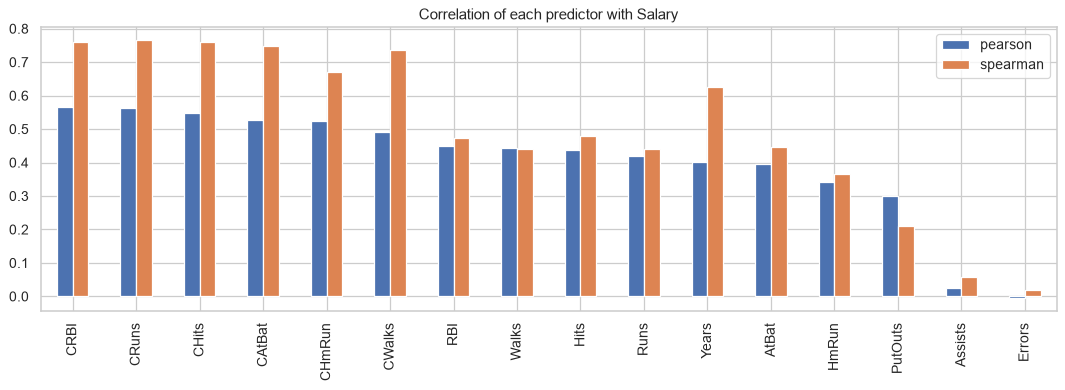

In [80]:
d = df.dropna()
dep = pd.DataFrame({"pearson": d[feat].corrwith(d.Salary), "spearman": d[feat].corrwith(d.Salary, method="spearman")})
dep["pearson_p"] = [stats.pearsonr(d[c], d.Salary)[1] for c in feat]
dep = dep.sort_values("pearson", ascending=False)
display(dep)
dep[["pearson", "spearman"]].plot.bar(figsize=(12, 4.5))
plt.title("Correlation of each predictor with Salary"); plt.tight_layout(); plt.show()

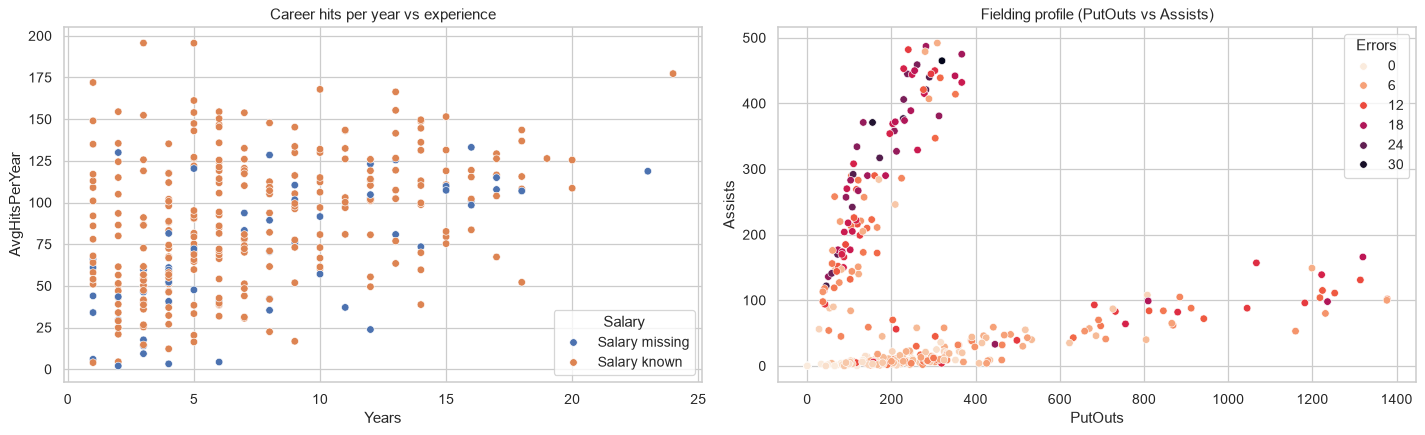

In [81]:
d = df.copy()
d["AvgHitsPerYear"] = d.CHits / d.Years
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=d, x="Years", y="AvgHitsPerYear", hue=d.Salary.isna().map({True: "Salary missing", False: "Salary known"}), ax=axes[0])
axes[0].set_title("Career hits per year vs experience")
sns.scatterplot(data=d, x="PutOuts", y="Assists", hue="Errors", palette="rocket_r", ax=axes[1]); axes[1].set_title("Fielding profile (PutOuts vs Assists)")
plt.tight_layout(); plt.show()

Structured-data observations: 322 rows × 20 columns, 3 binary categoricals; only `Salary` has missing values (59, 18.3%); career variables are strongly right-skewed and mutually collinear (r > 0.9); fielding variables show distinct clusters reflecting playing position; salary rises with experience and career output.

## 13. Feature Engineering

In [82]:
fe = df.copy()
fe["BattingAvg"] = fe.Hits / fe.AtBat.replace(0, np.nan)
fe["CareerBattingAvg"] = fe.CHits / fe.CAtBat.replace(0, np.nan)
fe["HRRate"] = fe.HmRun / fe.AtBat.replace(0, np.nan)
fe["WalkRate"] = fe.Walks / (fe.AtBat + fe.Walks).replace(0, np.nan)
fe["CAtBatPerYear"] = fe.CAtBat / fe.Years
fe["CHitsPerYear"] = fe.CHits / fe.Years
fe["CHmRunPerYear"] = fe.CHmRun / fe.Years
fe["FieldingChances"] = fe.PutOuts + fe.Assists + fe.Errors
fe["FieldingPct"] = (fe.PutOuts + fe.Assists) / fe.FieldingChances.replace(0, np.nan)
fe["LogSalary"] = np.log(fe.Salary)
fe["LogCAtBat"] = np.log1p(fe.CAtBat)
fe["ExperienceBand"] = pd.cut(fe.Years, [0, 3, 6, 10, 25], labels=["1-3", "4-6", "7-10", "11+"])
fe["SwitchedLeague"] = (fe.League != fe.NewLeague).astype(int)
new_feats = ["BattingAvg","CareerBattingAvg","HRRate","WalkRate","CAtBatPerYear","CHitsPerYear","CHmRunPerYear","FieldingChances","FieldingPct","LogSalary","LogCAtBat"]
fe[new_feats].describe().T

,count,mean,std,min,25%,50%,75%,max
BattingAvg,322.0,0.260,0.036,0.050,0.240,0.259,0.278,0.455
CareerBattingAvg,322.0,0.261,0.026,0.143,0.248,0.263,0.278,0.352
HRRate,322.0,0.027,0.018,0.000,0.013,0.026,0.039,0.077
WalkRate,322.0,0.091,0.034,0.000,0.068,0.088,0.112,0.216
CAtBatPerYear,322.0,323.486,133.467,10.250,218.000,332.875,429.981,642.667
CHitsPerYear,322.0,86.412,39.522,2.000,55.104,86.167,116.497,195.667
CHmRunPerYear,322.0,8.178,6.633,0.000,2.938,6.045,12.094,30.000
FieldingChances,322.0,403.891,311.876,0.000,202.250,316.000,520.250,1503.000
FieldingPct,307.0,0.976,0.019,0.865,0.969,0.981,0.989,1.000
LogSalary,263.0,5.927,0.889,4.212,5.247,6.052,6.620,7.808


In [83]:
print("NaNs created by ratios:", fe[new_feats].isna().sum()[lambda s: s > 0].to_dict())
fe[new_feats + ["Salary"]].corr()["Salary"].drop(["Salary"]).sort_values().to_frame("corr_with_Salary")

NaNs created by ratios: {'FieldingPct': 15, 'LogSalary': 59}


,corr_with_Salary
HRRate,0.150
WalkRate,0.161
FieldingPct,0.176
BattingAvg,0.198
FieldingChances,0.281
CHmRunPerYear,0.441
CareerBattingAvg,0.482
CAtBatPerYear,0.505
LogCAtBat,0.531
CHitsPerYear,0.559


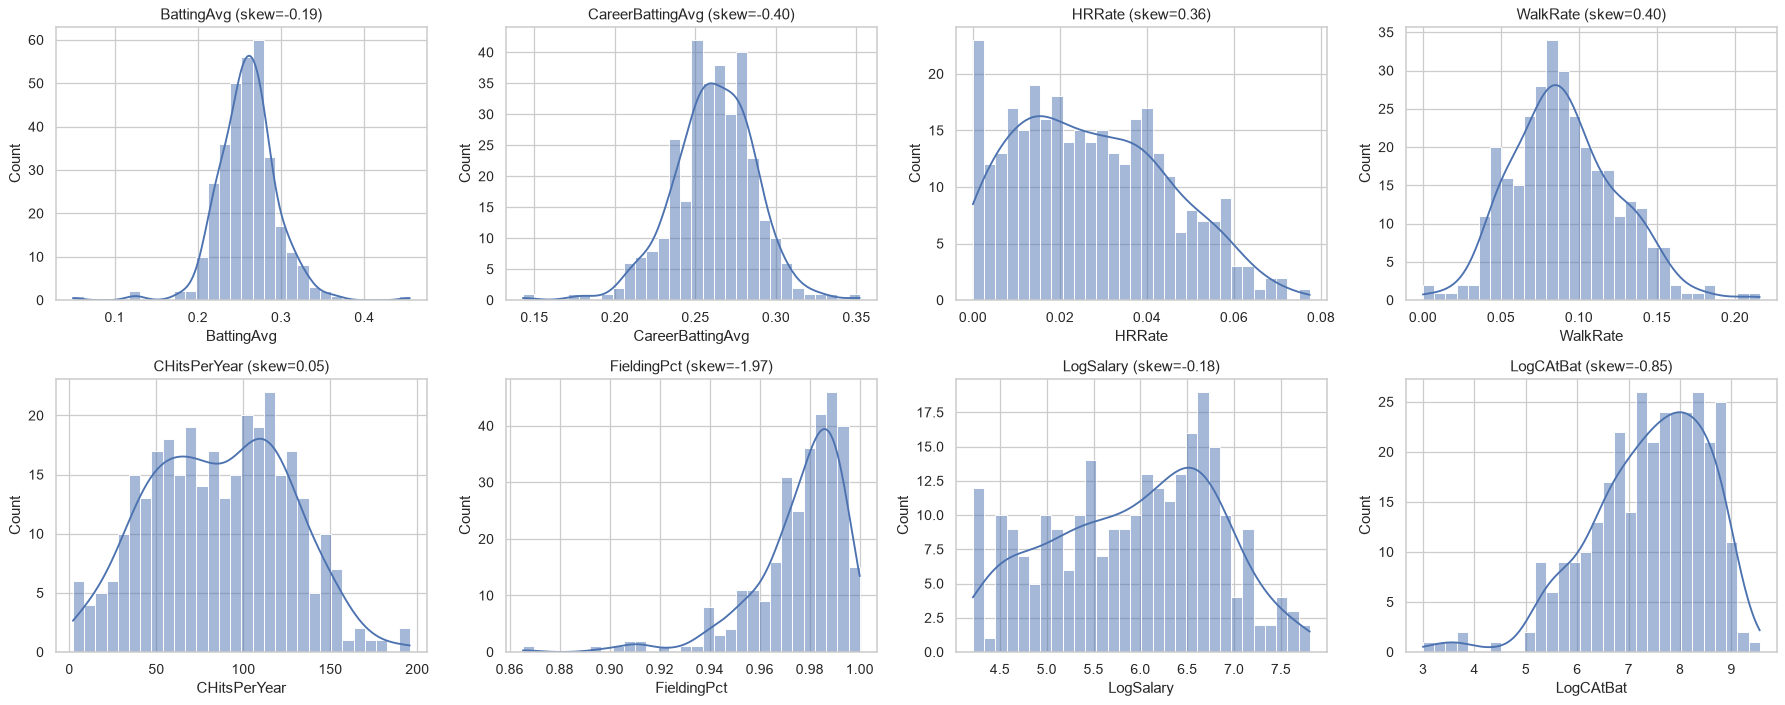

In [84]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), ["BattingAvg","CareerBattingAvg","HRRate","WalkRate","CHitsPerYear","FieldingPct","LogSalary","LogCAtBat"]):
    sns.histplot(fe[c].dropna(), kde=True, ax=ax, bins=30); ax.set_title(f"{c} (skew={fe[c].skew():.2f})")
plt.tight_layout(); plt.show()

In [85]:
ohe = OneHotEncoder(drop="if_binary", sparse_output=False)
enc = pd.DataFrame(ohe.fit_transform(fe[cat_cols]), columns=ohe.get_feature_names_out(cat_cols))
display(enc.head())
fe["ExperienceBand_ord"] = fe.ExperienceBand.cat.codes
pd.crosstab(fe.ExperienceBand, fe.ExperienceBand_ord)

,League_N,Division_W,NewLeague_N
0,0.0,0.0,0.0
1,1.0,1.0,1.0
2,0.0,1.0,0.0
3,1.0,0.0,1.0
4,1.0,0.0,1.0


ExperienceBand_ord,0,1,2,3
ExperienceBand,,,,
1-3,76,0,0,0
4-6,0,96,0,0
7-10,0,0,66,0
11+,0,0,0,84


In [86]:
corr_fe = fe[[c for c in num_cols if c != "Salary"]].corr().abs()
upper = corr_fe.where(np.triu(np.ones(corr_fe.shape, dtype=bool), 1))
redundant = [c for c in upper.columns if (upper[c] > 0.95).any()]
print("Redundant (|r| > 0.95 with an earlier column):", redundant)

Redundant (|r| > 0.95 with an earlier column): ['Hits', 'CHits', 'CRuns']


Ratios (batting average, rates per at-bat/year) normalise counting stats by opportunity; `ExperienceBand` is a genuinely ordered bin and so receives ordinal codes; `League/Division/NewLeague` are nominal and are one-hot encoded; `SwitchedLeague` captures the League→NewLeague change.

## 14. K-Means Clustering (Experiment 5)

In [87]:
K_USER = 4  # user-specified number of clusters
km_feats = ["AtBat","Hits","HmRun","Runs","RBI","Walks","Years","CAtBat","CHits","CHmRun","CRuns","CRBI","CWalks","PutOuts","Assists","Errors"]
km_data = df[km_feats].copy()
print("Missing in clustering features:", int(km_data.isna().sum().sum()), "| rows:", len(km_data))
km_X = StandardScaler().fit_transform(km_data)

Missing in clustering features: 0 | rows: 322


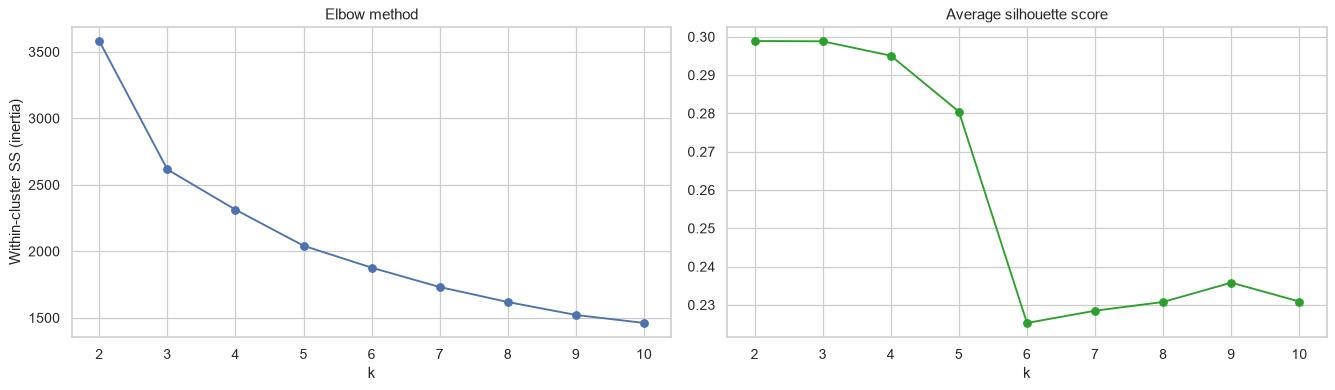

k,2,3,4,5,6,7,8,9,10
inertia,3582.037,2615.922,2313.603,2042.54,1877.408,1731.657,1619.137,1521.892,1461.639
silhouette,0.299,0.299,0.295,0.28,0.225,0.228,0.231,0.236,0.231


In [88]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(km_X)
    inertia.append(m.inertia_); sil.append(silhouette_score(km_X, m.labels_))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Within-cluster SS (inertia)")
axes[1].plot(ks, sil, "o-", color="tab:green"); axes[1].set_title("Average silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).set_index("k").T

In [89]:
kmeans = KMeans(n_clusters=K_USER, n_init=50, random_state=SEED).fit(km_X)
labels = kmeans.labels_
clustered = df.copy(); clustered["Cluster"] = labels
print("Cluster sizes:"); print(clustered.Cluster.value_counts().sort_index().to_frame("n").T)
print(f"Inertia = {kmeans.inertia_:.1f}, silhouette = {silhouette_score(km_X, labels):.3f}")

Cluster sizes:
Cluster   0    1   2   3
n        56  140  60  66
Inertia = 2313.6, silhouette = 0.295


In [90]:
scaler_km = StandardScaler().fit(km_data)
centers = pd.DataFrame(scaler_km.inverse_transform(kmeans.cluster_centers_), columns=km_feats).round(1)
centers.index.name = "Cluster"
centers

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,PutOuts,Assists,Errors
Cluster,,,,,,,,,,,,,,,,
0,515.1,139.3,10.1,67.2,57.1,47.4,6.0,2355.4,638.2,36.1,308.7,239.3,207.1,206.0,350.9,16.7
1,252.3,63.5,5.4,30.4,28.2,24.1,5.6,1381.9,357.3,24.6,171.1,144.0,123.1,209.1,58.4,5.7
2,402.0,105.6,15.0,53.9,59.8,47.5,15.1,6533.3,1797.0,212.3,913.6,917.2,696.9,304.6,66.1,6.2
3,520.8,143.8,18.8,77.8,71.8,54.4,5.6,2053.0,567.8,63.2,295.2,268.2,199.3,514.3,39.9,7.4


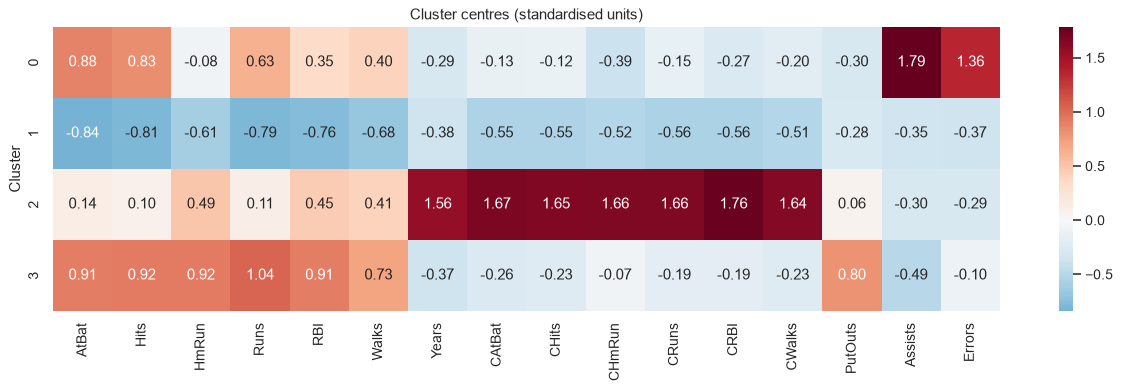

In [91]:
plt.figure(figsize=(14, 4.5))
sns.heatmap(pd.DataFrame(kmeans.cluster_centers_, columns=km_feats), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster centres (standardised units)"); plt.ylabel("Cluster"); plt.tight_layout(); plt.show()

In [92]:
profile = clustered.groupby("Cluster").agg(n=("Years", "size"), Years=("Years", "median"), Hits=("Hits", "median"), HmRun=("HmRun", "median"),
    CHits=("CHits", "median"), CHmRun=("CHmRun", "median"), PutOuts=("PutOuts", "median"), Assists=("Assists", "median"),
    Errors=("Errors", "median"), Salary_median=("Salary", "median"), Salary_mean=("Salary", "mean"))
profile

,n,Years,Hits,HmRun,CHits,CHmRun,PutOuts,Assists,Errors,Salary_median,Salary_mean
Cluster,,,,,,,,,,,
0,56,5.5,136.0,8.0,567.5,25.5,226.0,371.0,16.5,517.143,540.439
1,140,5.0,62.0,5.0,238.0,16.0,155.5,22.0,4.0,240.000,298.672
2,60,15.0,101.0,14.0,1776.0,209.5,205.5,32.0,5.0,775.000,896.657
3,66,6.0,142.5,18.0,560.5,59.5,325.0,12.0,7.0,625.000,654.525


In [93]:
for c in cat_cols:
    display(pd.crosstab(clustered.Cluster, clustered[c], normalize="index").round(2).add_prefix(f"{c}="))

League,League=A,League=N
Cluster,,
0,0.54,0.46
1,0.51,0.49
2,0.62,0.38
3,0.56,0.44


Division,Division=E,Division=W
Cluster,,
0,0.54,0.46
1,0.49,0.51
2,0.45,0.55
3,0.48,0.52


NewLeague,NewLeague=A,NewLeague=N
Cluster,,
0,0.54,0.46
1,0.54,0.46
2,0.58,0.42
3,0.55,0.45


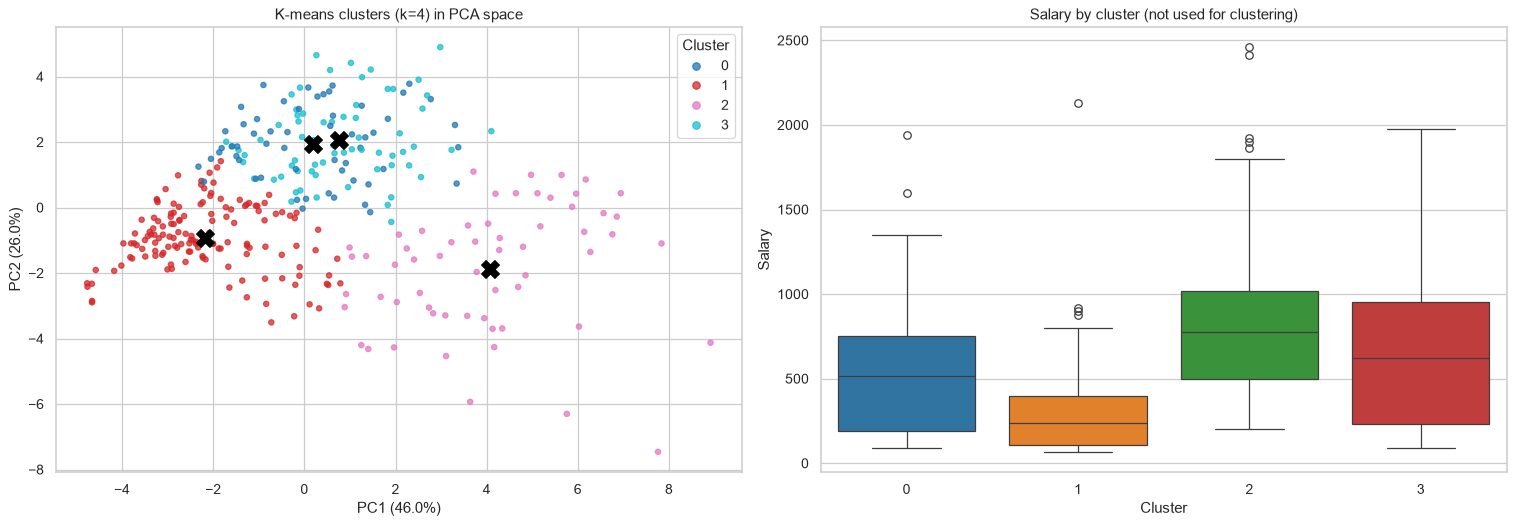

In [94]:
pca2 = PCA(n_components=2, random_state=SEED).fit(km_X)
P = pca2.transform(km_X); C = pca2.transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sc = axes[0].scatter(P[:, 0], P[:, 1], c=labels, cmap="tab10", s=18, alpha=.75)
axes[0].scatter(C[:, 0], C[:, 1], c="black", marker="X", s=200, label="centres"); axes[0].legend(*sc.legend_elements(), title="Cluster")
axes[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})"); axes[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
axes[0].set_title(f"K-means clusters (k={K_USER}) in PCA space")
sns.boxplot(data=clustered, x="Cluster", y="Salary", ax=axes[1], hue="Cluster", palette="tab10", legend=False); axes[1].set_title("Salary by cluster (not used for clustering)")
plt.tight_layout(); plt.show()

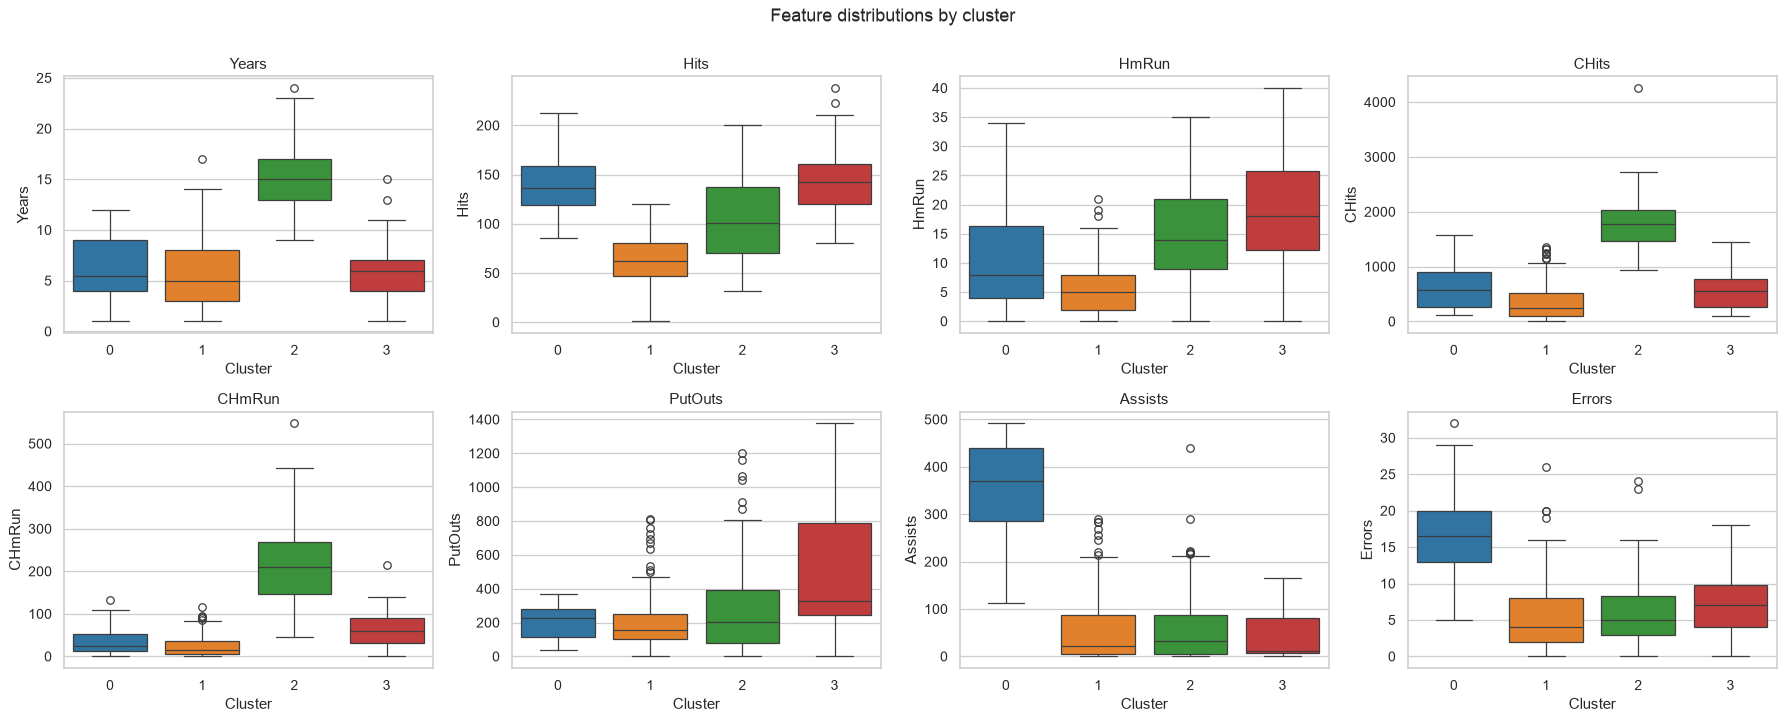

In [95]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), ["Years","Hits","HmRun","CHits","CHmRun","PutOuts","Assists","Errors"]):
    sns.boxplot(data=clustered, x="Cluster", y=c, ax=ax, hue="Cluster", palette="tab10", legend=False); ax.set_title(c)
plt.suptitle("Feature distributions by cluster", y=1.0); plt.tight_layout(); plt.show()

In [96]:
desc_rows = []
z_centers = pd.DataFrame(kmeans.cluster_centers_, columns=km_feats)
for k in range(K_USER):
    hi = z_centers.loc[k].sort_values(ascending=False)
    desc_rows.append({"cluster": k, "size": int((labels == k).sum()), "highest (z)": ", ".join(f"{i} {v:+.2f}" for i, v in hi.head(3).items()),
                      "lowest (z)": ", ".join(f"{i} {v:+.2f}" for i, v in hi.tail(3).items()), "median salary": clustered.loc[clustered.Cluster == k, "Salary"].median()})
pd.DataFrame(desc_rows).set_index("cluster")

,size,highest (z),lowest (z),median salary
cluster,,,,
0,56,"Assists +1.79, Errors +1.36, AtBat +0.88","Years -0.29, PutOuts -0.30, CHmRun -0.39",517.143
1,140,"PutOuts -0.28, Assists -0.35, Errors -0.37","Runs -0.79, Hits -0.81, AtBat -0.84",240.000
2,60,"CRBI +1.76, CAtBat +1.67, CRuns +1.66","PutOuts +0.06, Errors -0.29, Assists -0.30",775.000
3,66,"Runs +1.04, Hits +0.92, HmRun +0.92","CAtBat -0.26, Years -0.37, Assists -0.49",625.000


### 14.1 K-means from scratch (Lloyd's algorithm) vs scikit-learn

Scratch inertia = 2313.67 | sklearn inertia = 2313.60
Adjusted Rand index (scratch vs sklearn) = 0.994
scratch   0    1   2   3
sklearn                 
0        56    0   0   0
1         0  140   0   0
2         0    0   0  60
3         0    0  65   1


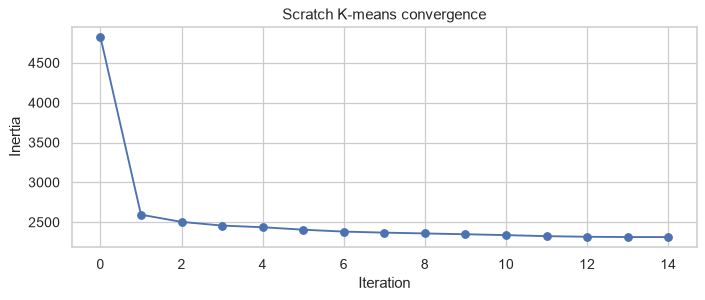

In [97]:
def kmeans_scratch(X, k, max_iter=300, tol=1e-6, seed=SEED):
    rng = np.random.default_rng(seed)
    centers = [X[rng.integers(len(X))]]
    for _ in range(1, k):
        d2 = np.min(((X[:, None, :] - np.array(centers)[None]) ** 2).sum(-1), axis=1)
        centers.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    centers = np.array(centers)
    history = []
    for it in range(max_iter):
        dist = ((X[:, None, :] - centers[None]) ** 2).sum(-1)
        lab = dist.argmin(1)
        new = np.array([X[lab == j].mean(0) if np.any(lab == j) else centers[j] for j in range(k)])
        history.append(dist[np.arange(len(X)), lab].sum())
        if np.linalg.norm(new - centers) < tol:
            break
        centers = new
    return lab, centers, history

best = min((kmeans_scratch(km_X, K_USER, seed=SEED + s) for s in range(20)), key=lambda r: r[2][-1])
lab_s, cen_s, hist_s = best
print(f"Scratch inertia = {hist_s[-1]:.2f} | sklearn inertia = {kmeans.inertia_:.2f}")
print(f"Adjusted Rand index (scratch vs sklearn) = {adjusted_rand_score(labels, lab_s):.3f}")
print(pd.crosstab(pd.Series(labels, name="sklearn"), pd.Series(lab_s, name="scratch")))
plt.figure(figsize=(8, 3.5)); plt.plot(hist_s, "o-"); plt.xlabel("Iteration"); plt.ylabel("Inertia"); plt.title("Scratch K-means convergence"); plt.tight_layout(); plt.show()

### 14.2 Effect of scaling

Cluster sizes without scaling: [31, 151, 56, 84] | with scaling: [56, 140, 60, 66]


unscaled,0,1,2,3
scaled,,,,
0,0,25,9,22
1,0,100,13,27
2,31,0,29,0
3,0,26,5,35


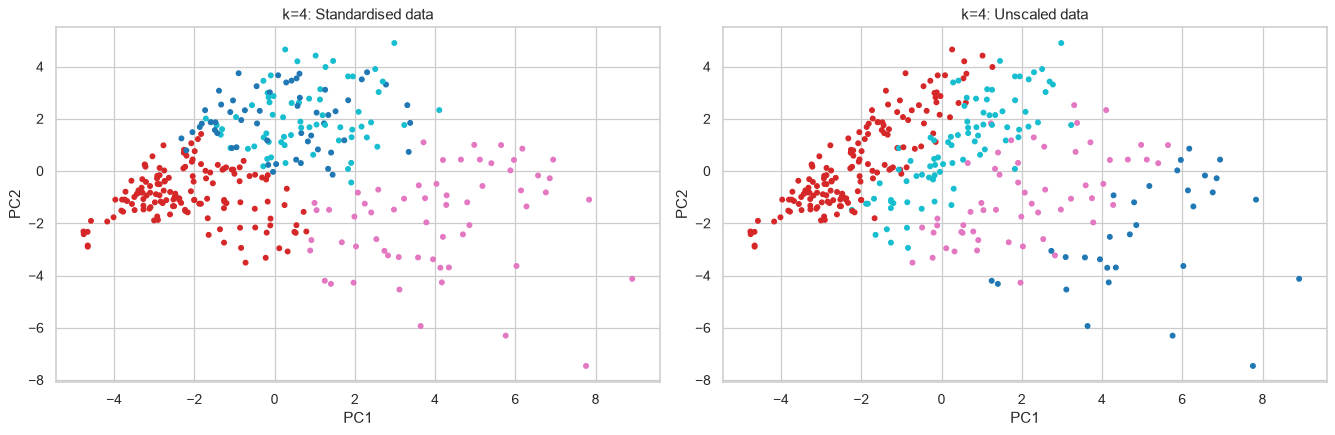

In [98]:
lab_raw = KMeans(n_clusters=K_USER, n_init=20, random_state=SEED).fit_predict(km_data)
print("Cluster sizes without scaling:", np.bincount(lab_raw).tolist(), "| with scaling:", np.bincount(labels).tolist())
display(pd.crosstab(pd.Series(labels, name="scaled"), pd.Series(lab_raw, name="unscaled")))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (lab, t) in zip(axes, [(labels, "Standardised data"), (lab_raw, "Unscaled data")]):
    ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="tab10", s=14); ax.set_title(f"k={K_USER}: {t}"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

Without scaling, large-magnitude career totals (CAtBat) dominate the Euclidean distance. Clusters are descriptive groupings of statistical profiles; they should not be read as official player types without external validation.

## 15. Nearest-Neighbour Classification (Experiment 6)

The dataset has no natural class label. An **engineered educational target** is created: `HighSalary = 1` if Salary exceeds the **training-set** median. Rows with missing Salary are excluded (the target cannot be observed), and Salary itself is excluded from the predictors.

In [99]:
lab_df = df.dropna(subset=["Salary"]).reset_index(drop=True)
X = lab_df.drop(columns=["Salary"])
y_cont = lab_df.Salary
X_train, X_test, s_train, s_test = train_test_split(X, y_cont, test_size=0.25, random_state=SEED,
                                                    stratify=pd.qcut(y_cont, 4, labels=False))
threshold = s_train.median()
y_train, y_test = (s_train > threshold).astype(int), (s_test > threshold).astype(int)
print(f"Training-median threshold = {threshold:.1f} (thousand USD)")
print("Train:", X_train.shape, y_train.value_counts().to_dict(), "| Test:", X_test.shape, y_test.value_counts().to_dict())

Training-median threshold = 425.0 (thousand USD)
Train: (197, 19) {0: 100, 1: 97} | Test: (66, 19) {0: 34, 1: 32}


In [100]:
num_feats = X.select_dtypes(include="number").columns.tolist()
cat_feats = X.select_dtypes(exclude="number").columns.tolist()
pre = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_feats),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), cat_feats)])
knn_pipe = Pipeline([("pre", pre), ("knn", KNeighborsClassifier())])
knn_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

In [101]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for k in range(1, 41, 2):
    for w in ["uniform", "distance"]:
        knn_pipe.set_params(knn__n_neighbors=k, knn__weights=w)
        cvs = cross_val_score(knn_pipe, X_train, y_train, cv=cv, scoring="accuracy")
        knn_pipe.fit(X_train, y_train)
        rows.append({"k": k, "weights": w, "train_acc": knn_pipe.score(X_train, y_train), "cv_acc": cvs.mean(), "cv_std": cvs.std()})
kres = pd.DataFrame(rows)
kres.pivot(index="k", columns="weights", values=["train_acc", "cv_acc"]).round(3)

train_acc           cv_acc        
weights  distance uniform distance uniform
k                                         
1             1.0   1.000    0.776   0.776
3             1.0   0.883    0.756   0.756
5             1.0   0.873    0.792   0.787
7             1.0   0.878    0.792   0.787
9             1.0   0.868    0.812   0.807
11            1.0   0.863    0.807   0.807
13            1.0   0.858    0.807   0.797
15            1.0   0.848    0.817   0.802
17            1.0   0.838    0.797   0.787
19            1.0   0.817    0.792   0.782
21            1.0   0.832    0.817   0.812
23            1.0   0.807    0.822   0.812
25            1.0   0.807    0.833   0.823
27            1.0   0.802    0.807   0.807
29            1.0   0.807    0.812   0.813
31            1.0   0.812    0.812   0.818
33            1.0   0.827    0.823   0.818
35            1.0   0.812    0.828   0.812
37            1.0   0.812    0.812   0.812
39            1.0   0.802    0.818   0.802

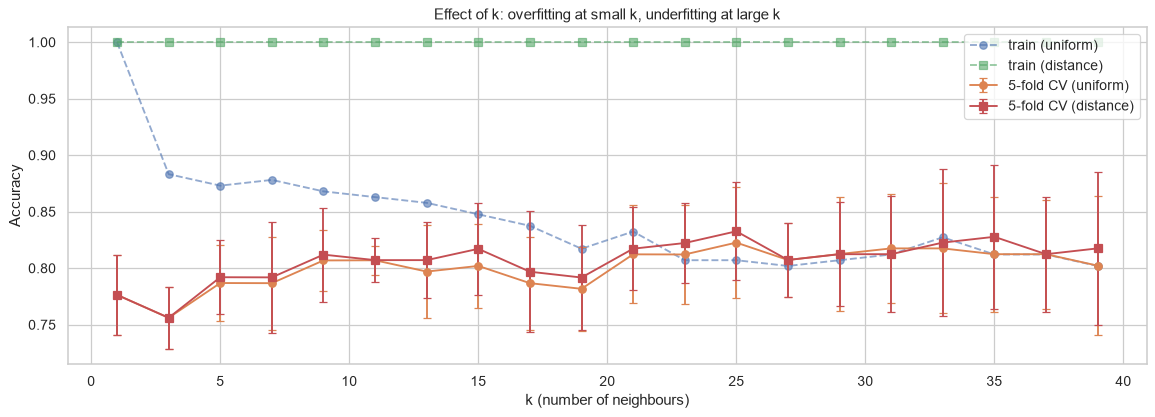

In [102]:
fig, ax = plt.subplots(figsize=(13, 4.8))
for w, m in [("uniform", "o"), ("distance", "s")]:
    d = kres[kres.weights == w]
    ax.plot(d.k, d.train_acc, m + "--", label=f"train ({w})", alpha=.6)
    ax.errorbar(d.k, d.cv_acc, yerr=d.cv_std, fmt=m + "-", capsize=3, label=f"5-fold CV ({w})")
ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("Accuracy"); ax.set_title("Effect of k: overfitting at small k, underfitting at large k"); ax.legend()
plt.tight_layout(); plt.show()

In [103]:
best_row = kres.loc[kres.cv_acc.idxmax()]
best_k, best_w = int(best_row.k), best_row.weights
print(f"Selected by CV on training data: k={best_k}, weights={best_w}, CV accuracy={best_row.cv_acc:.3f}")
knn_pipe.set_params(knn__n_neighbors=best_k, knn__weights=best_w).fit(X_train, y_train)
y_pred = knn_pipe.predict(X_test); y_prob = knn_pipe.predict_proba(X_test)[:, 1]

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
b_pred = baseline.predict(X_test)

def metrics(y, p, prob=None):
    out = {"accuracy": accuracy_score(y, p), "precision": precision_score(y, p, zero_division=0),
           "recall": recall_score(y, p, zero_division=0), "f1": f1_score(y, p, zero_division=0)}
    if prob is not None: out["roc_auc"] = roc_auc_score(y, prob)
    return out
pd.DataFrame({f"KNN (k={best_k})": metrics(y_test, y_pred, y_prob), "Baseline (majority)": metrics(y_test, b_pred)}).T.round(3)

Selected by CV on training data: k=25, weights=distance, CV accuracy=0.833


,accuracy,precision,recall,f1,roc_auc
KNN (k=25),0.818,0.778,0.875,0.824,0.923
Baseline (majority),0.515,0.000,0.000,0.000,NaN


In [104]:
print(classification_report(y_test, y_pred, target_names=['Low salary', 'High salary']))

              precision    recall  f1-score   support

  Low salary       0.87      0.76      0.81        34
 High salary       0.78      0.88      0.82        32

    accuracy                           0.82        66
   macro avg       0.82      0.82      0.82        66
weighted avg       0.82      0.82      0.82        66



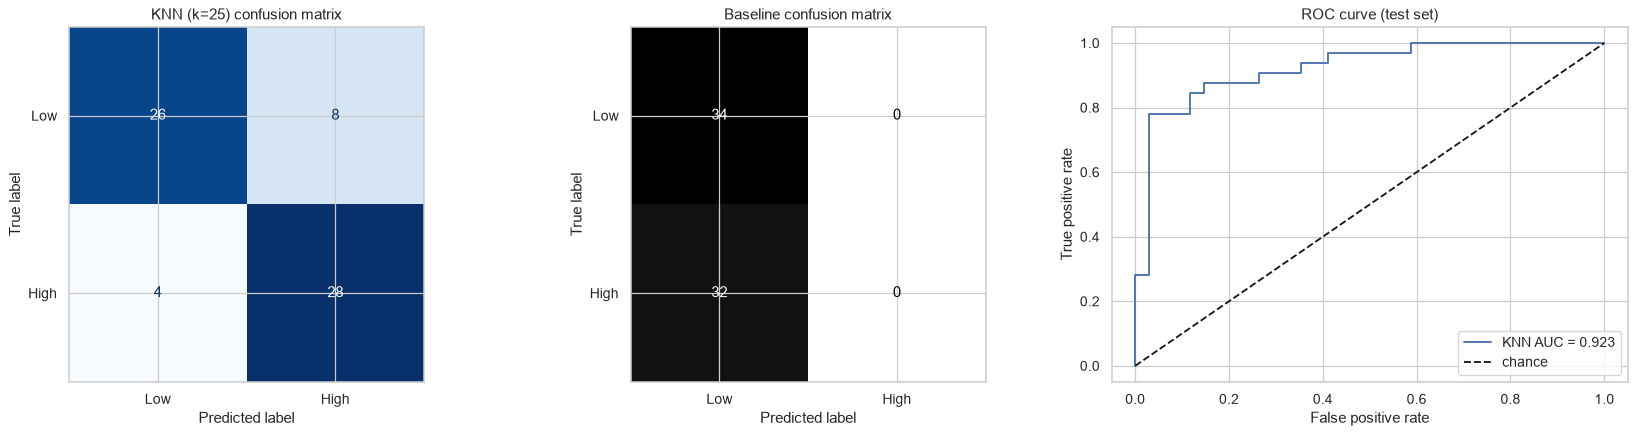

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Low", "High"]).plot(ax=axes[0], cmap="Blues", colorbar=False); axes[0].set_title(f"KNN (k={best_k}) confusion matrix")
ConfusionMatrixDisplay(confusion_matrix(y_test, b_pred), display_labels=["Low", "High"]).plot(ax=axes[1], cmap="Greys", colorbar=False); axes[1].set_title("Baseline confusion matrix")
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[2].plot(fpr, tpr, label=f"KNN AUC = {roc_auc_score(y_test, y_prob):.3f}"); axes[2].plot([0, 1], [0, 1], "k--", label="chance")
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate"); axes[2].set_title("ROC curve (test set)"); axes[2].legend()
plt.tight_layout(); plt.show()

In [106]:
test_rows = []
for k in [1, 3, 5, 7, 11, 15, 21, 31, 51]:
    p = Pipeline([("pre", pre), ("knn", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train)
    test_rows.append({"k": k, **metrics(y_test, p.predict(X_test), p.predict_proba(X_test)[:, 1])})
pd.DataFrame(test_rows).set_index("k").round(3)

,accuracy,precision,recall,f1,roc_auc
k,,,,,
1,0.803,0.771,0.844,0.806,0.804
3,0.879,0.875,0.875,0.875,0.936
5,0.848,0.867,0.812,0.839,0.923
7,0.864,0.848,0.875,0.862,0.909
11,0.803,0.788,0.812,0.800,0.910
15,0.788,0.737,0.875,0.800,0.911
21,0.818,0.778,0.875,0.824,0.917
31,0.848,0.806,0.906,0.853,0.912
51,0.864,0.829,0.906,0.866,0.914


In [107]:
no_scale = Pipeline([("pre", ColumnTransformer([("num", SimpleImputer(strategy="median"), num_feats),
                                               ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_feats)])),
                     ("knn", KNeighborsClassifier(n_neighbors=best_k, weights=best_w))]).fit(X_train, y_train)
print(f"Test accuracy WITHOUT scaling: {no_scale.score(X_test, y_test):.3f} | WITH scaling: {knn_pipe.score(X_test, y_test):.3f}")

Test accuracy WITHOUT scaling: 0.864 | WITH scaling: 0.818


In [108]:
manual_cm = pd.crosstab(pd.Series(y_test.values, name="actual"), pd.Series(y_pred, name="predicted"))
display(manual_cm)
TN, FP, FN, TP = manual_cm.values.ravel()
print(f"TN={TN} FP={FP} FN={FN} TP={TP}")
print(f"accuracy  = (TP+TN)/total = {(TP + TN) / manual_cm.values.sum():.3f}")
print(f"precision = TP/(TP+FP)    = {TP / (TP + FP):.3f}")
print(f"recall    = TP/(TP+FN)    = {TP / (TP + FN):.3f}")
print(f"specificity = TN/(TN+FP)  = {TN / (TN + FP):.3f}")

predicted,0,1
actual,,
0,26,8
1,4,28


TN=26 FP=8 FN=4 TP=28
accuracy  = (TP+TN)/total = 0.818
precision = TP/(TP+FP)    = 0.778
recall    = TP/(TP+FN)    = 0.875
specificity = TN/(TN+FP)  = 0.765


### 15.1 KNN from scratch (Euclidean distance, majority vote)

In [109]:
prep = knn_pipe.named_steps["pre"]
Xtr_s, Xte_s = prep.transform(X_train), prep.transform(X_test)

def knn_predict(Xtr, ytr, Xte, k=5):
    d = np.sqrt(((Xte[:, None, :] - Xtr[None, :, :]) ** 2).sum(axis=2))
    idx = np.argsort(d, axis=1)[:, :k]
    return np.array([np.bincount(v).argmax() for v in ytr[idx]])

for k in [1, 5, 15]:
    y_scr = knn_predict(Xtr_s, y_train.values, Xte_s, k=k)
    y_sk = KNeighborsClassifier(n_neighbors=k).fit(Xtr_s, y_train).predict(Xte_s)
    print(f"k={k:2d}: scratch accuracy={accuracy_score(y_test, y_scr):.3f} | sklearn accuracy={accuracy_score(y_test, y_sk):.3f} | identical predictions={np.mean(y_scr == y_sk)*100:.1f}%")

k= 1: scratch accuracy=0.803 | sklearn accuracy=0.803 | identical predictions=100.0%
k= 5: scratch accuracy=0.848 | sklearn accuracy=0.848 | identical predictions=100.0%
k=15: scratch accuracy=0.788 | sklearn accuracy=0.788 | identical predictions=100.0%


### 15.2 Three-class version: low / medium / high salary

Training tercile cut-offs: [250.  660.7] | train class counts: [65, 66, 66]


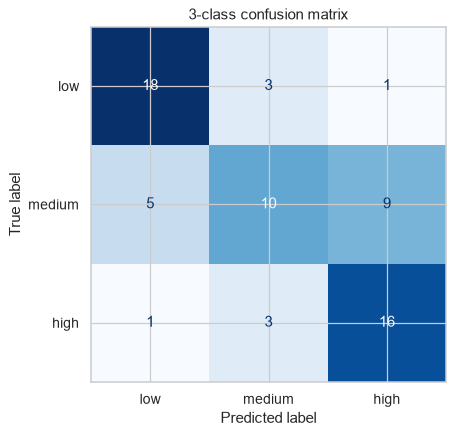

              precision    recall  f1-score   support

         low       0.75      0.82      0.78        22
      medium       0.62      0.42      0.50        24
        high       0.62      0.80      0.70        20

    accuracy                           0.67        66
   macro avg       0.66      0.68      0.66        66
weighted avg       0.66      0.67      0.65        66



In [110]:
cuts = s_train.quantile([1/3, 2/3]).values
to3 = lambda s: np.digitize(s, cuts)
y3_train, y3_test = to3(s_train), to3(s_test)
print("Training tercile cut-offs:", cuts.round(1), "| train class counts:", np.bincount(y3_train).tolist())
pipe3 = Pipeline([("pre", pre), ("knn", KNeighborsClassifier(n_neighbors=best_k, weights=best_w))]).fit(X_train, y3_train)
y3_pred = pipe3.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y3_test, y3_pred), display_labels=["low", "medium", "high"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("3-class confusion matrix"); plt.tight_layout(); plt.show()
print(classification_report(y3_test, y3_pred, target_names=["low", "medium", "high"]))

Imputation, encoding and scaling are fitted inside the pipeline on training folds only, and the salary threshold uses only the training median — preventing leakage. Classes are balanced by construction (median split), so accuracy is a reasonable metric; the majority-class baseline gives ~50%.

## 16. Additional Statistical Analysis

In [111]:
norm_rows = []
for c in num_cols:
    d = df[c].dropna()
    w, p = stats.shapiro(d)
    norm_rows.append({"variable": c, "Shapiro_W": w, "p_value": p, "normal_at_5%": p > .05})
d = np.log(df.Salary.dropna()); w, p = stats.shapiro(d)
norm_rows.append({"variable": "log(Salary)", "Shapiro_W": w, "p_value": p, "normal_at_5%": p > .05})
pd.DataFrame(norm_rows).set_index("variable")

,Shapiro_W,p_value,normal_at_5%
variable,,,
AtBat,0.970,3.369e-06,False
Hits,0.982,3.746e-04,False
HmRun,0.912,9.707e-13,False
Runs,0.973,9.769e-06,False
RBI,0.960,9.622e-08,False
Walks,0.960,9.862e-08,False
Years,0.927,1.834e-11,False
CAtBat,0.879,3.263e-15,False
CHits,0.868,5.889e-16,False


In [112]:
def mean_ci(x, conf=.95):
    x = x.dropna(); m, se = x.mean(), stats.sem(x)
    h = se * stats.t.ppf((1 + conf) / 2, len(x) - 1); return m, m - h, m + h

ci_rows = []
for c in ["Salary", "Hits", "HmRun", "Years", "Errors"]:
    m, lo, hi = mean_ci(df[c])
    ci_rows.append({"variable": c, "n": df[c].count(), "mean": m, "95% CI low": lo, "95% CI high": hi})
pd.DataFrame(ci_rows).set_index("variable").round(2)

,n,mean,95% CI low,95% CI high
variable,,,,
Salary,263,535.93,481.15,590.70
Hits,322,101.02,95.93,106.12
HmRun,322,10.77,9.82,11.73
Years,322,7.44,6.90,7.98
Errors,322,8.04,7.34,8.74


In [113]:
tests = []
logsal = np.log(df.Salary)
for c in ["League", "Division"]:
    a, b = [logsal[df[c] == lv].dropna() for lv in sorted(df[c].unique())]
    t, p = stats.ttest_ind(a, b, equal_var=False); lev = stats.levene(a, b).pvalue
    d_cohen = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    tests.append({"test": f"Welch t-test log(Salary) by {c}", "stat": t, "p_value": p, "Levene_p": lev, "effect (Cohen d)": d_cohen})
grp = [logsal[(df.Years > lo) & (df.Years <= hi)].dropna() for lo, hi in [(0, 3), (3, 6), (6, 10), (10, 25)]]
f, p = stats.f_oneway(*grp); h, ph = stats.kruskal(*grp)
tests.append({"test": "One-way ANOVA log(Salary) by experience band", "stat": f, "p_value": p})
tests.append({"test": "Kruskal-Wallis log(Salary) by experience band", "stat": h, "p_value": ph})
ct = pd.crosstab(df.League, df.Division); chi2, p, dof, exp = stats.chi2_contingency(ct)
tests.append({"test": "Chi-square League × Division", "stat": chi2, "p_value": p, "min expected count": exp.min()})
ct2 = pd.crosstab(df.Division, pd.cut(df.Years, [0, 3, 6, 10, 25])); chi2, p, dof, exp = stats.chi2_contingency(ct2)
tests.append({"test": "Chi-square Division × experience band", "stat": chi2, "p_value": p, "min expected count": exp.min()})
pd.DataFrame(tests).set_index("test").round(4)

,stat,p_value,Levene_p,effect (Cohen d),min expected count
test,,,,,
Welch t-test log(Salary) by League,0.104,0.917,0.853,0.013,NaN
Welch t-test log(Salary) by Division,2.448,0.015,0.442,0.302,NaN
One-way ANOVA log(Salary) by experience band,77.425,0.000,NaN,NaN,NaN
Kruskal-Wallis log(Salary) by experience band,116.925,0.000,NaN,NaN,NaN
Chi-square League × Division,0.000,1.000,NaN,NaN,71.674
Chi-square Division × experience band,3.720,0.293,NaN,NaN,32.180


In [114]:
ols_df = fe.dropna(subset=["Salary"])
m1 = sm.OLS(np.log(ols_df.Salary), sm.add_constant(ols_df[["Years"]])).fit()
print(m1.summary().tables[1]); print(f"R² = {m1.rsquared:.3f}")
m2 = sm.OLS(np.log(ols_df.Salary), sm.add_constant(np.log(ols_df[["CHits"]]))).fit()
print(m2.summary().tables[1]); print(f"R² = {m2.rsquared:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.1984      0.085     61.438      0.000       5.032       5.365
Years          0.0997      0.010     10.294      0.000       0.081       0.119
R² = 0.289
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.3557      0.216     10.895      0.000       1.930       2.781
CHits          0.5845      0.035     16.780      0.000       0.516       0.653
R² = 0.519


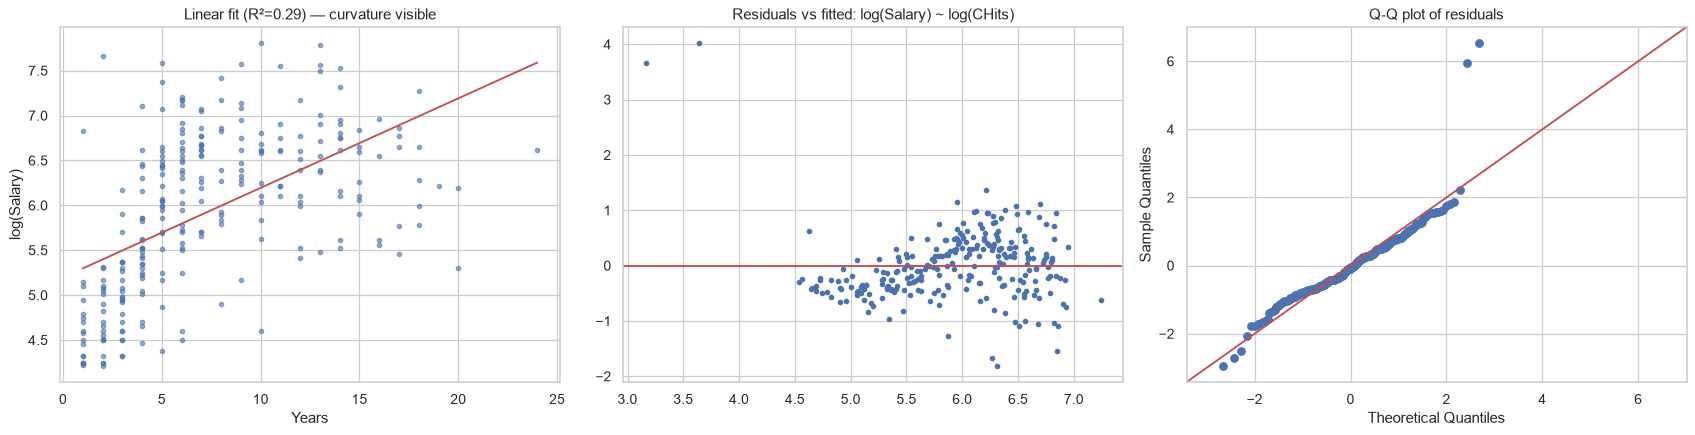

In [115]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
xs = np.linspace(ols_df.Years.min(), ols_df.Years.max(), 100)
axes[0].scatter(ols_df.Years, np.log(ols_df.Salary), s=12, alpha=.6); axes[0].plot(xs, m1.params.iloc[0] + m1.params.iloc[1] * xs, "r")
axes[0].set_xlabel("Years"); axes[0].set_ylabel("log(Salary)"); axes[0].set_title(f"Linear fit (R²={m1.rsquared:.2f}) — curvature visible")
axes[1].scatter(m2.fittedvalues, m2.resid, s=12); axes[1].axhline(0, c="r"); axes[1].set_title("Residuals vs fitted: log(Salary) ~ log(CHits)")
sm.qqplot(m2.resid, line="45", fit=True, ax=axes[2]); axes[2].set_title("Q-Q plot of residuals")
plt.tight_layout(); plt.show()

In [116]:
mlr_feats = ["AtBat","Hits","HmRun","Runs","RBI","Walks","Years","CAtBat","CHits","CHmRun","CRuns","CRBI","CWalks","PutOuts","Assists","Errors"]
m3 = sm.OLS(np.log(ols_df.Salary), sm.add_constant(ols_df[mlr_feats])).fit()
print(f"Multiple regression log(Salary) ~ all numeric: R²={m3.rsquared:.3f}, adj R²={m3.rsquared_adj:.3f}, F p-value={m3.f_pvalue:.2e}")
Xv = sm.add_constant(ols_df[mlr_feats])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=mlr_feats).sort_values(ascending=False)
vif.to_frame("VIF").T.round(1)

Multiple regression log(Salary) ~ all numeric: R²=0.543, adj R²=0.513, F p-value=2.47e-33


,CHits,CAtBat,CRuns,CRBI,CHmRun,Hits,AtBat,CWalks,Runs,RBI,Years,HmRun,Walks,Assists,Errors,PutOuts
VIF,495.7,250.1,158.7,131.2,46.3,30.1,22.5,19.7,15.1,11.7,9.1,7.6,4.1,2.7,2.2,1.2


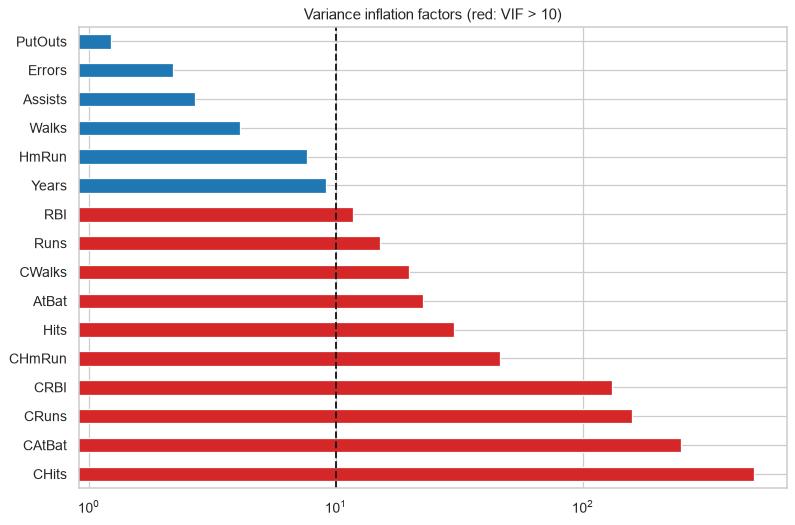

In [117]:
vif.plot.barh(figsize=(9, 6), color=np.where(vif > 10, "tab:red", "tab:blue")); plt.axvline(10, c="k", ls="--")
plt.xscale("log"); plt.title("Variance inflation factors (red: VIF > 10)"); plt.tight_layout(); plt.show()

## 17. Principal Component Analysis

In [118]:
pca_feats = mlr_feats
Xp = StandardScaler().fit_transform(df[pca_feats])
pca = PCA(random_state=SEED).fit(Xp)
evr = pd.DataFrame({"explained_var_ratio": pca.explained_variance_ratio_, "cumulative": np.cumsum(pca.explained_variance_ratio_),
                    "eigenvalue": pca.explained_variance_}, index=[f"PC{i+1}" for i in range(len(pca_feats))])
evr.T.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
explained_var_ratio,0.460,0.260,0.103,0.054,0.042,0.030,0.016,0.011,0.008,0.006,0.004,0.003,0.002,0.001,0.000,0.000
cumulative,0.460,0.721,0.824,0.878,0.920,0.950,0.965,0.977,0.985,0.990,0.994,0.997,0.999,1.000,1.000,1.000
eigenvalue,7.389,4.179,1.659,0.862,0.675,0.476,0.252,0.183,0.126,0.094,0.060,0.050,0.025,0.014,0.005,0.001


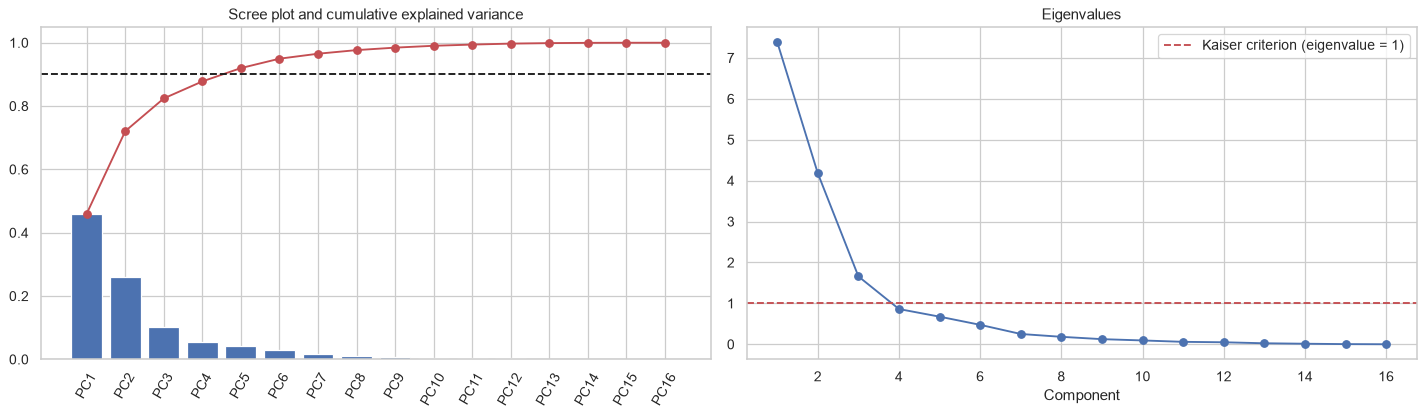

Components needed for 80% / 90% variance: 3 / 5


In [119]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].bar(evr.index, evr.explained_var_ratio); axes[0].plot(evr.index, evr.cumulative, "ro-"); axes[0].axhline(.9, ls="--", c="k")
axes[0].set_title("Scree plot and cumulative explained variance"); axes[0].tick_params(axis="x", rotation=60)
axes[1].plot(range(1, len(evr) + 1), evr.eigenvalue, "o-"); axes[1].axhline(1, c="r", ls="--", label="Kaiser criterion (eigenvalue = 1)")
axes[1].set_title("Eigenvalues"); axes[1].set_xlabel("Component"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Components needed for 80% / 90% variance:", int(np.argmax(evr.cumulative >= .8) + 1), "/", int(np.argmax(evr.cumulative >= .9) + 1))

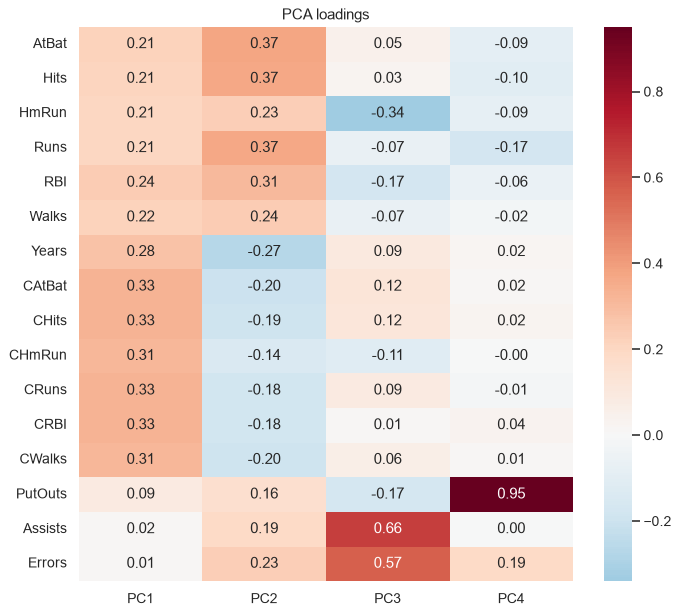

,PC1,PC2,PC3,PC4
AtBat,0.215,0.371,0.049,-0.089
Hits,0.210,0.367,0.031,-0.105
HmRun,0.208,0.232,-0.340,-0.086
Runs,0.207,0.368,-0.067,-0.169
RBI,0.244,0.305,-0.173,-0.062
Walks,0.217,0.242,-0.066,-0.023
Years,0.279,-0.269,0.093,0.021
CAtBat,0.327,-0.200,0.122,0.018
CHits,0.327,-0.190,0.118,0.024
CHmRun,0.311,-0.140,-0.115,-0.001


In [120]:
loadings = pd.DataFrame(pca.components_[:4].T, index=pca_feats, columns=["PC1", "PC2", "PC3", "PC4"])
plt.figure(figsize=(8, 7)); sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.title("PCA loadings"); plt.tight_layout(); plt.show()
loadings.round(3)

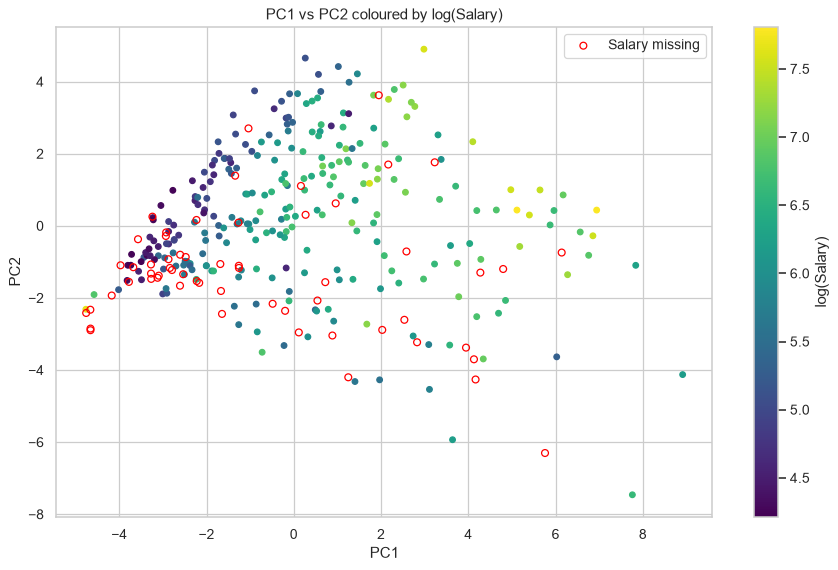

In [121]:
S = pca.transform(Xp)
plt.figure(figsize=(10, 6.5))
sc = plt.scatter(S[:, 0], S[:, 1], c=np.log(df.Salary), cmap="viridis", s=20)
plt.scatter(S[df.Salary.isna(), 0], S[df.Salary.isna(), 1], facecolors="none", edgecolors="red", s=30, label="Salary missing")
plt.colorbar(sc, label="log(Salary)"); plt.legend()
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PC1 vs PC2 coloured by log(Salary)")
plt.tight_layout(); plt.show()

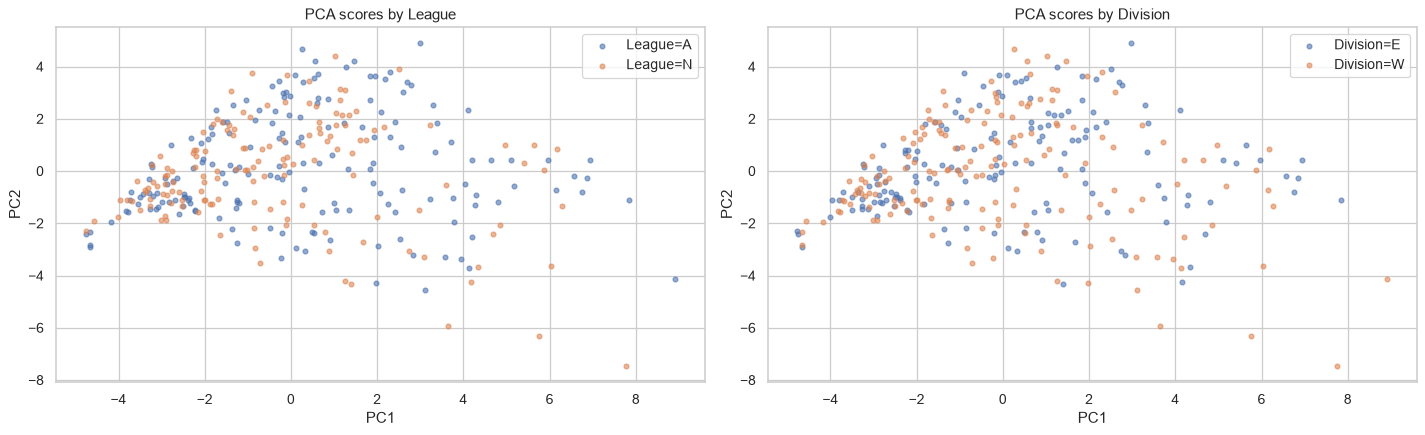

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, c in zip(axes, ["League", "Division"]):
    for lv in sorted(df[c].unique()):
        sel = (df[c] == lv).values; ax.scatter(S[sel, 0], S[sel, 1], s=15, alpha=.6, label=f"{c}={lv}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"PCA scores by {c}"); ax.legend()
plt.tight_layout(); plt.show()

## 18. Visualization Gallery

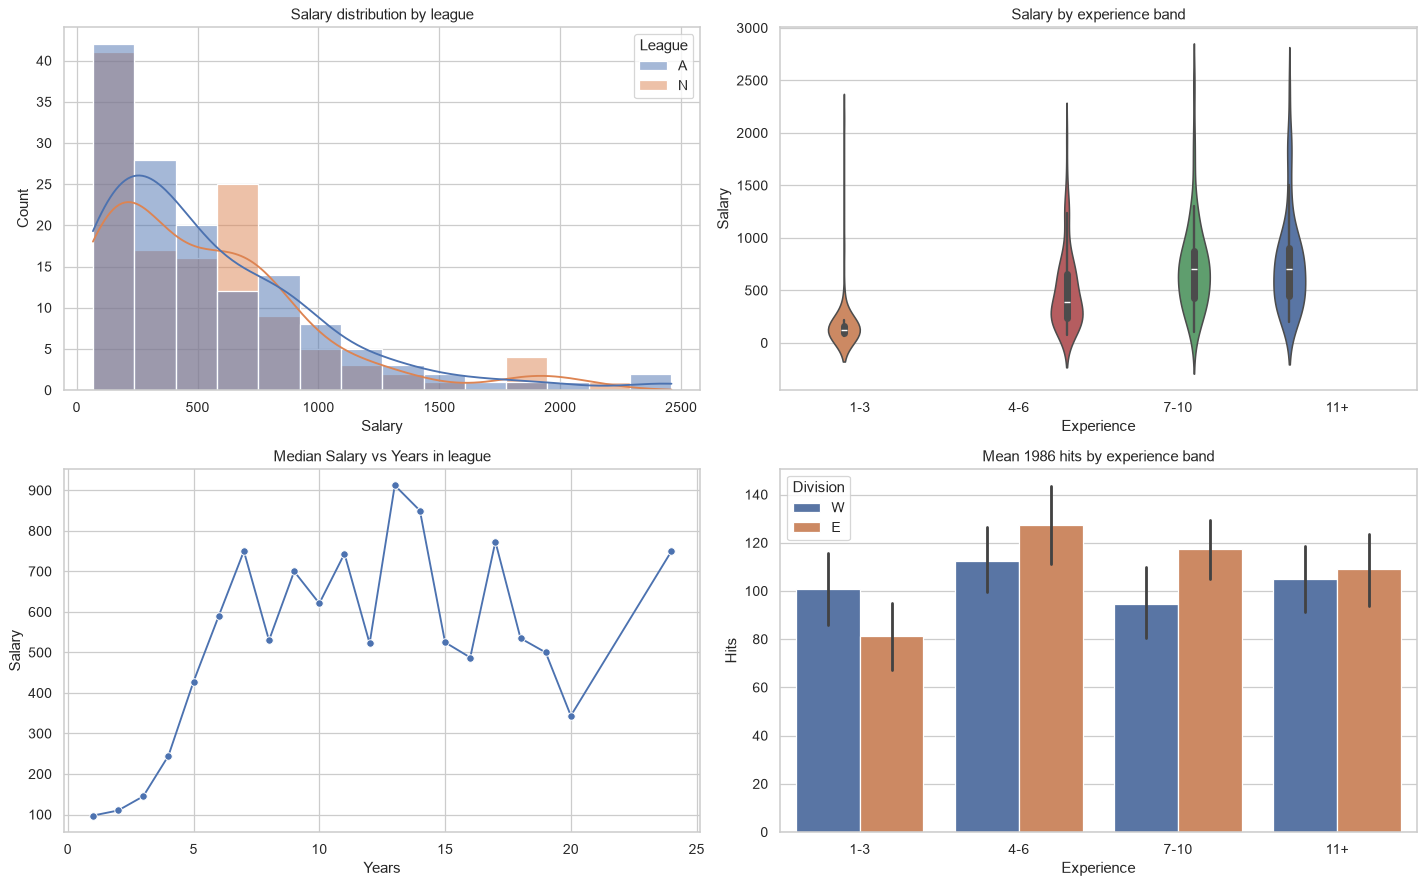

In [123]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.histplot(data=df, x="Salary", hue="League", kde=True, ax=axes[0, 0]); axes[0, 0].set_title("Salary distribution by league")
sns.violinplot(data=dfp, x="Experience", y="Salary", ax=axes[0, 1], hue="Experience", legend=False); axes[0, 1].set_title("Salary by experience band")
sns.lineplot(data=df, x="Years", y="Salary", estimator="median", errorbar=None, marker="o", ax=axes[1, 0]); axes[1, 0].set_title("Median Salary vs Years in league")
sns.barplot(data=dfp, x="Experience", y="Hits", hue="Division", ax=axes[1, 1]); axes[1, 1].set_title("Mean 1986 hits by experience band")
plt.tight_layout(); plt.show()

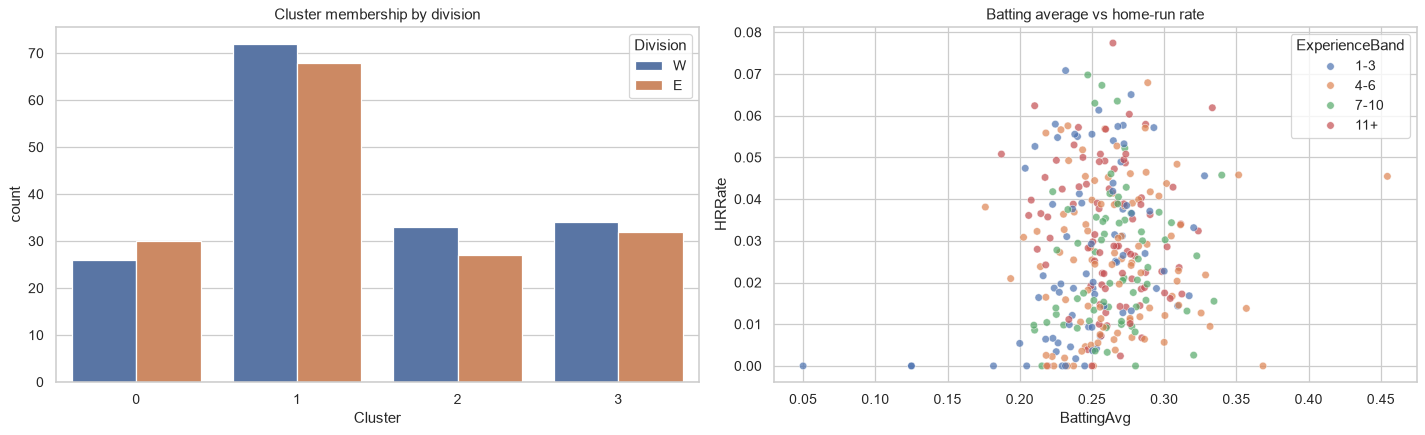

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=clustered, x="Cluster", hue="Division", ax=axes[0]); axes[0].set_title("Cluster membership by division")
sns.scatterplot(data=fe, x="BattingAvg", y="HRRate", hue="ExperienceBand", alpha=.7, ax=axes[1]); axes[1].set_title("Batting average vs home-run rate")
plt.tight_layout(); plt.show()

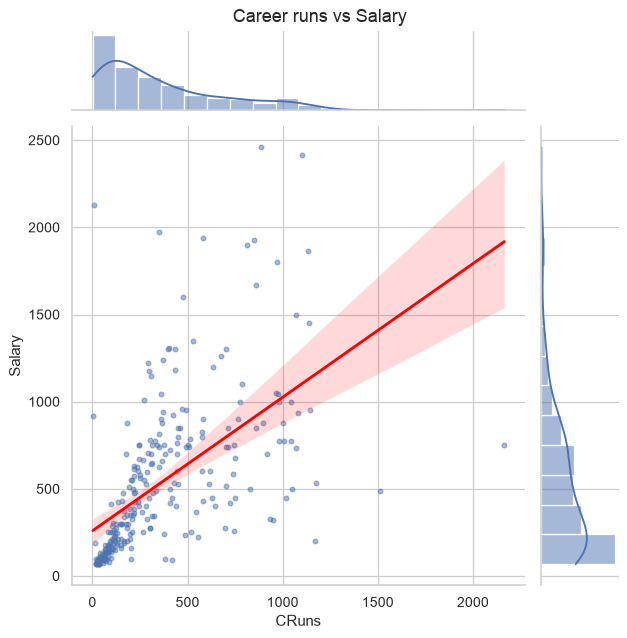

In [125]:
g = sns.jointplot(data=df, x="CRuns", y="Salary", kind="reg", height=7, scatter_kws={"s": 14, "alpha": .5}, line_kws={"color": "red"})
g.figure.suptitle("Career runs vs Salary", y=1.01); plt.show()

In [126]:
summary = pd.Series({
  "Rows × columns": f"{df.shape[0]} × {df.shape[1]}",
  "Numeric / categorical": f"{len(num_cols)} / {len(cat_cols)}",
  "Missing Salary": f"{df.Salary.isna().sum()} ({df.Salary.isna().mean():.1%})",
  "Median / mean Salary": f"{df.Salary.median():.1f} / {df.Salary.mean():.1f}",
  "Strongest Salary correlate": f"{sal_corr.idxmax()} (r={sal_corr.max():.2f})",
  "Rows with any IQR outlier": f"{flags['IQR (1.5)'].any(axis=1).sum()}",
  "Mahalanobis multivariate outliers": f"{mv_out.sum()}",
  "MICE pooled mean Salary (95% CI)": f"{Q:.1f} [{ci[0]:.1f}, {ci[1]:.1f}]",
  f"K-means k={K_USER} silhouette": f"{silhouette_score(km_X, labels):.3f}",
  "Best KNN k (CV)": f"{best_k} ({best_w})",
  "KNN test accuracy / AUC": f"{accuracy_score(y_test, y_pred):.3f} / {roc_auc_score(y_test, y_prob):.3f}",
  "Baseline test accuracy": f"{accuracy_score(y_test, b_pred):.3f}",
  "PCs for 90% variance": f"{int(np.argmax(evr.cumulative >= .9) + 1)}",
  "Max VIF": f"{vif.max():.0f} ({vif.idxmax()})"}, name="value")
print("=" * 60); print("EDA SUMMARY"); print("=" * 60)
for k, v in summary.items():
    print(f"- {k}: {v}")

EDA SUMMARY
- Rows × columns: 322 × 20
- Numeric / categorical: 17 / 3
- Missing Salary: 59 (18.3%)
- Median / mean Salary: 425.0 / 535.9
- Strongest Salary correlate: CRBI (r=0.57)
- Rows with any IQR outlier: 106
- Mahalanobis multivariate outliers: 21
- MICE pooled mean Salary (95% CI): 524.9 [474.3, 575.6]
- K-means k=4 silhouette: 0.295
- Best KNN k (CV): 25 (distance)
- KNN test accuracy / AUC: 0.818 / 0.923
- Baseline test accuracy: 0.515
- PCs for 90% variance: 5
- Max VIF: 496 (CHits)
